# **Core Pipelines=> Summary**

Detailed cell organization
01. Data Import & Environment Setup
- Cell 01 — Google Drive Mount
- Cell 02 — Import Required Libraries
- Cell 03 — Configure Project Paths
- Cell 04 — Configure Reproducibility
- Cell 05 — Load Excel Dataset
- Cell 06 — Confirm Dataset Loading
02. Dataset Inspection
- Cell 07 — Display Dataset
- Cell 08 — Dataset Shape
- Cell 09 — Column Names
- Cell 10 — Data Types
- Cell 11 — Statistical Summary
- Cell 12 — Initial Dataset Overview
03. Exploratory Data Analysis
- Cell 13 — Missing Values Visualization
- Cell 14 — Duplicate Records
- Cell 15 — City and Ward Distribution
- Cell 16 — Temporal Coverage
- Cell 17 — Dengue Case Distribution
- Cell 18 — Monthly Seasonality
- Cell 19 — Yearly Dengue Trends
- Cell 20 — Weather Distribution
- Cell 21 — Weather vs Dengue Relationships
- Cell 22 — Correlation Heatmap
04. Data Quality & Validation
- Cell 23 — Validate Required Columns
- Cell 24 — Validate Date Records
- Cell 25 — Validate Weekly Continuity
- Cell 26 — Validate City-Ward Identifiers
- Cell 27 — Validate Static Ward Features
- Cell 28 — Investigate Weather Granularity
05. Data Preprocessing
- Cell 29 — Create Working DataFrame
- Cell 30 — Standardize Column Names and Types
- Cell 31 — Handle Missing Values (if necessary)
- Cell 32 — Handle Duplicate Records (if necessary)
- Cell 33 — Validate Target Values
- Cell 34 — Sort Time-Series Records
- Cell 35 — Generate Stable Ward Identifiers
- Cell 36 — Save Processed Dataset
06. Feature Engineering
- Cell 37 — Calendar Features
- Cell 38 — Dengue Lag Features
- Cell 39 — Weather Lag Features
- Cell 40 — Rolling Average Features
- Cell 41 — Cumulative Rainfall Features
- Cell 42 — Ward Vulnerability Features
- Cell 43 — Seasonal Encoding
- Cell 44 — Forecast Horizon Target Generation
- Cell 45 — Remove Invalid Lag Records
- Cell 46 — Feature Validation and Leakage Checks
07. Train-Validation-Test Preparation
- Cell 47 — Define Forecasting Strategy
- Cell 48 — Define Chronological Split Dates
- Cell 49 — Create Horizon-Specific Datasets
- Cell 50 — Prepare H2 Dataset
- Cell 51 — Prepare H3 Dataset
- Cell 52 — Prepare H4 Dataset
- Cell 53 — Validate Split Integrity
08. Baseline Model Development
- Cell 54 — Latest Observation Baseline
- Cell 55 — Seasonal Baseline
- Cell 56 — Baseline Predictions
- Cell 57 — Calculate Baseline Metrics
- Cell 58 — Compare Baseline Horizons
- Cell 59 — Save Baseline Results
09. ML Model Training
- Cell 60 — Configure Candidate Models
- Cell 61 — HistGradientBoosting Model
- Cell 62 — Random Forest Model
- Cell 63 — XGBoost Model (if suitable)
- Cell 64 — Train H2 Models
- Cell 65 — Train H3 Models
- Cell 66 — Train H4 Models
- Cell 67 — Save Training Results
- Cell 68 — Training Error Handling
10. Hyperparameter Tuning
- Cell 69 — Define Parameter Search
- Cell 70 — Configure Time-Series Validation
- Cell 71 — Tune Candidate Models
- Cell 72 — Select Best Parameters
- Cell 73 — Retrain Selected Models
- Cell 74 — Save Tuning Results
11. Model Evaluation & Comparison
- Cell 75 — Generate Test Predictions
- Cell 76 — Calculate MAE
- Cell 77 — Calculate RMSE
- Cell 78 — Calculate Poisson Deviance
- Cell 79 — Evaluate Outbreak Detection
- Cell 80 — Compare H2, H3 and H4
- Cell 81 — Actual vs Predicted Visualization
- Cell 82 — Residual Analysis
- Cell 83 — Final Model Comparison
12. Model Interpretation
- Cell 84 — Feature Importance
- Cell 85 — Weather Feature Contribution
- Cell 86 — Vulnerability Feature Contribution
- Cell 87 — Model Error Investigation
- Cell 88 — Interpretation Summary
13. Model Export & Serialization
- Cell 89 — Create Export Directories
- Cell 90 — Export H2 Model
- Cell 91 — Export H3 Model
- Cell 92 — Export H4 Model
- Cell 93 — Export Model Metadata
- Cell 94 — Export Feature Schema and Configuration
14. Final Prediction Pipeline Testing
- Cell 95 — Load Exported Models
- Cell 96 — Validate Input Features
- Cell 97 — Generate H2 Prediction
- Cell 98 — Generate H3 Prediction
- Cell 99 — Generate H4 Prediction
- Cell 100 — Validate Prediction Outputs

# **1.Data Import & Environment Setup**

## Cell 01 — Google Drive Mount

In [50]:

# ============================================================
# AI FOR URBAN DENGUE OUTBREAK
# SECTION 01: DATA IMPORT & ENVIRONMENT SETUP
# CELL 01: GOOGLE DRIVE MOUNT
# ============================================================

from google.colab import drive

drive.mount("/content/drive")

print("Google Drive connected successfully!")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive connected successfully!


## CELL 02: IMPORT REQUIRED LIBRARIES

In [51]:

# ============================================================
# CELL 02: IMPORT REQUIRED LIBRARIES
# ============================================================

import os
import json
import warnings
import logging

from pathlib import Path
from datetime import datetime

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# Ignore unnecessary warnings during initial exploration
warnings.filterwarnings("ignore")

# Visualization configuration
sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 110

# Reproducibility
RANDOM_STATE = 42

print("All required libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)


All required libraries imported successfully!
Pandas version: 2.2.3
NumPy version: 2.4.6


## **Cell 03 — Specify dataset path**

In [52]:
DATASET_PATH = (
    "/content/drive/MyDrive/hackathon_preli_dataset.xlsx"
)

print("Dataset path configured.")

Dataset path configured.


## Cell 04 — Load dataset

In [53]:
df = pd.read_excel(DATASET_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (31320, 12)


## Cell 05 — Verify loading

In [54]:
display(df.head())

print("\nDataset dimensions:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

,date,city,ward_id,population_density_sqkm,water_logging_risk_index,sanitation_score,avg_temp_c,max_temp_c,min_temp_c,rainfall_mm,relative_humidity_pct,dengue_cases
0,2016-01-04,Chattogram,CCC_Ward_01,64024,0.87,0.46,18.32,26.54,14.13,0.00,59.24,0
1,2016-01-11,Chattogram,CCC_Ward_01,64024,0.87,0.46,21.24,26.95,16.71,2.02,61.63,0
2,2016-01-18,Chattogram,CCC_Ward_01,64024,0.87,0.46,20.94,25.05,14.84,0.00,60.50,0
3,2016-01-25,Chattogram,CCC_Ward_01,64024,0.87,0.46,21.75,27.20,17.58,1.52,69.02,0
4,2016-02-01,Chattogram,CCC_Ward_01,64024,0.87,0.46,22.39,28.02,16.98,0.94,60.50,0



Dataset dimensions: (31320, 12)

Column names:
['date', 'city', 'ward_id', 'population_density_sqkm', 'water_logging_risk_index', 'sanitation_score', 'avg_temp_c', 'max_temp_c', 'min_temp_c', 'rainfall_mm', 'relative_humidity_pct', 'dengue_cases']


# **2. Dataset Inspection**

## CELL : 06 --> Dataset Overview

In [55]:
print("DATASET OVERVIEW")
print("=" * 50)

print("Total Rows       :", df.shape[0])
print("Total Columns    :", df.shape[1])
print("Memory Usage     :", round(df.memory_usage(deep=True).sum() / (1024 ** 2), 2), "MB")

print("\nDataset Preview:")
display(df.head(10))

DATASET OVERVIEW
Total Rows       : 31320
Total Columns    : 12
Memory Usage     : 5.98 MB

Dataset Preview:


,date,city,ward_id,population_density_sqkm,water_logging_risk_index,sanitation_score,avg_temp_c,max_temp_c,min_temp_c,rainfall_mm,relative_humidity_pct,dengue_cases
0,2016-01-04,Chattogram,CCC_Ward_01,64024,0.87,0.46,18.32,26.54,14.13,0.00,59.24,0
1,2016-01-11,Chattogram,CCC_Ward_01,64024,0.87,0.46,21.24,26.95,16.71,2.02,61.63,0
2,2016-01-18,Chattogram,CCC_Ward_01,64024,0.87,0.46,20.94,25.05,14.84,0.00,60.50,0
3,2016-01-25,Chattogram,CCC_Ward_01,64024,0.87,0.46,21.75,27.20,17.58,1.52,69.02,0
4,2016-02-01,Chattogram,CCC_Ward_01,64024,0.87,0.46,22.39,28.02,16.98,0.94,60.50,0
5,2016-02-08,Chattogram,CCC_Ward_01,64024,0.87,0.46,24.55,28.48,19.81,4.17,49.88,0
6,2016-02-15,Chattogram,CCC_Ward_01,64024,0.87,0.46,23.56,30.11,18.51,8.19,52.70,0
7,2016-02-22,Chattogram,CCC_Ward_01,64024,0.87,0.46,22.66,29.88,19.23,3.61,60.54,0
8,2016-02-29,Chattogram,CCC_Ward_01,64024,0.87,0.46,25.22,29.47,19.23,5.89,55.06,0
9,2016-03-07,Chattogram,CCC_Ward_01,64024,0.87,0.46,25.71,31.31,21.56,0.00,64.79,0


## CELL : 07 --> Column Information

In [56]:
# ============================================================
# CELL : 07 --> Column Information
# ============================================================

print("COLUMN INFORMATION")
print("=" * 50)

df.info()

COLUMN INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31320 entries, 0 to 31319
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   date                      31320 non-null  datetime64[ns]
 1   city                      31320 non-null  object        
 2   ward_id                   31320 non-null  object        
 3   population_density_sqkm   31320 non-null  int64         
 4   water_logging_risk_index  31320 non-null  float64       
 5   sanitation_score          31320 non-null  float64       
 6   avg_temp_c                31320 non-null  float64       
 7   max_temp_c                31320 non-null  float64       
 8   min_temp_c                31320 non-null  float64       
 9   rainfall_mm               31320 non-null  float64       
 10  relative_humidity_pct     31320 non-null  float64       
 11  dengue_cases              31320 non-null  int64         
dtyp

## CELL : 08 --> Statistical Summary

In [57]:
# ============================================================
# CELL : 08 --> Statistical Summary
# ============================================================

print("NUMERICAL STATISTICAL SUMMARY")
print("=" * 50)

display(df.describe().T)

NUMERICAL STATISTICAL SUMMARY


,count,mean,min,25%,50%,75%,max,std
date,31320,2020-12-31 12:00:00,2016-01-04 00:00:00,2018-07-02 00:00:00,2020-12-31 12:00:00,2023-07-03 00:00:00,2025-12-29 00:00:00,NaN
population_density_sqkm,31320.0,43157.733333,18314.0,30573.5,42854.0,54168.25,74252.0,14865.377799
water_logging_risk_index,31320.0,0.579333,0.22,0.3775,0.545,0.82,0.94,0.237903
sanitation_score,31320.0,0.554667,0.25,0.38,0.57,0.7125,0.88,0.191597
avg_temp_c,31320.0,26.922804,15.74,22.88,26.85,31.0225,37.51,4.482042
max_temp_c,31320.0,31.889061,23.12,27.85,31.505,35.99,40.79,4.516627
min_temp_c,31320.0,21.949425,13.06,18.0,21.67,25.97,31.64,4.527965
rainfall_mm,31320.0,35.630268,0.0,0.92,8.37,59.42,268.83,50.237519
relative_humidity_pct,31320.0,71.176132,41.84,60.4675,68.22,83.98,99.0,12.96861
dengue_cases,31320.0,2.636398,0.0,0.0,0.0,4.0,41.0,4.607737


## CELL : 09 --> Categorical Column Summary

In [58]:
# ============================================================
# CELL : 09 --> Categorical Column Summary
# ============================================================

categorical_columns = df.select_dtypes(include=["object", "category"]).columns

print("CATEGORICAL COLUMN SUMMARY")
print("=" * 50)

for column in categorical_columns:
    print(f"\nColumn: {column}")
    print("Unique Values:", df[column].nunique())
    print("Sample Values:", df[column].unique()[:15])

CATEGORICAL COLUMN SUMMARY

Column: city
Unique Values: 5
Sample Values: ['Chattogram' 'Dhaka North' 'Dhaka South' 'Gazipur' 'Narayanganj']

Column: ward_id
Unique Values: 60
Sample Values: ['CCC_Ward_01' 'CCC_Ward_02' 'CCC_Ward_03' 'CCC_Ward_04' 'CCC_Ward_05'
 'CCC_Ward_06' 'CCC_Ward_07' 'CCC_Ward_08' 'CCC_Ward_09' 'CCC_Ward_10'
 'DNCC_Ward_01' 'DNCC_Ward_02' 'DNCC_Ward_03' 'DNCC_Ward_04'
 'DNCC_Ward_05']


## CELL : 10 --> Date Range Inspection

In [59]:
print("DATE RANGE INSPECTION")
print("=" * 50)

df["date"] = pd.to_datetime(df["date"])

print("Starting Date :", df["date"].min())
print("Ending Date   :", df["date"].max())

print("Total Unique Dates:", df["date"].nunique())

print("First 5 Dates:")
display(df["date"].drop_duplicates().sort_values().head())

print("\nLast 5 Dates:")
display(df["date"].drop_duplicates().sort_values().tail())

DATE RANGE INSPECTION
Starting Date : 2016-01-04 00:00:00
Ending Date   : 2025-12-29 00:00:00
Total Unique Dates: 522
First 5 Dates:


,date
0,2016-01-04
1,2016-01-11
2,2016-01-18
3,2016-01-25
4,2016-02-01



Last 5 Dates:


,date
517,2025-12-01
518,2025-12-08
519,2025-12-15
520,2025-12-22
521,2025-12-29


## CELL : 11 --> City and Ward Coverage

In [60]:
print("CITY AND WARD COVERAGE")
print("=" * 50)

city_summary = (
    df.groupby("city")
      .agg(
          total_records=("dengue_cases", "size"),
          total_wards=("ward_id", "nunique"),
          total_dates=("date", "nunique")
      )
      .reset_index()
)

display(city_summary)

print("\nTotal Cities:", df["city"].nunique())
print("Total City-Ward Combinations:",
      df.groupby(["city", "ward_id"]).ngroups)

CITY AND WARD COVERAGE


,city,total_records,total_wards,total_dates
0,Chattogram,5220,10,522
1,Dhaka North,10440,20,522
2,Dhaka South,10440,20,522
3,Gazipur,2610,5,522
4,Narayanganj,2610,5,522



Total Cities: 5
Total City-Ward Combinations: 60


CELL : 12 --> Target Variable Inspection

In [61]:
print("TARGET VARIABLE: DENGUE CASES")
print("=" * 50)

target = df["dengue_cases"]

print("Total Dengue Cases :", target.sum())
print("Average Cases      :", round(target.mean(), 2))
print("Median Cases       :", target.median())
print("Maximum Cases      :", target.max())
print("Minimum Cases      :", target.min())

print("\nZero-Case Records:")
print((target == 0).sum())

print("Non-Zero Records:")
print((target > 0).sum())

print("Zero-Case Percentage:",
      round((target == 0).mean() * 100, 2), "%")

TARGET VARIABLE: DENGUE CASES
Total Dengue Cases : 82572
Average Cases      : 2.64
Median Cases       : 0.0
Maximum Cases      : 41
Minimum Cases      : 0

Zero-Case Records:
18176
Non-Zero Records:
13144
Zero-Case Percentage: 58.03 %


## CELL : 13 --> Weekly Observation Verification

In [62]:
print("WEEKLY OBSERVATION VERIFICATION")
print("=" * 50)

weekly_intervals = (
    df.sort_values(["city", "ward_id", "date"])
      .groupby(["city", "ward_id"])["date"]
      .diff()
      .dropna()
      .dt.days
)

print("Minimum Interval:", weekly_intervals.min(), "days")
print("Maximum Interval:", weekly_intervals.max(), "days")

print("\nObservation Interval Distribution:")
display(weekly_intervals.value_counts().sort_index())

WEEKLY OBSERVATION VERIFICATION
Minimum Interval: 7 days
Maximum Interval: 7 days

Observation Interval Distribution:


,count
date,
7,31260


## CELL : 14 --> Section 02 Summary

In [63]:
print("=" * 60)
print("SECTION 02: DATASET INSPECTION COMPLETED")
print("=" * 60)

print("Dataset Shape          :", df.shape)
print("Total Cities           :", df["city"].nunique())
print("Total City-Ward Groups :", df.groupby(["city", "ward_id"]).ngroups)
print("Total Dates            :", df["date"].nunique())
print("Date Range             :", df["date"].min(), "to", df["date"].max())
print("Total Dengue Cases     :", df["dengue_cases"].sum())
print("Missing Values         :", df.isnull().sum().sum())

print("\nColumns:")
for index, column in enumerate(df.columns, start=1):
    print(f"{index:02d}. {column}")

print("\nProceed to Section 03: Exploratory Data Analysis (EDA).")

SECTION 02: DATASET INSPECTION COMPLETED
Dataset Shape          : (31320, 12)
Total Cities           : 5
Total City-Ward Groups : 60
Total Dates            : 522
Date Range             : 2016-01-04 00:00:00 to 2025-12-29 00:00:00
Total Dengue Cases     : 82572
Missing Values         : 0

Columns:
01. date
02. city
03. ward_id
04. population_density_sqkm
05. water_logging_risk_index
06. sanitation_score
07. avg_temp_c
08. max_temp_c
09. min_temp_c
10. rainfall_mm
11. relative_humidity_pct
12. dengue_cases

Proceed to Section 03: Exploratory Data Analysis (EDA).


# **3.Exploratory Data Analysis (EDA)**

## CELL : 15 --> Dengue Cases Distribution

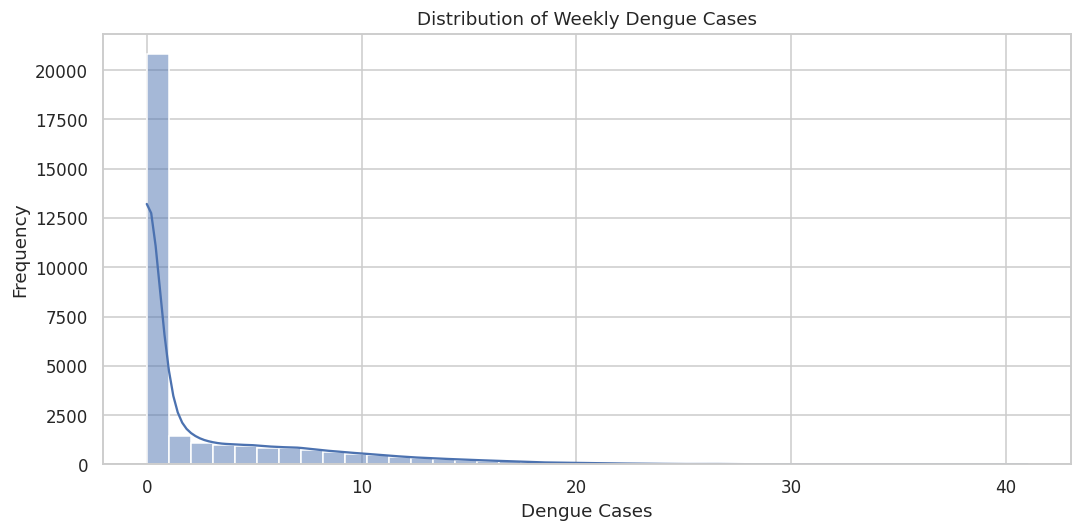

In [64]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="dengue_cases",
    bins=40,
    kde=True
)

plt.title("Distribution of Weekly Dengue Cases")
plt.xlabel("Dengue Cases")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

## CELL : 16 --> Zero vs Non-Zero Dengue Cases

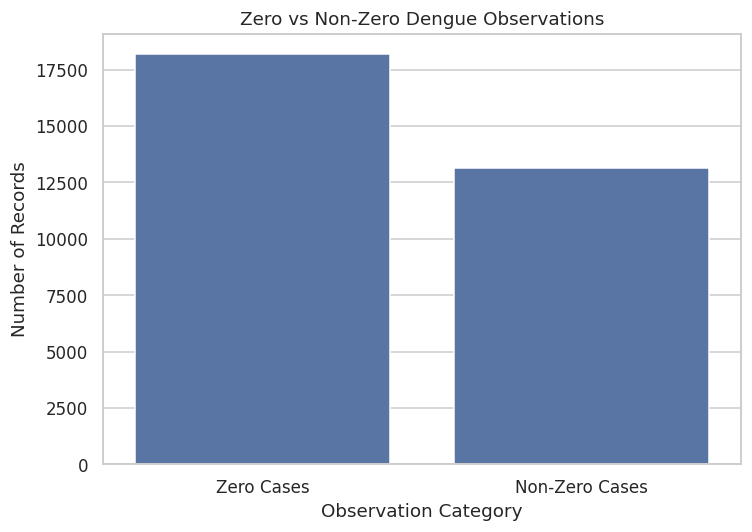

,Category,Count
0,Zero Cases,18176
1,Non-Zero Cases,13144


In [65]:
case_distribution = pd.DataFrame({
    "Category": ["Zero Cases", "Non-Zero Cases"],
    "Count": [
        (df["dengue_cases"] == 0).sum(),
        (df["dengue_cases"] > 0).sum()
    ]
})

plt.figure(figsize=(7, 5))

sns.barplot(
    data=case_distribution,
    x="Category",
    y="Count"
)

plt.title("Zero vs Non-Zero Dengue Observations")
plt.xlabel("Observation Category")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

display(case_distribution)

## CELL : 17 --> Overall Weekly Dengue Trend

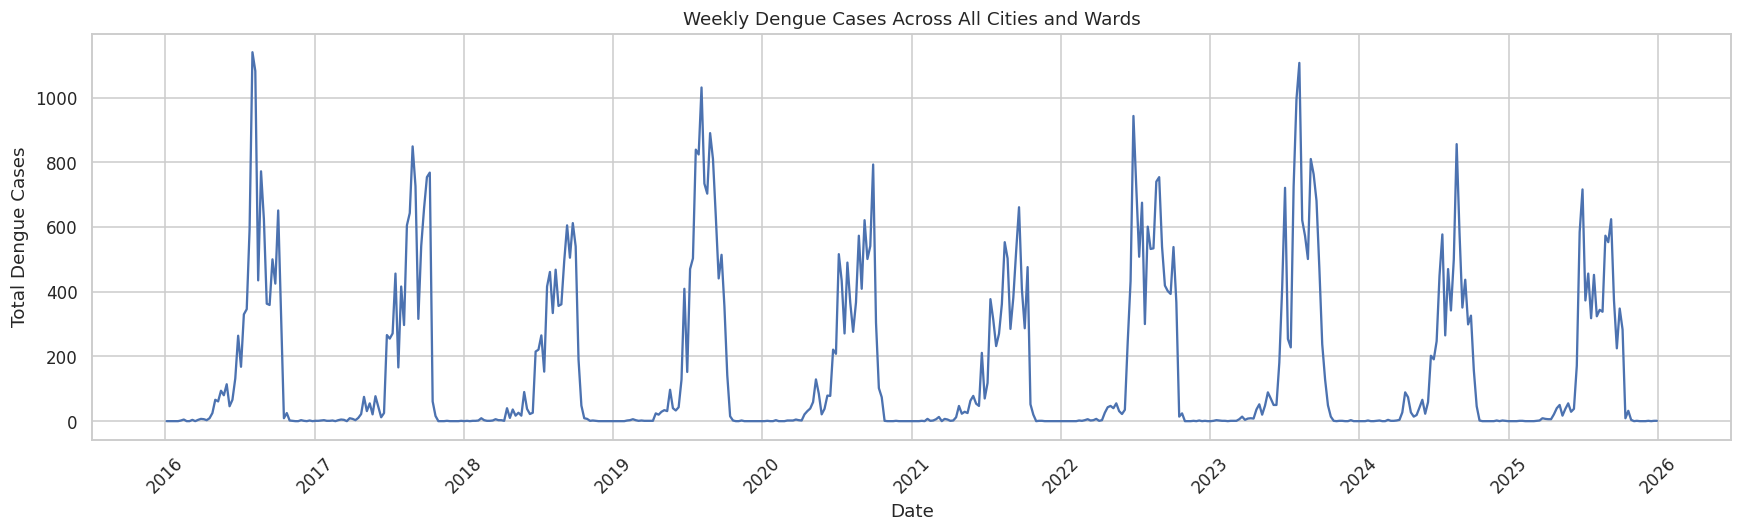

In [66]:
weekly_cases = (
    df.groupby("date")["dengue_cases"]
      .sum()
      .reset_index()
)

plt.figure(figsize=(16, 5))

sns.lineplot(
    data=weekly_cases,
    x="date",
    y="dengue_cases"
)

plt.title("Weekly Dengue Cases Across All Cities and Wards")
plt.xlabel("Date")
plt.ylabel("Total Dengue Cases")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## CELL : 18 --> Yearly Dengue Cases

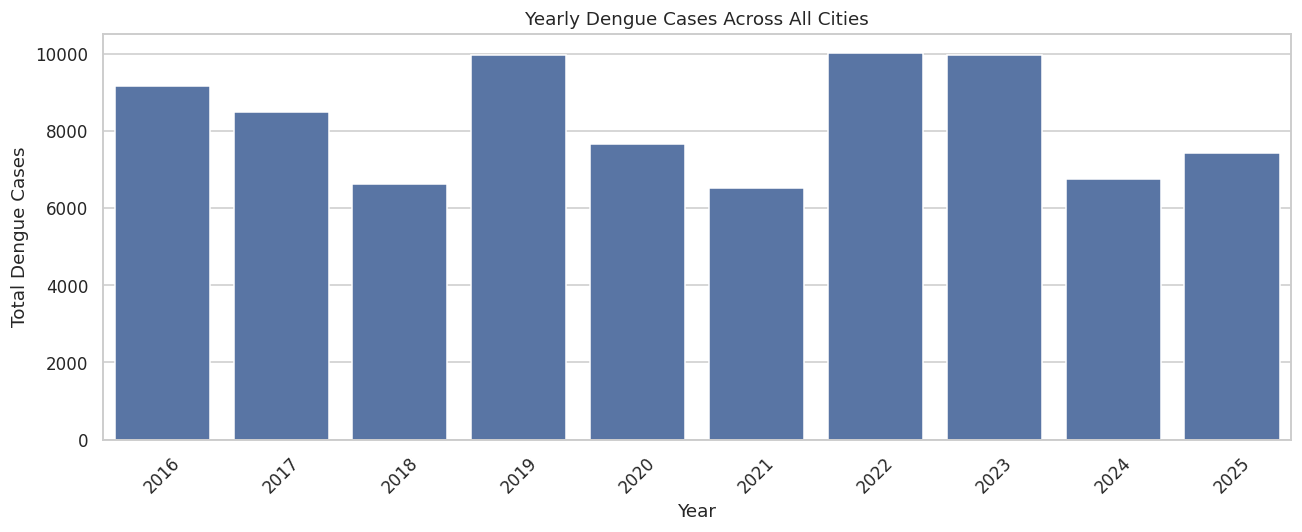

,year,dengue_cases
0,2016,9151
1,2017,8481
2,2018,6621
3,2019,9967
4,2020,7669
5,2021,6530
6,2022,10013
7,2023,9955
8,2024,6760
9,2025,7425


In [67]:
df["year"] = df["date"].dt.year

yearly_cases = (
    df.groupby("year")["dengue_cases"]
      .sum()
      .reset_index()
)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=yearly_cases,
    x="year",
    y="dengue_cases"
)

plt.title("Yearly Dengue Cases Across All Cities")
plt.xlabel("Year")
plt.ylabel("Total Dengue Cases")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(yearly_cases)

## CELL : 19 --> Monthly Dengue Cases

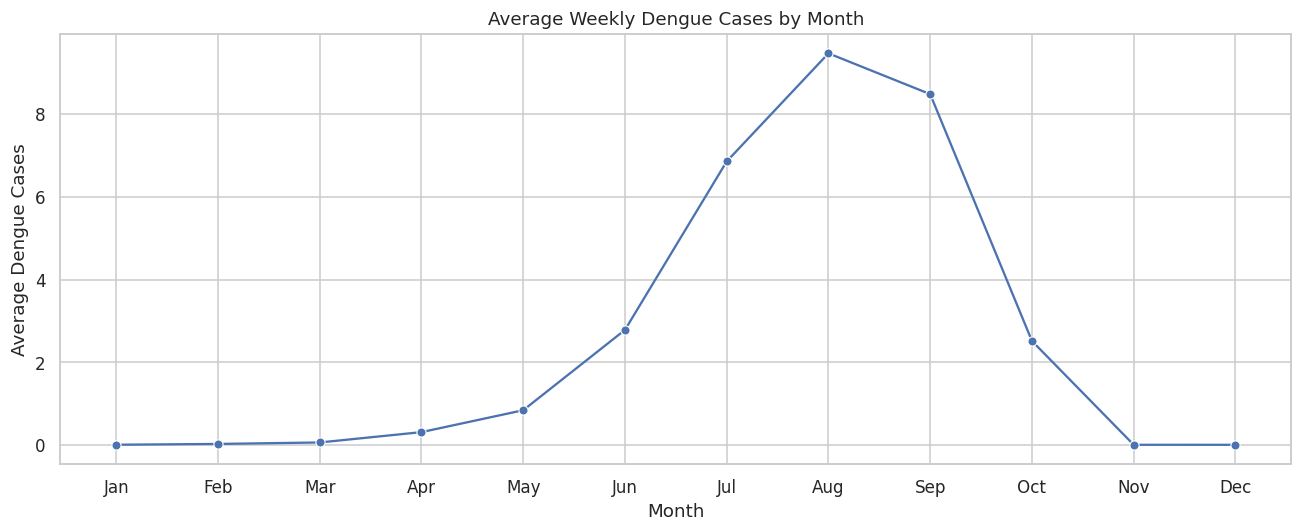

,month,dengue_cases
0,1,0.008519
1,2,0.027642
2,3,0.063178
3,4,0.313178
4,5,0.842222
5,6,2.783333
6,7,6.855926
7,8,9.468561
8,9,8.482171
9,10,2.516296


In [68]:
df["month"] = df["date"].dt.month

monthly_cases = (
    df.groupby("month")["dengue_cases"]
      .mean()
      .reset_index()
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_cases,
    x="month",
    y="dengue_cases",
    marker="o"
)

plt.title("Average Weekly Dengue Cases by Month")
plt.xlabel("Month")
plt.ylabel("Average Dengue Cases")

plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.tight_layout()
plt.show()

display(monthly_cases)

## CELL : 20 --> Year-Month Dengue Heatmap

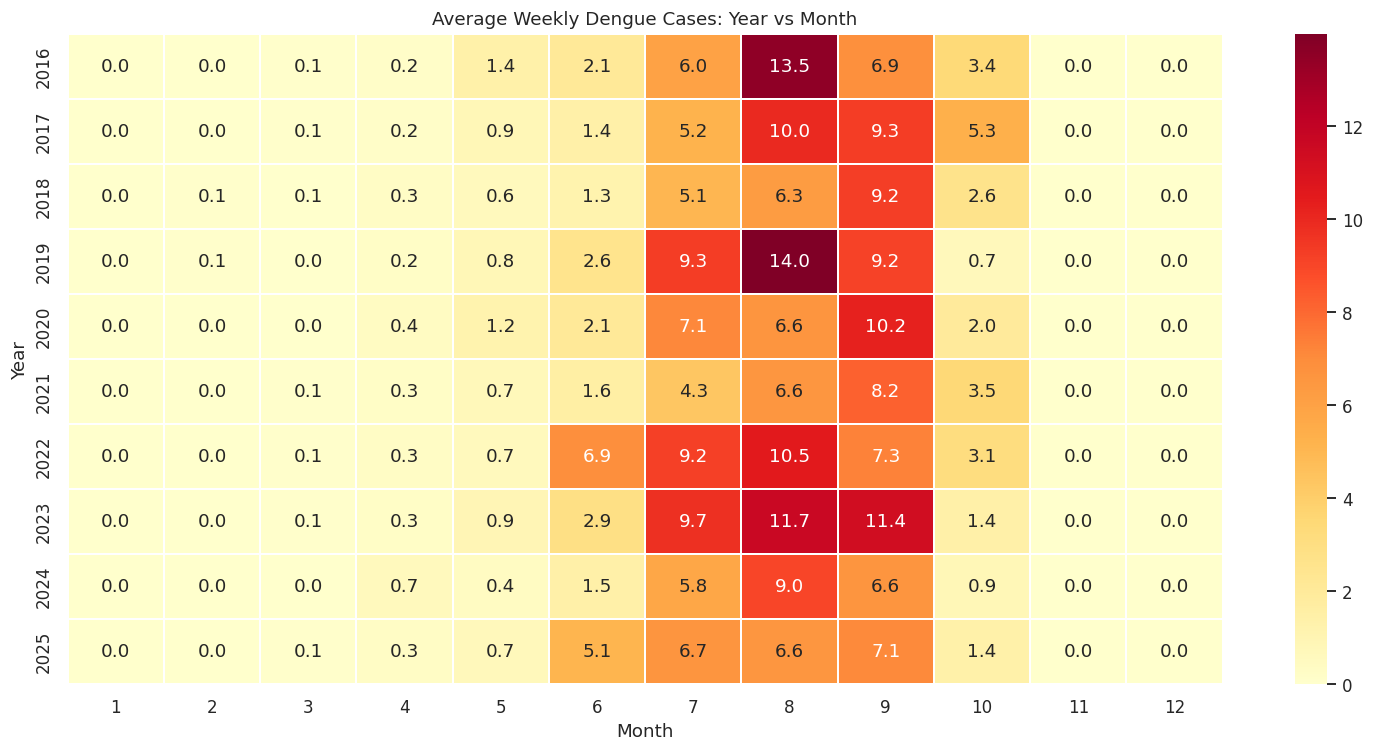

In [69]:
year_month_cases = (
    df.pivot_table(
        index="year",
        columns="month",
        values="dengue_cases",
        aggfunc="mean"
    )
)

plt.figure(figsize=(14, 7))

sns.heatmap(
    year_month_cases,
    cmap="YlOrRd",
    annot=True,
    fmt=".1f",
    linewidths=0.3
)

plt.title("Average Weekly Dengue Cases: Year vs Month")
plt.xlabel("Month")
plt.ylabel("Year")

plt.tight_layout()
plt.show()

## CELL : 21 --> Total Dengue Cases by City

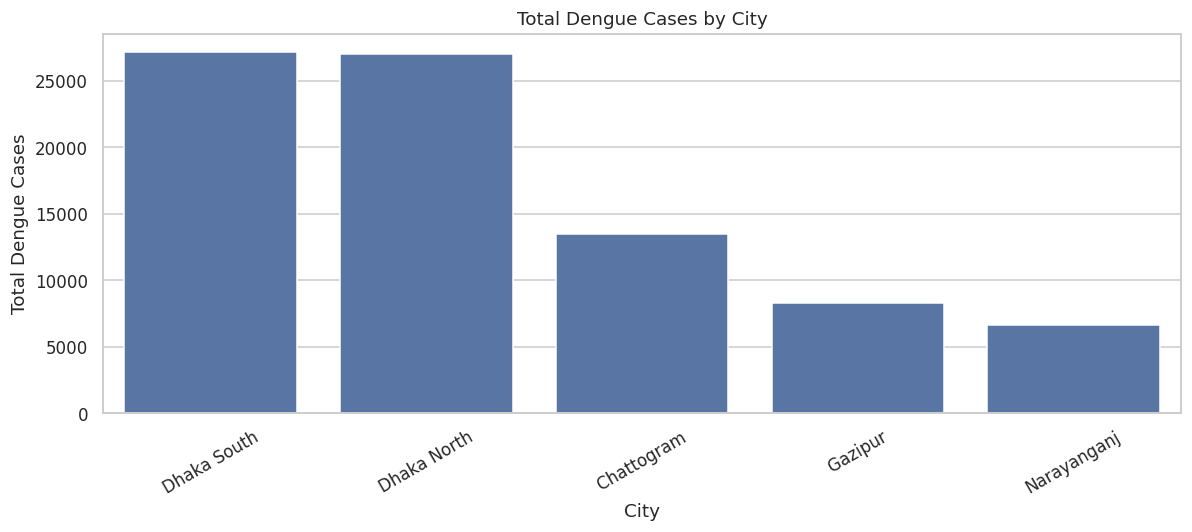

,city,dengue_cases
0,Dhaka South,27193
1,Dhaka North,27001
2,Chattogram,13470
3,Gazipur,8295
4,Narayanganj,6613


In [70]:
city_cases = (
    df.groupby("city")["dengue_cases"]
      .sum()
      .sort_values(ascending=False)
      .reset_index()
)

plt.figure(figsize=(11, 5))

sns.barplot(
    data=city_cases,
    x="city",
    y="dengue_cases"
)

plt.title("Total Dengue Cases by City")
plt.xlabel("City")
plt.ylabel("Total Dengue Cases")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

display(city_cases)

## CELL : 22 --> Weekly Dengue Trends by City

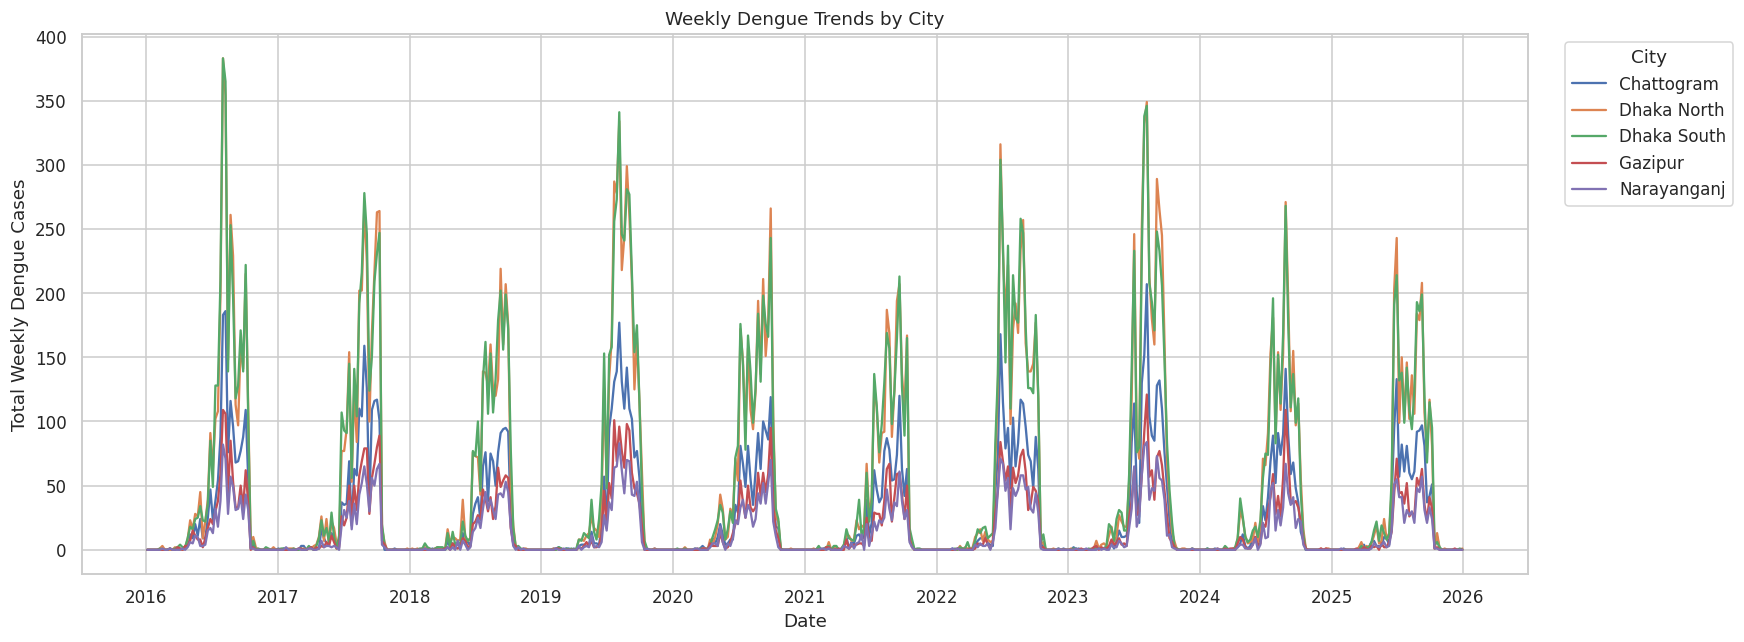

In [71]:
city_weekly = (
    df.groupby(["date", "city"])["dengue_cases"]
      .sum()
      .reset_index()
)

plt.figure(figsize=(16, 6))

sns.lineplot(
    data=city_weekly,
    x="date",
    y="dengue_cases",
    hue="city"
)

plt.title("Weekly Dengue Trends by City")
plt.xlabel("Date")
plt.ylabel("Total Weekly Dengue Cases")

plt.legend(title="City", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## CELL : 23 --> Top 15 Wards by Total Dengue Cases

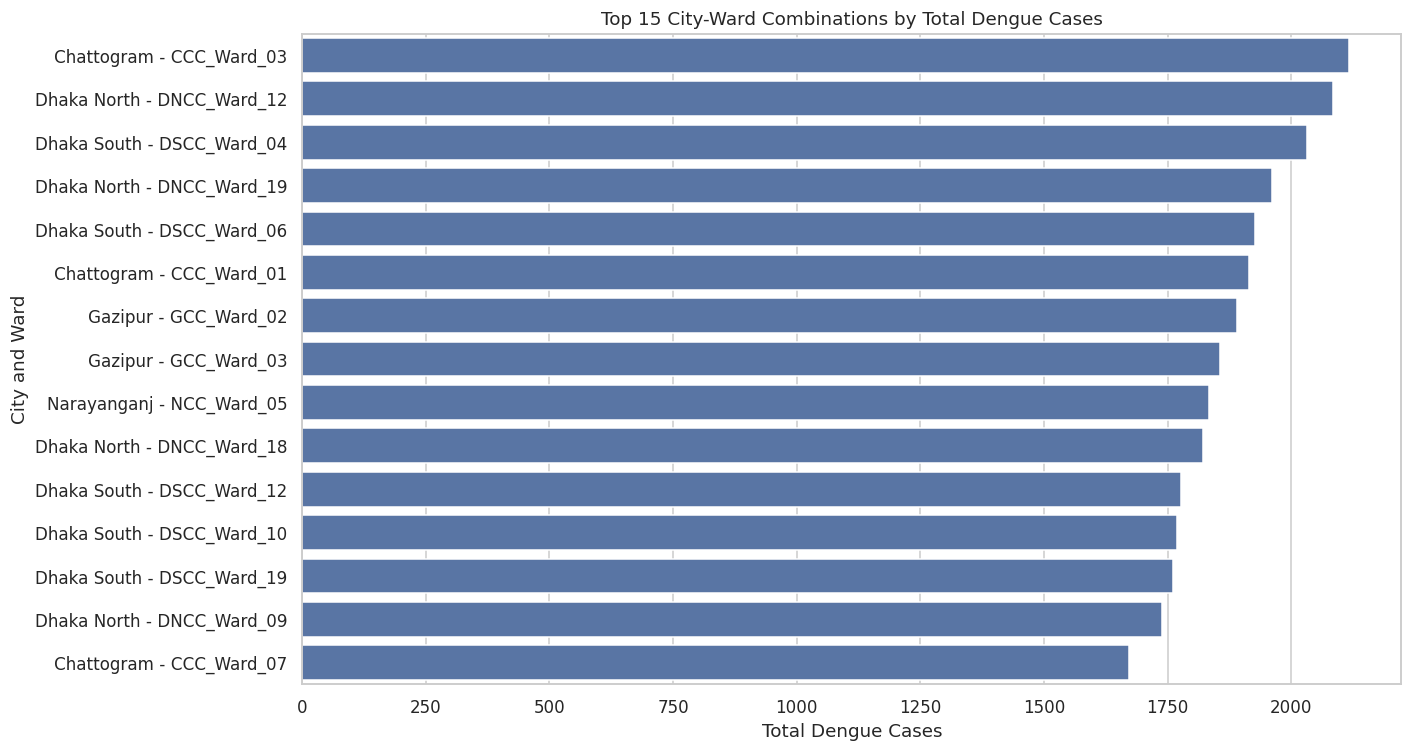

,city,ward_id,dengue_cases,city_ward
2,Chattogram,CCC_Ward_03,2117,Chattogram - CCC_Ward_03
21,Dhaka North,DNCC_Ward_12,2085,Dhaka North - DNCC_Ward_12
33,Dhaka South,DSCC_Ward_04,2032,Dhaka South - DSCC_Ward_04
28,Dhaka North,DNCC_Ward_19,1961,Dhaka North - DNCC_Ward_19
35,Dhaka South,DSCC_Ward_06,1926,Dhaka South - DSCC_Ward_06
0,Chattogram,CCC_Ward_01,1915,Chattogram - CCC_Ward_01
51,Gazipur,GCC_Ward_02,1891,Gazipur - GCC_Ward_02
52,Gazipur,GCC_Ward_03,1857,Gazipur - GCC_Ward_03
59,Narayanganj,NCC_Ward_05,1833,Narayanganj - NCC_Ward_05
27,Dhaka North,DNCC_Ward_18,1822,Dhaka North - DNCC_Ward_18


In [72]:
ward_cases = (
    df.groupby(["city", "ward_id"])["dengue_cases"]
      .sum()
      .reset_index()
      .sort_values("dengue_cases", ascending=False)
)

ward_cases["city_ward"] = (
    ward_cases["city"] + " - " + ward_cases["ward_id"].astype(str)
)

top_wards = ward_cases.head(15)

plt.figure(figsize=(13, 7))

sns.barplot(
    data=top_wards,
    x="dengue_cases",
    y="city_ward"
)

plt.title("Top 15 City-Ward Combinations by Total Dengue Cases")
plt.xlabel("Total Dengue Cases")
plt.ylabel("City and Ward")

plt.tight_layout()
plt.show()

display(top_wards)

## CELL : 24 --> Average Dengue Cases by City

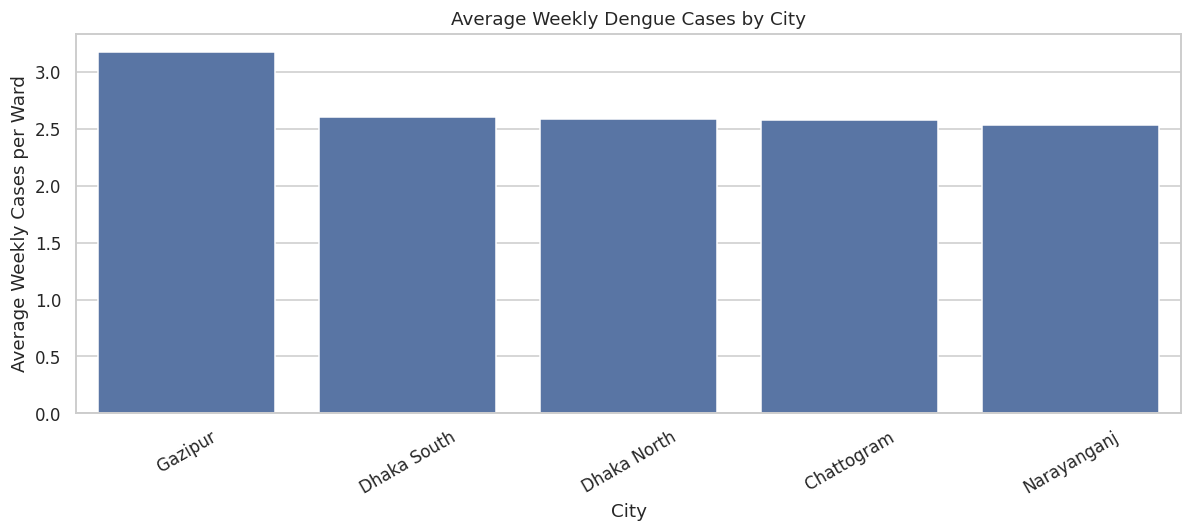

,city,average_weekly_cases
3,Gazipur,3.178161
2,Dhaka South,2.604693
1,Dhaka North,2.586303
0,Chattogram,2.580460
4,Narayanganj,2.533716


In [73]:
city_average = (
    df.groupby("city")["dengue_cases"]
      .mean()
      .reset_index(name="average_weekly_cases")
      .sort_values("average_weekly_cases", ascending=False)
)

plt.figure(figsize=(11, 5))

sns.barplot(
    data=city_average,
    x="city",
    y="average_weekly_cases"
)

plt.title("Average Weekly Dengue Cases by City")
plt.xlabel("City")
plt.ylabel("Average Weekly Cases per Ward")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

display(city_average)

## CELL : 25 --> Weather Variables vs Dengue Cases

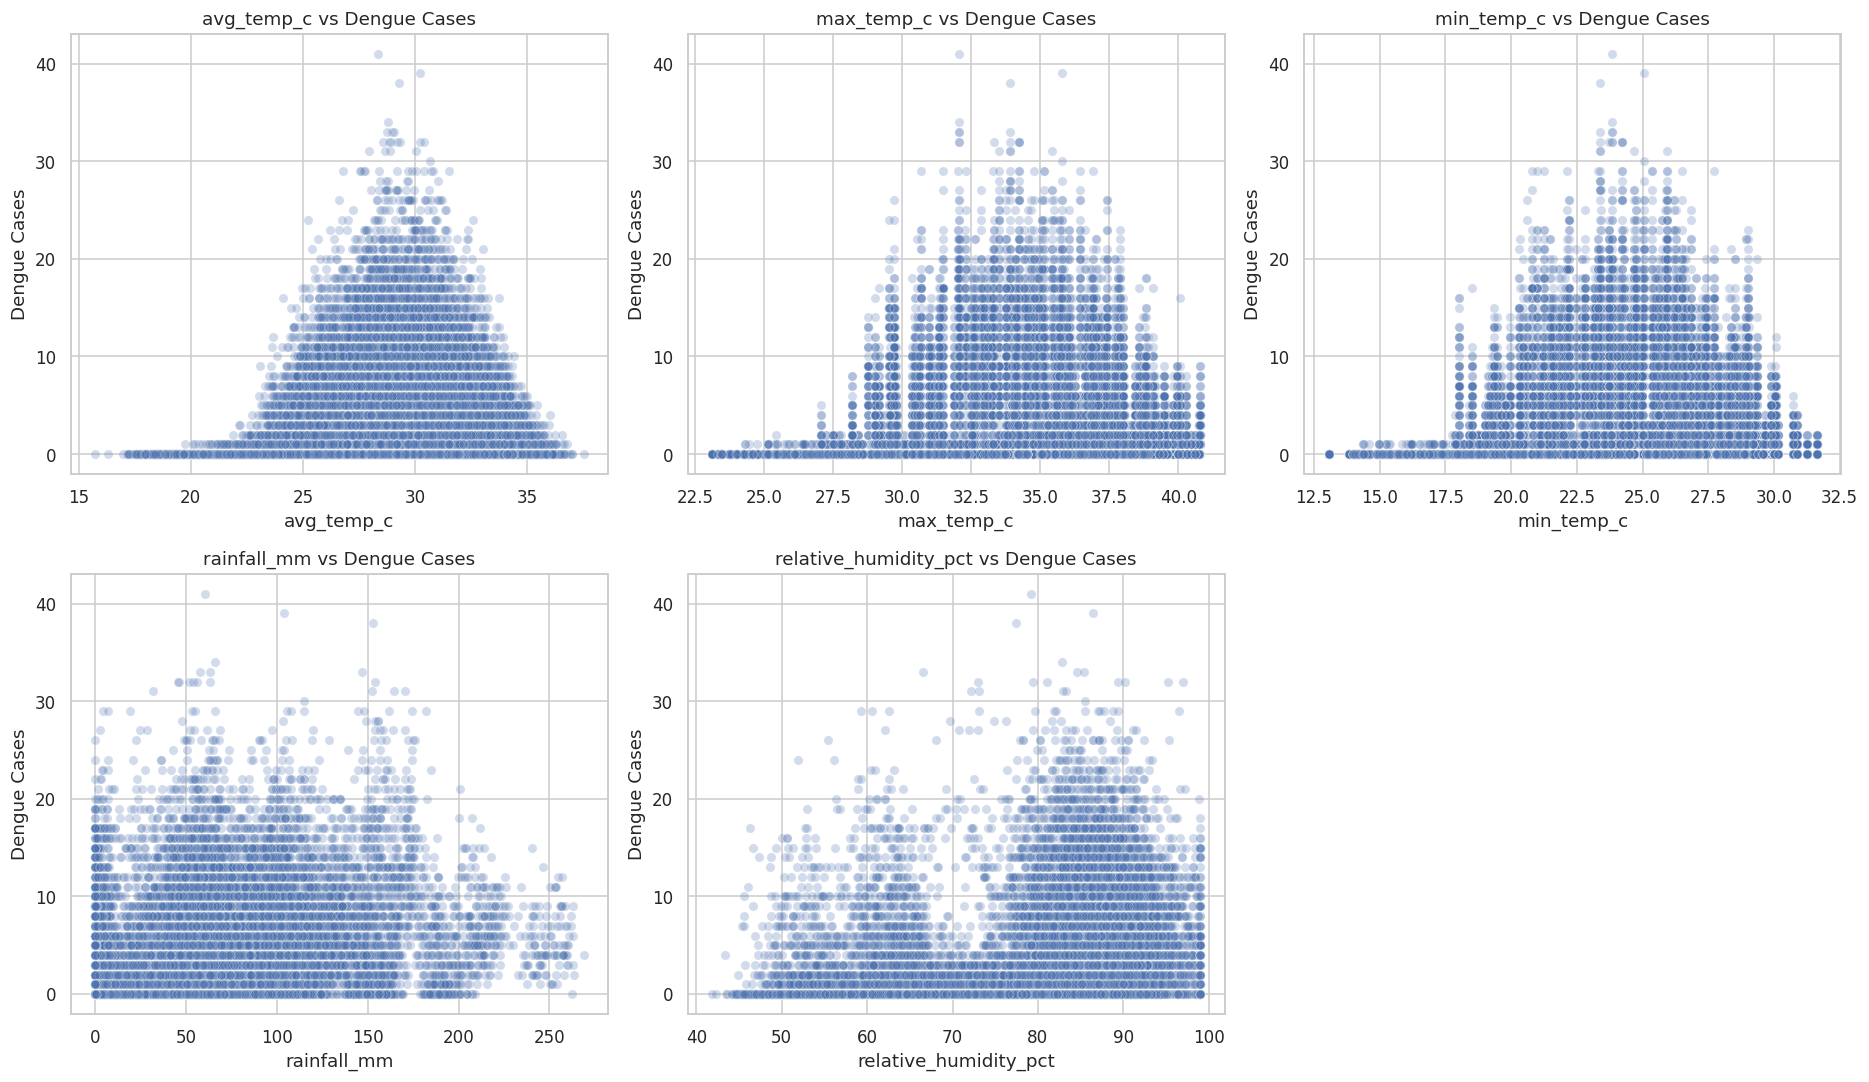

In [74]:
weather_columns = [
    "avg_temp_c",
    "max_temp_c",
    "min_temp_c",
    "rainfall_mm",
    "relative_humidity_pct"
]

fig, axes = plt.subplots(2, 3, figsize=(17, 10))

axes = axes.flatten()

for index, column in enumerate(weather_columns):

    sns.scatterplot(
        data=df,
        x=column,
        y="dengue_cases",
        alpha=0.25,
        ax=axes[index]
    )

    axes[index].set_title(f"{column} vs Dengue Cases")
    axes[index].set_xlabel(column)
    axes[index].set_ylabel("Dengue Cases")

axes[-1].axis("off")

plt.tight_layout()
plt.show()

## CELL : 26 --> Weather Correlation with Dengue Cases

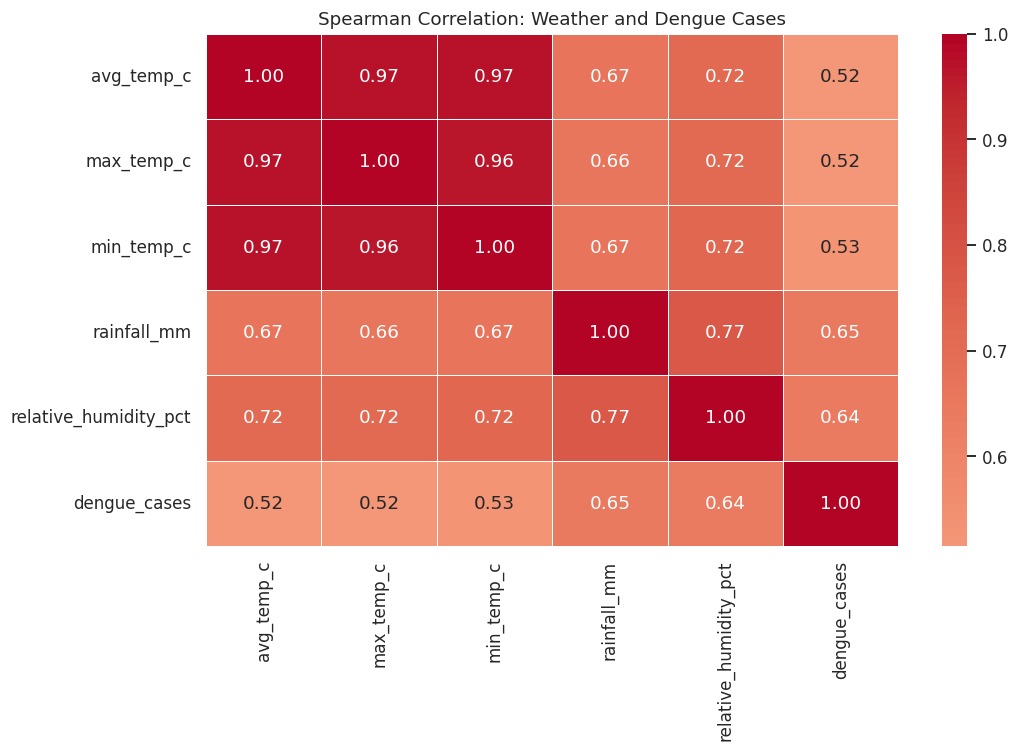

,dengue_cases
dengue_cases,1.000000
rainfall_mm,0.649402
relative_humidity_pct,0.638804
min_temp_c,0.527153
max_temp_c,0.515374
avg_temp_c,0.515240


In [75]:
weather_correlation = (
    df[weather_columns + ["dengue_cases"]]
      .corr(method="spearman")
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    weather_correlation,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Spearman Correlation: Weather and Dengue Cases")

plt.tight_layout()
plt.show()

display(weather_correlation["dengue_cases"].sort_values(ascending=False))

## CELL : 27 --> Vulnerability Features vs Dengue Cases

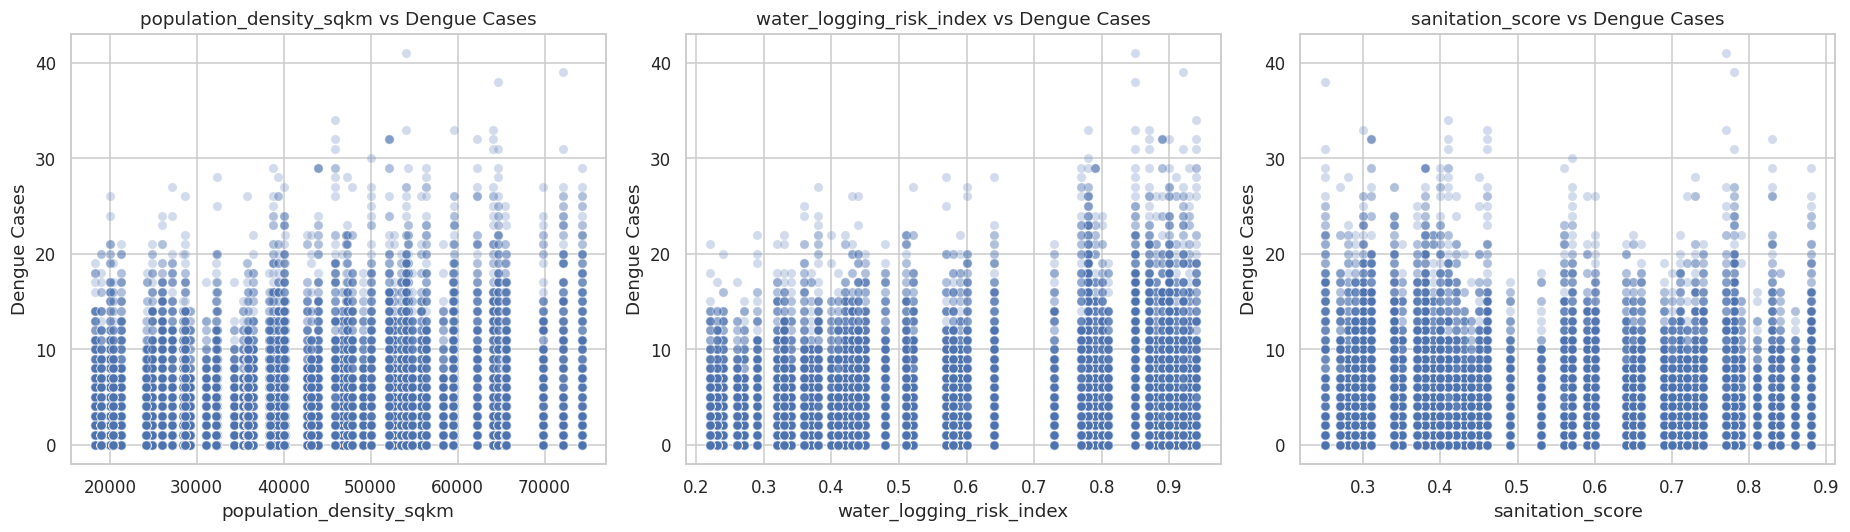

In [76]:
vulnerability_columns = [
    "population_density_sqkm",
    "water_logging_risk_index",
    "sanitation_score"
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for index, column in enumerate(vulnerability_columns):

    sns.scatterplot(
        data=df,
        x=column,
        y="dengue_cases",
        alpha=0.25,
        ax=axes[index]
    )

    axes[index].set_title(f"{column} vs Dengue Cases")
    axes[index].set_xlabel(column)
    axes[index].set_ylabel("Dengue Cases")

plt.tight_layout()
plt.show()

## CELL : 28 --> Ward Vulnerability Summary

In [77]:
ward_vulnerability = (
    df.groupby(["city", "ward_id"])
      .agg(
          population_density=("population_density_sqkm", "first"),
          waterlogging_risk=("water_logging_risk_index", "first"),
          sanitation_score=("sanitation_score", "first"),
          average_dengue_cases=("dengue_cases", "mean"),
          total_dengue_cases=("dengue_cases", "sum")
      )
      .reset_index()
)

display(
    ward_vulnerability.sort_values(
        "average_dengue_cases",
        ascending=False
    ).head(15)
)

,city,ward_id,population_density,waterlogging_risk,sanitation_score,average_dengue_cases,total_dengue_cases
2,Chattogram,CCC_Ward_03,64626,0.85,0.25,4.055556,2117
21,Dhaka North,DNCC_Ward_12,72086,0.92,0.78,3.994253,2085
33,Dhaka South,DSCC_Ward_04,74252,0.78,0.38,3.892720,2032
28,Dhaka North,DNCC_Ward_19,52080,0.89,0.31,3.756705,1961
35,Dhaka South,DSCC_Ward_06,59553,0.78,0.30,3.689655,1926
0,Chattogram,CCC_Ward_01,64024,0.87,0.46,3.668582,1915
51,Gazipur,GCC_Ward_02,45898,0.94,0.41,3.622605,1891
52,Gazipur,GCC_Ward_03,56311,0.77,0.40,3.557471,1857
59,Narayanganj,NCC_Ward_05,40043,0.90,0.34,3.511494,1833
27,Dhaka North,DNCC_Ward_18,62182,0.90,0.83,3.490421,1822


## CELL : 29 --> Numerical Feature Correlation Heatmap

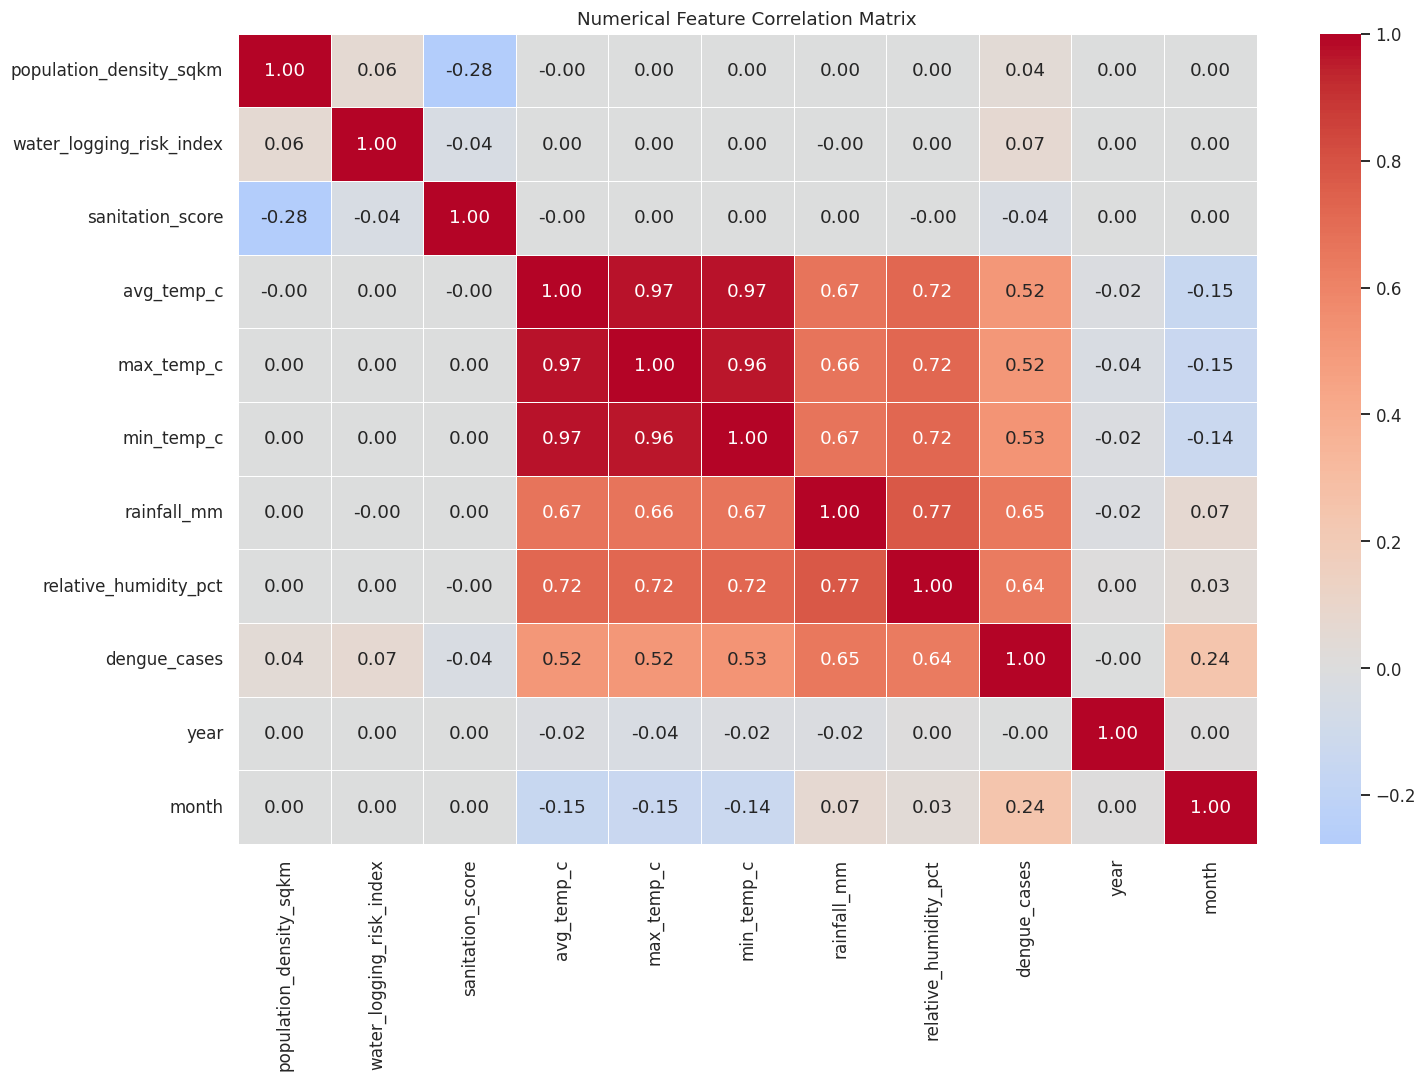

In [78]:
numerical_columns = df.select_dtypes(include=np.number).columns

correlation_matrix = df[numerical_columns].corr(method="spearman")

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.4
)

plt.title("Numerical Feature Correlation Matrix")

plt.tight_layout()
plt.show()

## CELL : 30 --> EDA Summary Report

In [79]:
# ============================================================
# CELL : 30 --> EDA Summary Report
# ============================================================

print("=" * 65)
print("SECTION 03: EXPLORATORY DATA ANALYSIS SUMMARY")
print("=" * 65)

print("\nDATASET")
print("-" * 40)
print("Total Records:", len(df))
print("Cities:", df["city"].nunique())
print("City-Ward Groups:", df.groupby(["city", "ward_id"]).ngroups)

print("\nDENGUE CASES")
print("-" * 40)
print("Total Cases:", df["dengue_cases"].sum())
print("Average Cases:", round(df["dengue_cases"].mean(), 2))
print("Maximum Cases:", df["dengue_cases"].max())
print("Zero-Case Percentage:",
      round((df["dengue_cases"] == 0).mean() * 100, 2), "%")

print("\nYEARLY CASE TOTALS")
print("-" * 40)
display(yearly_cases)

print("\nCITY-WISE CASE TOTALS")
print("-" * 40)
display(city_cases)

print("\nTOP 10 CITY-WARD COMBINATIONS")
print("-" * 40)
display(ward_cases.head(10))

print("\nWEATHER CORRELATION WITH DENGUE")
print("-" * 40)
display(weather_correlation["dengue_cases"].sort_values(ascending=False))

print("\nSECTION 03 EDA COMPLETED")

SECTION 03: EXPLORATORY DATA ANALYSIS SUMMARY

DATASET
----------------------------------------
Total Records: 31320
Cities: 5
City-Ward Groups: 60

DENGUE CASES
----------------------------------------
Total Cases: 82572
Average Cases: 2.64
Maximum Cases: 41
Zero-Case Percentage: 58.03 %

YEARLY CASE TOTALS
----------------------------------------


,year,dengue_cases
0,2016,9151
1,2017,8481
2,2018,6621
3,2019,9967
4,2020,7669
5,2021,6530
6,2022,10013
7,2023,9955
8,2024,6760
9,2025,7425



CITY-WISE CASE TOTALS
----------------------------------------


,city,dengue_cases
0,Dhaka South,27193
1,Dhaka North,27001
2,Chattogram,13470
3,Gazipur,8295
4,Narayanganj,6613



TOP 10 CITY-WARD COMBINATIONS
----------------------------------------


,city,ward_id,dengue_cases,city_ward
2,Chattogram,CCC_Ward_03,2117,Chattogram - CCC_Ward_03
21,Dhaka North,DNCC_Ward_12,2085,Dhaka North - DNCC_Ward_12
33,Dhaka South,DSCC_Ward_04,2032,Dhaka South - DSCC_Ward_04
28,Dhaka North,DNCC_Ward_19,1961,Dhaka North - DNCC_Ward_19
35,Dhaka South,DSCC_Ward_06,1926,Dhaka South - DSCC_Ward_06
0,Chattogram,CCC_Ward_01,1915,Chattogram - CCC_Ward_01
51,Gazipur,GCC_Ward_02,1891,Gazipur - GCC_Ward_02
52,Gazipur,GCC_Ward_03,1857,Gazipur - GCC_Ward_03
59,Narayanganj,NCC_Ward_05,1833,Narayanganj - NCC_Ward_05
27,Dhaka North,DNCC_Ward_18,1822,Dhaka North - DNCC_Ward_18



WEATHER CORRELATION WITH DENGUE
----------------------------------------


,dengue_cases
dengue_cases,1.000000
rainfall_mm,0.649402
relative_humidity_pct,0.638804
min_temp_c,0.527153
max_temp_c,0.515374
avg_temp_c,0.515240



SECTION 03 EDA COMPLETED


## CELL : 31 --> Export EDA Results into One Excel Report

In [80]:
from google.colab import files

# Prepare summary tables
overview = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Total Columns",
        "Total Cities",
        "City-Ward Combinations",
        "Date Range Start",
        "Date Range End",
        "Total Dengue Cases",
        "Average Dengue Cases",
        "Median Dengue Cases",
        "Maximum Dengue Cases",
        "Zero-Case Percentage",
        "Missing Values"
    ],
    "Value": [
        len(df),
        df.shape[1],
        df["city"].nunique(),
        df.groupby(["city", "ward_id"]).ngroups,
        str(df["date"].min().date()),
        str(df["date"].max().date()),
        df["dengue_cases"].sum(),
        round(df["dengue_cases"].mean(), 2),
        df["dengue_cases"].median(),
        df["dengue_cases"].max(),
        round((df["dengue_cases"] == 0).mean() * 100, 2),
        df.isnull().sum().sum()
    ]
})

yearly_summary = (
    df.groupby(df["date"].dt.year)["dengue_cases"]
      .sum()
      .reset_index()
)
yearly_summary.columns = ["Year", "Total Dengue Cases"]

monthly_summary = (
    df.groupby(df["date"].dt.month)["dengue_cases"]
      .mean()
      .reset_index()
)
monthly_summary.columns = ["Month", "Average Weekly Cases"]

city_summary = (
    df.groupby("city")
      .agg(
          Records=("dengue_cases", "size"),
          Wards=("ward_id", "nunique"),
          Total_Cases=("dengue_cases", "sum"),
          Average_Cases=("dengue_cases", "mean")
      )
      .reset_index()
)

ward_summary = (
    df.groupby(["city", "ward_id"])
      .agg(
          Total_Cases=("dengue_cases", "sum"),
          Average_Cases=("dengue_cases", "mean"),
          Population_Density=("population_density_sqkm", "first"),
          Waterlogging_Risk=("water_logging_risk_index", "first"),
          Sanitation_Score=("sanitation_score", "first")
      )
      .reset_index()
      .sort_values("Total_Cases", ascending=False)
)

weather_columns = [
    "avg_temp_c",
    "max_temp_c",
    "min_temp_c",
    "rainfall_mm",
    "relative_humidity_pct"
]

weather_correlation = (
    df[weather_columns + ["dengue_cases"]]
      .corr(method="spearman")["dengue_cases"]
      .reset_index()
)

weather_correlation.columns = [
    "Variable",
    "Spearman Correlation with Dengue"
]

column_summary = pd.DataFrame({
    "Column": df.columns,
    "Data Type": [str(df[c].dtype) for c in df.columns],
    "Unique Values": [df[c].nunique() for c in df.columns],
    "Missing Values": [df[c].isnull().sum() for c in df.columns]
})

# Export all results into one Excel workbook
report_path = "/content/EDA_Results_Summary.xlsx"

with pd.ExcelWriter(report_path, engine="openpyxl") as writer:

    overview.to_excel(writer, sheet_name="Overview", index=False)
    column_summary.to_excel(writer, sheet_name="Column Summary", index=False)
    yearly_summary.to_excel(writer, sheet_name="Yearly Cases", index=False)
    monthly_summary.to_excel(writer, sheet_name="Monthly Cases", index=False)
    city_summary.to_excel(writer, sheet_name="City Summary", index=False)
    ward_summary.to_excel(writer, sheet_name="Ward Summary", index=False)
    weather_correlation.to_excel(writer, sheet_name="Weather Correlation", index=False)

print("EDA report generated successfully!")

files.download(report_path)

EDA report generated successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Section 04 — Data Quality & Validation

## CELL : 32 --> Missing Value Validation

In [81]:
print("MISSING VALUE VALIDATION")
print("=" * 60)

missing_summary = pd.DataFrame({
    "Column": df.columns,
    "Missing_Count": df.isnull().sum().values,
    "Missing_Percentage": (
        df.isnull().mean().values * 100
    ).round(2)
})

display(missing_summary)

total_missing = df.isnull().sum().sum()

print("\nTotal Missing Values:", total_missing)

if total_missing == 0:
    print("RESULT: No missing values detected.")
else:
    print("RESULT: Missing values require investigation.")

MISSING VALUE VALIDATION


,Column,Missing_Count,Missing_Percentage
0,date,0,0.0
1,city,0,0.0
2,ward_id,0,0.0
3,population_density_sqkm,0,0.0
4,water_logging_risk_index,0,0.0
5,sanitation_score,0,0.0
6,avg_temp_c,0,0.0
7,max_temp_c,0,0.0
8,min_temp_c,0,0.0
9,rainfall_mm,0,0.0



Total Missing Values: 0
RESULT: No missing values detected.


## CELL : 33 --> Duplicate Record Validation

In [82]:
print("DUPLICATE RECORD VALIDATION")
print("=" * 60)

duplicate_rows = df.duplicated()

duplicate_keys = df.duplicated(
    subset=["city", "ward_id", "date"],
    keep=False
)

print("Complete Duplicate Rows:", duplicate_rows.sum())

print("Duplicate City-Ward-Date Records:",
      duplicate_keys.sum())

if duplicate_keys.sum() > 0:
    print("\nDuplicate Record Examples:")

    display(
        df.loc[
            duplicate_keys,
            ["city", "ward_id", "date", "dengue_cases"]
        ].sort_values(["city", "ward_id", "date"]).head(20)
    )
else:
    print("\nRESULT: No duplicate city-ward-date combinations.")

DUPLICATE RECORD VALIDATION
Complete Duplicate Rows: 0
Duplicate City-Ward-Date Records: 0

RESULT: No duplicate city-ward-date combinations.


## CELL : 34 --> Invalid and Negative Value Detection

In [83]:
print("INVALID VALUE DETECTION")
print("=" * 60)

numeric_columns = df.select_dtypes(include=np.number).columns

negative_summary = pd.DataFrame({
    "Column": numeric_columns,
    "Negative_Count": [
        (df[column] < 0).sum()
        for column in numeric_columns
    ]
})

display(negative_summary)

print("\nDengue Case Validation:")

print("Negative Dengue Cases:",
      (df["dengue_cases"] < 0).sum())

print("Non-Integer Dengue Values:",
      (~np.isclose(
          df["dengue_cases"].dropna() % 1,
          0
      )).sum())

print("\nRESULT: Review any negative or non-integer values.")

INVALID VALUE DETECTION


,Column,Negative_Count
0,population_density_sqkm,0
1,water_logging_risk_index,0
2,sanitation_score,0
3,avg_temp_c,0
4,max_temp_c,0
5,min_temp_c,0
6,rainfall_mm,0
7,relative_humidity_pct,0
8,dengue_cases,0
9,year,0



Dengue Case Validation:
Negative Dengue Cases: 0
Non-Integer Dengue Values: 0

RESULT: Review any negative or non-integer values.


## CELL : 35 --> Numerical Range Validation

In [84]:
print("NUMERICAL RANGE VALIDATION")
print("=" * 60)

range_summary = df.describe().T[
    ["min", "25%", "50%", "75%", "max"]
]

display(range_summary)

print("\nEnvironmental Feature Ranges:")
display(
    df[
        [
            "population_density_sqkm",
            "water_logging_risk_index",
            "sanitation_score",
            "avg_temp_c",
            "max_temp_c",
            "min_temp_c",
            "rainfall_mm",
            "relative_humidity_pct"
        ]
    ].agg(["min", "max", "mean"]).T
)

NUMERICAL RANGE VALIDATION


,min,25%,50%,75%,max
date,2016-01-04 00:00:00,2018-07-02 00:00:00,2020-12-31 12:00:00,2023-07-03 00:00:00,2025-12-29 00:00:00
population_density_sqkm,18314.0,30573.5,42854.0,54168.25,74252.0
water_logging_risk_index,0.22,0.3775,0.545,0.82,0.94
sanitation_score,0.25,0.38,0.57,0.7125,0.88
avg_temp_c,15.74,22.88,26.85,31.0225,37.51
max_temp_c,23.12,27.85,31.505,35.99,40.79
min_temp_c,13.06,18.0,21.67,25.97,31.64
rainfall_mm,0.0,0.92,8.37,59.42,268.83
relative_humidity_pct,41.84,60.4675,68.22,83.98,99.0
dengue_cases,0.0,0.0,0.0,4.0,41.0



Environmental Feature Ranges:


,min,max,mean
population_density_sqkm,18314.00,74252.00,43157.733333
water_logging_risk_index,0.22,0.94,0.579333
sanitation_score,0.25,0.88,0.554667
avg_temp_c,15.74,37.51,26.922804
max_temp_c,23.12,40.79,31.889061
min_temp_c,13.06,31.64,21.949425
rainfall_mm,0.00,268.83,35.630268
relative_humidity_pct,41.84,99.00,71.176132


## CELL : 36 --> Date Sequence Validation

In [85]:
print("DATE SEQUENCE VALIDATION")
print("=" * 60)

df["date"] = pd.to_datetime(df["date"])

date_gaps = (
    df.sort_values(["city", "ward_id", "date"])
      .groupby(["city", "ward_id"])["date"]
      .diff()
      .dt.days
      .dropna()
)

print("Minimum Date Interval:", date_gaps.min(), "days")
print("Maximum Date Interval:", date_gaps.max(), "days")

print("\nDate Interval Distribution:")
display(
    date_gaps.value_counts()
             .sort_index()
             .rename_axis("Interval_Days")
             .reset_index(name="Frequency")
)

non_weekly_intervals = date_gaps[date_gaps != 7]

print("\nNon-Weekly Intervals:", len(non_weekly_intervals))

DATE SEQUENCE VALIDATION
Minimum Date Interval: 7.0 days
Maximum Date Interval: 7.0 days

Date Interval Distribution:


,Interval_Days,Frequency
0,7.0,31260



Non-Weekly Intervals: 0


## CELL : 37 --> Missing Weekly Observation Detection

In [86]:
print("MISSING WEEKLY OBSERVATION DETECTION")
print("=" * 60)

missing_week_records = []

for (city, ward), group in df.groupby(["city", "ward_id"]):

    dates = (
        group["date"]
        .drop_duplicates()
        .sort_values()
    )

    expected_dates = pd.date_range(
        start=dates.min(),
        end=dates.max(),
        freq="7D"
    )

    missing_dates = expected_dates.difference(dates)

    for missing_date in missing_dates:
        missing_week_records.append({
            "city": city,
            "ward_id": ward,
            "missing_date": missing_date
        })

missing_weeks = pd.DataFrame(missing_week_records)

print("Missing Weekly Observations:", len(missing_weeks))

if len(missing_weeks) > 0:
    display(missing_weeks.head(20))
else:
    print("RESULT: No missing weekly dates detected.")

MISSING WEEKLY OBSERVATION DETECTION
Missing Weekly Observations: 0
RESULT: No missing weekly dates detected.


## CELL : 38 --> Static Ward Feature Validation

In [87]:
print("STATIC WARD FEATURE VALIDATION")
print("=" * 60)

static_features = [
    "population_density_sqkm",
    "water_logging_risk_index",
    "sanitation_score"
]

ward_consistency = (
    df.groupby(["city", "ward_id"])[static_features]
      .nunique()
      .reset_index()
)

inconsistent_wards = ward_consistency[
    (ward_consistency[static_features] > 1).any(axis=1)
]

print("Total City-Ward Groups:",
      len(ward_consistency))

print("Inconsistent City-Ward Groups:",
      len(inconsistent_wards))

if len(inconsistent_wards) > 0:
    display(inconsistent_wards)
else:
    print("RESULT: Static ward features are consistent.")

STATIC WARD FEATURE VALIDATION
Total City-Ward Groups: 60
Inconsistent City-Ward Groups: 0
RESULT: Static ward features are consistent.


## CELL : 39 --> Weather Granularity Validation

In [88]:
print("WEATHER GRANULARITY VALIDATION")
print("=" * 60)

weather_columns = [
    "avg_temp_c",
    "max_temp_c",
    "min_temp_c",
    "rainfall_mm",
    "relative_humidity_pct"
]

weather_unique = (
    df.groupby(["city", "date"])[weather_columns]
      .nunique()
      .reset_index()
)

weather_summary = pd.DataFrame({
    "Weather Variable": weather_columns,
    "City-Date Groups with Shared Values": [
        (weather_unique[column] == 1).sum()
        for column in weather_columns
    ],
    "City-Date Groups": len(weather_unique)
})

display(weather_summary)

print(
    "\nInterpretation: A value of 1 means that all ward records "
    "within that city-date group share the same weather value."
)

WEATHER GRANULARITY VALIDATION


,Weather Variable,City-Date Groups with Shared Values,City-Date Groups
0,avg_temp_c,0,2610
1,max_temp_c,2610,2610
2,min_temp_c,2610,2610
3,rainfall_mm,4,2610
4,relative_humidity_pct,0,2610



Interpretation: A value of 1 means that all ward records within that city-date group share the same weather value.


## CELL : 40 --> Dengue Case Outlier Detection

In [89]:
print("DENGUE CASE OUTLIER DETECTION")
print("=" * 60)

Q1 = df["dengue_cases"].quantile(0.25)
Q3 = df["dengue_cases"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["dengue_cases"] < lower_bound) |
    (df["dengue_cases"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

print("Potential Outliers:", len(outliers))

print("\nHighest Dengue Observations:")

display(
    df.nlargest(
        15,
        "dengue_cases"
    )[
        ["date", "city", "ward_id", "dengue_cases"]
    ]
)

DENGUE CASE OUTLIER DETECTION
Q1: 0.0
Q3: 4.0
IQR: 4.0
Lower Bound: -6.0
Upper Bound: 10.0
Potential Outliers: 2495

Highest Dengue Observations:


,date,city,ward_id,dengue_cases
25087,2016-08-08,Dhaka South,DSCC_Ward_19,41
11357,2023-07-31,Dhaka North,DNCC_Ward_12,39
1074,2016-08-01,Chattogram,CCC_Ward_03,38
26653,2016-08-08,Gazipur,GCC_Ward_02,34
31,2016-08-08,Chattogram,CCC_Ward_01,33
18301,2016-08-08,Dhaka South,DSCC_Ward_06,33
25086,2016-08-01,Dhaka South,DSCC_Ward_19,33
396,2023-08-07,Chattogram,CCC_Ward_01,32
14125,2016-08-08,Dhaka North,DNCC_Ward_18,32
14646,2016-08-01,Dhaka North,DNCC_Ward_19,32


## CELL : 41 --> Dataset Integrity Summary

In [90]:
print("=" * 65)
print("SECTION 04: DATA QUALITY AND VALIDATION REPORT")
print("=" * 65)

checks = {
    "Missing Values": df.isnull().sum().sum(),
    "Complete Duplicate Rows": df.duplicated().sum(),
    "Duplicate City-Ward-Date Keys": df.duplicated(
        subset=["city", "ward_id", "date"]
    ).sum(),
    "Negative Dengue Cases": (df["dengue_cases"] < 0).sum(),
    "Non-Integer Dengue Cases": (
        ~np.isclose(
            df["dengue_cases"].dropna() % 1,
            0
        )
    ).sum(),
    "Non-Weekly Intervals": (date_gaps != 7).sum(),
    "Missing Weekly Observations": len(missing_weeks),
    "Inconsistent Ward Groups": len(inconsistent_wards)
}

validation_report = pd.DataFrame(
    list(checks.items()),
    columns=["Validation Check", "Issue Count"]
)

display(validation_report)

print("\nDATASET DIMENSIONS:", df.shape)
print("DATE RANGE:", df["date"].min(), "to", df["date"].max())
print("CITIES:", df["city"].nunique())
print("CITY-WARD GROUPS:", df.groupby(["city", "ward_id"]).ngroups)

print("\nSECTION 04 VALIDATION CHECKS COMPLETED.")
print("Review flagged issues before proceeding to preprocessing.")

SECTION 04: DATA QUALITY AND VALIDATION REPORT


,Validation Check,Issue Count
0,Missing Values,0
1,Complete Duplicate Rows,0
2,Duplicate City-Ward-Date Keys,0
3,Negative Dengue Cases,0
4,Non-Integer Dengue Cases,0
5,Non-Weekly Intervals,0
6,Missing Weekly Observations,0
7,Inconsistent Ward Groups,0



DATASET DIMENSIONS: (31320, 14)
DATE RANGE: 2016-01-04 00:00:00 to 2025-12-29 00:00:00
CITIES: 5
CITY-WARD GROUPS: 60

SECTION 04 VALIDATION CHECKS COMPLETED.
Review flagged issues before proceeding to preprocessing.


# **5. Data Preprocessing**

## CELL : 42 --> Create a Clean Working Dataset

In [91]:
df_clean = df.copy()

# Remove EDA-only calendar columns.
# We will generate these again during feature engineering.
df_clean = df_clean.drop(
    columns=["year", "month"],
    errors="ignore"
)

print("Working dataset created successfully!")

print("Original Dataset Shape:", df.shape)
print("Working Dataset Shape:", df_clean.shape)

display(df_clean.head())

Working dataset created successfully!
Original Dataset Shape: (31320, 14)
Working Dataset Shape: (31320, 12)


,date,city,ward_id,population_density_sqkm,water_logging_risk_index,sanitation_score,avg_temp_c,max_temp_c,min_temp_c,rainfall_mm,relative_humidity_pct,dengue_cases
0,2016-01-04,Chattogram,CCC_Ward_01,64024,0.87,0.46,18.32,26.54,14.13,0.00,59.24,0
1,2016-01-11,Chattogram,CCC_Ward_01,64024,0.87,0.46,21.24,26.95,16.71,2.02,61.63,0
2,2016-01-18,Chattogram,CCC_Ward_01,64024,0.87,0.46,20.94,25.05,14.84,0.00,60.50,0
3,2016-01-25,Chattogram,CCC_Ward_01,64024,0.87,0.46,21.75,27.20,17.58,1.52,69.02,0
4,2016-02-01,Chattogram,CCC_Ward_01,64024,0.87,0.46,22.39,28.02,16.98,0.94,60.50,0


## CELL : 43 --> Standardize Data Types

In [92]:
# Convert date column
df_clean["date"] = pd.to_datetime(
    df_clean["date"],
    errors="coerce"
)

# Standardize categorical columns
df_clean["city"] = (
    df_clean["city"]
    .astype("string")
    .str.strip()
)

df_clean["ward_id"] = (
    df_clean["ward_id"]
    .astype("string")
    .str.strip()
)

# Numerical columns
numeric_columns = [
    "population_density_sqkm",
    "water_logging_risk_index",
    "sanitation_score",
    "avg_temp_c",
    "max_temp_c",
    "min_temp_c",
    "rainfall_mm",
    "relative_humidity_pct",
    "dengue_cases"
]

# Convert numerical columns
for column in numeric_columns:
    df_clean[column] = pd.to_numeric(
        df_clean[column],
        errors="coerce"
    )

print("DATA TYPE CONVERSION COMPLETED")
print("=" * 50)

display(
    pd.DataFrame({
        "Column": df_clean.columns,
        "Data Type": [
            str(df_clean[column].dtype)
            for column in df_clean.columns
        ],
        "Missing Values": [
            df_clean[column].isna().sum()
            for column in df_clean.columns
        ]
    })
)

DATA TYPE CONVERSION COMPLETED


,Column,Data Type,Missing Values
0,date,datetime64[ns],0
1,city,string,0
2,ward_id,string,0
3,population_density_sqkm,int64,0
4,water_logging_risk_index,float64,0
5,sanitation_score,float64,0
6,avg_temp_c,float64,0
7,max_temp_c,float64,0
8,min_temp_c,float64,0
9,rainfall_mm,float64,0


## CELL : 44 --> Validate Environmental Constraints

In [93]:
constraint_checks = {
    "Invalid Dates": df_clean["date"].isna().sum(),

    "Missing City": df_clean["city"].isna().sum(),

    "Missing Ward ID": df_clean["ward_id"].isna().sum(),

    "Negative Dengue Cases": (
        df_clean["dengue_cases"] < 0
    ).sum(),

    "Negative Rainfall": (
        df_clean["rainfall_mm"] < 0
    ).sum(),

    "Invalid Humidity": (
        (df_clean["relative_humidity_pct"] < 0) |
        (df_clean["relative_humidity_pct"] > 100)
    ).sum(),

    "Non-Positive Population Density": (
        df_clean["population_density_sqkm"] <= 0
    ).sum(),

    "Invalid Temperature Ordering": (
        (df_clean["min_temp_c"] > df_clean["avg_temp_c"]) |
        (df_clean["avg_temp_c"] > df_clean["max_temp_c"])
    ).sum()
}

constraint_report = pd.DataFrame(
    list(constraint_checks.items()),
    columns=["Constraint", "Issue Count"]
)

display(constraint_report)

print("\nNo records have been automatically deleted.")

,Constraint,Issue Count
0,Invalid Dates,0
1,Missing City,0
2,Missing Ward ID,0
3,Negative Dengue Cases,0
4,Negative Rainfall,0
5,Invalid Humidity,0
6,Non-Positive Population Density,0
7,Invalid Temperature Ordering,0



No records have been automatically deleted.


## CELL : 45 --> Prepare Chronological Dataset

In [94]:
# Sort observations by city, ward, and date
df_clean = (
    df_clean.sort_values(
        ["city", "ward_id", "date"]
    )
    .reset_index(drop=True)
)

# Create a unique city-ward identifier
df_clean["city_ward_id"] = (
    df_clean["city"].astype(str)
    + "_"
    + df_clean["ward_id"].astype(str)
)

print("CHRONOLOGICAL DATASET PREPARED")
print("=" * 50)

print("Dataset Shape:", df_clean.shape)

print("Unique City-Ward IDs:",
      df_clean["city_ward_id"].nunique())

print("Date Range:",
      df_clean["date"].min(),
      "to",
      df_clean["date"].max())

display(df_clean.head(10))

CHRONOLOGICAL DATASET PREPARED
Dataset Shape: (31320, 13)
Unique City-Ward IDs: 60
Date Range: 2016-01-04 00:00:00 to 2025-12-29 00:00:00


,date,city,ward_id,population_density_sqkm,water_logging_risk_index,sanitation_score,avg_temp_c,max_temp_c,min_temp_c,rainfall_mm,relative_humidity_pct,dengue_cases,city_ward_id
0,2016-01-04,Chattogram,CCC_Ward_01,64024,0.87,0.46,18.32,26.54,14.13,0.00,59.24,0,Chattogram_CCC_Ward_01
1,2016-01-11,Chattogram,CCC_Ward_01,64024,0.87,0.46,21.24,26.95,16.71,2.02,61.63,0,Chattogram_CCC_Ward_01
2,2016-01-18,Chattogram,CCC_Ward_01,64024,0.87,0.46,20.94,25.05,14.84,0.00,60.50,0,Chattogram_CCC_Ward_01
3,2016-01-25,Chattogram,CCC_Ward_01,64024,0.87,0.46,21.75,27.20,17.58,1.52,69.02,0,Chattogram_CCC_Ward_01
4,2016-02-01,Chattogram,CCC_Ward_01,64024,0.87,0.46,22.39,28.02,16.98,0.94,60.50,0,Chattogram_CCC_Ward_01
5,2016-02-08,Chattogram,CCC_Ward_01,64024,0.87,0.46,24.55,28.48,19.81,4.17,49.88,0,Chattogram_CCC_Ward_01
6,2016-02-15,Chattogram,CCC_Ward_01,64024,0.87,0.46,23.56,30.11,18.51,8.19,52.70,0,Chattogram_CCC_Ward_01
7,2016-02-22,Chattogram,CCC_Ward_01,64024,0.87,0.46,22.66,29.88,19.23,3.61,60.54,0,Chattogram_CCC_Ward_01
8,2016-02-29,Chattogram,CCC_Ward_01,64024,0.87,0.46,25.22,29.47,19.23,5.89,55.06,0,Chattogram_CCC_Ward_01
9,2016-03-07,Chattogram,CCC_Ward_01,64024,0.87,0.46,25.71,31.31,21.56,0.00,64.79,0,Chattogram_CCC_Ward_01


## CELL : 46 --> Final Preprocessing Summary

In [95]:
print("=" * 60)
print("SECTION 05: PREPROCESSING SUMMARY")
print("=" * 60)

print("Original Dataset:", df.shape)
print("Clean Dataset:", df_clean.shape)

print("Missing Values:", df_clean.isna().sum().sum())

print("Duplicate City-Ward-Date Records:",
      df_clean.duplicated(
          subset=["city", "ward_id", "date"]
      ).sum())

print("Total Cities:", df_clean["city"].nunique())

print("Total City-Ward Groups:",
      df_clean["city_ward_id"].nunique())

print("Date Range:",
      df_clean["date"].min(),
      "to",
      df_clean["date"].max())

print("\nColumn Information:")
df_clean.info()

print("\nSECTION 05 PREPROCESSING COMPLETED.")

SECTION 05: PREPROCESSING SUMMARY
Original Dataset: (31320, 14)
Clean Dataset: (31320, 13)
Missing Values: 0
Duplicate City-Ward-Date Records: 0
Total Cities: 5
Total City-Ward Groups: 60
Date Range: 2016-01-04 00:00:00 to 2025-12-29 00:00:00

Column Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31320 entries, 0 to 31319
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   date                      31320 non-null  datetime64[ns]
 1   city                      31320 non-null  string        
 2   ward_id                   31320 non-null  string        
 3   population_density_sqkm   31320 non-null  int64         
 4   water_logging_risk_index  31320 non-null  float64       
 5   sanitation_score          31320 non-null  float64       
 6   avg_temp_c                31320 non-null  float64       
 7   max_temp_c                31320 non-null  float64       
 8   mi

# **6. Feature Engineering**

## CELL : 47 --> Prepare Dataset for Feature Engineering

In [96]:
df_features = (
    df_clean.copy()
    .sort_values(["city_ward_id", "date"])
    .reset_index(drop=True)
)

# Verify chronological ordering
assert df_features.groupby("city_ward_id")["date"].apply(
    lambda dates: dates.is_monotonic_increasing
).all(), "Chronological ordering error detected!"

print("FEATURE ENGINEERING DATASET PREPARED")
print("=" * 60)

print("Dataset Shape:", df_features.shape)
print("Total Cities:", df_features["city"].nunique())
print("City-Ward Groups:", df_features["city_ward_id"].nunique())

print("\nDate Range:")
print(df_features["date"].min(), "to", df_features["date"].max())

print("\nDataset Preview:")
display(df_features.head())

FEATURE ENGINEERING DATASET PREPARED
Dataset Shape: (31320, 13)
Total Cities: 5
City-Ward Groups: 60

Date Range:
2016-01-04 00:00:00 to 2025-12-29 00:00:00

Dataset Preview:


,date,city,ward_id,population_density_sqkm,water_logging_risk_index,sanitation_score,avg_temp_c,max_temp_c,min_temp_c,rainfall_mm,relative_humidity_pct,dengue_cases,city_ward_id
0,2016-01-04,Chattogram,CCC_Ward_01,64024,0.87,0.46,18.32,26.54,14.13,0.00,59.24,0,Chattogram_CCC_Ward_01
1,2016-01-11,Chattogram,CCC_Ward_01,64024,0.87,0.46,21.24,26.95,16.71,2.02,61.63,0,Chattogram_CCC_Ward_01
2,2016-01-18,Chattogram,CCC_Ward_01,64024,0.87,0.46,20.94,25.05,14.84,0.00,60.50,0,Chattogram_CCC_Ward_01
3,2016-01-25,Chattogram,CCC_Ward_01,64024,0.87,0.46,21.75,27.20,17.58,1.52,69.02,0,Chattogram_CCC_Ward_01
4,2016-02-01,Chattogram,CCC_Ward_01,64024,0.87,0.46,22.39,28.02,16.98,0.94,60.50,0,Chattogram_CCC_Ward_01


## CELL : 48 --> Calendar Feature Engineering

In [97]:
# Extract current observation calendar features
df_features["year"] = df_features["date"].dt.year

df_features["month"] = df_features["date"].dt.month

df_features["week_of_year"] = (
    df_features["date"].dt.isocalendar().week.astype(int)
)

df_features["day_of_year"] = (
    df_features["date"].dt.dayofyear
)

# Monthly seasonal features
df_features["month_sin"] = np.sin(
    2 * np.pi * df_features["month"] / 12
)

df_features["month_cos"] = np.cos(
    2 * np.pi * df_features["month"] / 12
)

# Weekly seasonal features
df_features["week_sin"] = np.sin(
    2 * np.pi * df_features["week_of_year"] / 52.1775
)

df_features["week_cos"] = np.cos(
    2 * np.pi * df_features["week_of_year"] / 52.1775
)

# Generate future calendar features for H2, H3 and H4
for horizon in [2, 3, 4]:

    target_date = (
        df_features["date"]
        + pd.to_timedelta(horizon * 7, unit="D")
    )

    iso_week = target_date.dt.isocalendar().week.astype(int)

    df_features[f"target_year_h{horizon}"] = (
        target_date.dt.year
    )

    df_features[f"target_month_sin_h{horizon}"] = np.sin(
        2 * np.pi * target_date.dt.month / 12
    )

    df_features[f"target_month_cos_h{horizon}"] = np.cos(
        2 * np.pi * target_date.dt.month / 12
    )

    df_features[f"target_week_sin_h{horizon}"] = np.sin(
        2 * np.pi * iso_week / 52.1775
    )

    df_features[f"target_week_cos_h{horizon}"] = np.cos(
        2 * np.pi * iso_week / 52.1775
    )

print("CALENDAR FEATURES CREATED")
print("=" * 60)

calendar_columns = [
    "year",
    "month",
    "week_of_year",
    "day_of_year",
    "month_sin",
    "month_cos",
    "week_sin",
    "week_cos"
]

display(df_features[calendar_columns].head(10))

print("\nFuture Calendar Features:")
display(
    df_features[
        [
            "target_year_h2",
            "target_month_sin_h2",
            "target_month_cos_h2",
            "target_week_sin_h2",
            "target_week_cos_h2"
        ]
    ].head()
)

CALENDAR FEATURES CREATED


,year,month,week_of_year,day_of_year,month_sin,month_cos,week_sin,week_cos
0,2016,1,1,4,0.500000,8.660254e-01,0.120129,0.992758
1,2016,1,2,11,0.500000,8.660254e-01,0.238517,0.971138
2,2016,1,3,18,0.500000,8.660254e-01,0.353452,0.935453
3,2016,1,4,25,0.500000,8.660254e-01,0.463267,0.886219
4,2016,2,5,32,0.866025,5.000000e-01,0.566372,0.824150
5,2016,2,6,39,0.866025,5.000000e-01,0.661275,0.750144
6,2016,2,7,46,0.866025,5.000000e-01,0.746600,0.665274
7,2016,2,8,53,0.866025,5.000000e-01,0.821111,0.570768
8,2016,2,9,60,0.866025,5.000000e-01,0.883731,0.467996
9,2016,3,10,67,1.000000,6.123234e-17,0.933551,0.358445



Future Calendar Features:


,target_year_h2,target_month_sin_h2,target_month_cos_h2,target_week_sin_h2,target_week_cos_h2
0,2016,0.500000,0.866025,0.353452,0.935453
1,2016,0.500000,0.866025,0.463267,0.886219
2,2016,0.866025,0.500000,0.566372,0.824150
3,2016,0.866025,0.500000,0.661275,0.750144
4,2016,0.866025,0.500000,0.746600,0.665274


## CELL : 49 --> Historical Dengue Lag Features

In [98]:
dengue_lags = [1, 2, 3, 4, 8, 12]

for lag in dengue_lags:

    df_features[f"dengue_lag_{lag}"] = (
        df_features
        .groupby("city_ward_id")["dengue_cases"]
        .shift(lag)
    )

print("DENGUE LAG FEATURES CREATED")
print("=" * 60)

lag_columns = [
    f"dengue_lag_{lag}"
    for lag in dengue_lags
]

display(
    df_features[
        [
            "city_ward_id",
            "date",
            "dengue_cases"
        ] + lag_columns
    ].head(20)
)

DENGUE LAG FEATURES CREATED


,city_ward_id,date,dengue_cases,dengue_lag_1,dengue_lag_2,dengue_lag_3,dengue_lag_4,dengue_lag_8,dengue_lag_12
0,Chattogram_CCC_Ward_01,2016-01-04,0,NaN,NaN,NaN,NaN,NaN,NaN
1,Chattogram_CCC_Ward_01,2016-01-11,0,0.0,NaN,NaN,NaN,NaN,NaN
2,Chattogram_CCC_Ward_01,2016-01-18,0,0.0,0.0,NaN,NaN,NaN,NaN
3,Chattogram_CCC_Ward_01,2016-01-25,0,0.0,0.0,0.0,NaN,NaN,NaN
4,Chattogram_CCC_Ward_01,2016-02-01,0,0.0,0.0,0.0,0.0,NaN,NaN
5,Chattogram_CCC_Ward_01,2016-02-08,0,0.0,0.0,0.0,0.0,NaN,NaN
6,Chattogram_CCC_Ward_01,2016-02-15,0,0.0,0.0,0.0,0.0,NaN,NaN
7,Chattogram_CCC_Ward_01,2016-02-22,0,0.0,0.0,0.0,0.0,NaN,NaN
8,Chattogram_CCC_Ward_01,2016-02-29,0,0.0,0.0,0.0,0.0,0.0,NaN
9,Chattogram_CCC_Ward_01,2016-03-07,0,0.0,0.0,0.0,0.0,0.0,NaN


## CELL : 50 --> Dengue Rolling Statistics

In [99]:
dengue_group = df_features.groupby("city_ward_id")["dengue_cases"]

# Previous 2-week average
df_features["dengue_rolling_mean_2"] = (
    dengue_group.transform(
        lambda x: x.shift(1).rolling(2).mean()
    )
)

# Previous 4-week average
df_features["dengue_rolling_mean_4"] = (
    dengue_group.transform(
        lambda x: x.shift(1).rolling(4).mean()
    )
)

# Previous 8-week average
df_features["dengue_rolling_mean_8"] = (
    dengue_group.transform(
        lambda x: x.shift(1).rolling(8).mean()
    )
)

# Previous 4-week maximum
df_features["dengue_rolling_max_4"] = (
    dengue_group.transform(
        lambda x: x.shift(1).rolling(4).max()
    )
)

# Previous 8-week maximum
df_features["dengue_rolling_max_8"] = (
    dengue_group.transform(
        lambda x: x.shift(1).rolling(8).max()
    )
)

print("DENGUE ROLLING STATISTICS CREATED")
print("=" * 60)

rolling_columns = [
    "dengue_rolling_mean_2",
    "dengue_rolling_mean_4",
    "dengue_rolling_mean_8",
    "dengue_rolling_max_4",
    "dengue_rolling_max_8"
]

display(
    df_features[
        [
            "city_ward_id",
            "date",
            "dengue_cases"
        ] + rolling_columns
    ].head(20)
)

DENGUE ROLLING STATISTICS CREATED


,city_ward_id,date,dengue_cases,dengue_rolling_mean_2,dengue_rolling_mean_4,dengue_rolling_mean_8,dengue_rolling_max_4,dengue_rolling_max_8
0,Chattogram_CCC_Ward_01,2016-01-04,0,NaN,NaN,NaN,NaN,NaN
1,Chattogram_CCC_Ward_01,2016-01-11,0,NaN,NaN,NaN,NaN,NaN
2,Chattogram_CCC_Ward_01,2016-01-18,0,0.0,NaN,NaN,NaN,NaN
3,Chattogram_CCC_Ward_01,2016-01-25,0,0.0,NaN,NaN,NaN,NaN
4,Chattogram_CCC_Ward_01,2016-02-01,0,0.0,0.00,NaN,0.0,NaN
5,Chattogram_CCC_Ward_01,2016-02-08,0,0.0,0.00,NaN,0.0,NaN
6,Chattogram_CCC_Ward_01,2016-02-15,0,0.0,0.00,NaN,0.0,NaN
7,Chattogram_CCC_Ward_01,2016-02-22,0,0.0,0.00,NaN,0.0,NaN
8,Chattogram_CCC_Ward_01,2016-02-29,0,0.0,0.00,0.000,0.0,0.0
9,Chattogram_CCC_Ward_01,2016-03-07,0,0.0,0.00,0.000,0.0,0.0


## CELL : 51 --> Historical Weather Lag Features

In [100]:
weather_columns = [
    "avg_temp_c",
    "max_temp_c",
    "min_temp_c",
    "rainfall_mm",
    "relative_humidity_pct"
]

weather_lags = [1, 2, 4]

for column in weather_columns:

    for lag in weather_lags:

        feature_name = f"{column}_lag_{lag}"

        df_features[feature_name] = (
            df_features
            .groupby("city_ward_id")[column]
            .shift(lag)
        )

print("WEATHER LAG FEATURES CREATED")
print("=" * 60)

weather_lag_columns = [
    f"{column}_lag_{lag}"
    for column in weather_columns
    for lag in weather_lags
]

display(
    df_features[
        [
            "city_ward_id",
            "date"
        ] + weather_lag_columns
    ].head(15)
)

WEATHER LAG FEATURES CREATED


,city_ward_id,date,avg_temp_c_lag_1,avg_temp_c_lag_2,avg_temp_c_lag_4,max_temp_c_lag_1,max_temp_c_lag_2,max_temp_c_lag_4,min_temp_c_lag_1,min_temp_c_lag_2,min_temp_c_lag_4,rainfall_mm_lag_1,rainfall_mm_lag_2,rainfall_mm_lag_4,relative_humidity_pct_lag_1,relative_humidity_pct_lag_2,relative_humidity_pct_lag_4
0,Chattogram_CCC_Ward_01,2016-01-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Chattogram_CCC_Ward_01,2016-01-11,18.32,NaN,NaN,26.54,NaN,NaN,14.13,NaN,NaN,0.00,NaN,NaN,59.24,NaN,NaN
2,Chattogram_CCC_Ward_01,2016-01-18,21.24,18.32,NaN,26.95,26.54,NaN,16.71,14.13,NaN,2.02,0.00,NaN,61.63,59.24,NaN
3,Chattogram_CCC_Ward_01,2016-01-25,20.94,21.24,NaN,25.05,26.95,NaN,14.84,16.71,NaN,0.00,2.02,NaN,60.50,61.63,NaN
4,Chattogram_CCC_Ward_01,2016-02-01,21.75,20.94,18.32,27.20,25.05,26.54,17.58,14.84,14.13,1.52,0.00,0.00,69.02,60.50,59.24
5,Chattogram_CCC_Ward_01,2016-02-08,22.39,21.75,21.24,28.02,27.20,26.95,16.98,17.58,16.71,0.94,1.52,2.02,60.50,69.02,61.63
6,Chattogram_CCC_Ward_01,2016-02-15,24.55,22.39,20.94,28.48,28.02,25.05,19.81,16.98,14.84,4.17,0.94,0.00,49.88,60.50,60.50
7,Chattogram_CCC_Ward_01,2016-02-22,23.56,24.55,21.75,30.11,28.48,27.20,18.51,19.81,17.58,8.19,4.17,1.52,52.70,49.88,69.02
8,Chattogram_CCC_Ward_01,2016-02-29,22.66,23.56,22.39,29.88,30.11,28.02,19.23,18.51,16.98,3.61,8.19,0.94,60.54,52.70,60.50
9,Chattogram_CCC_Ward_01,2016-03-07,25.22,22.66,24.55,29.47,29.88,28.48,19.23,19.23,19.81,5.89,3.61,4.17,55.06,60.54,49.88


## CELL : 52 --> Historical Weather Rolling Statistics

In [102]:
weather_rolling_columns = []

for column in weather_columns:

    for window in [4, 8]:

        feature_name = f"{column}_rolling_mean_{window}"

        df_features[feature_name] = (
            df_features
            .groupby("city_ward_id")[column]
            .transform(
                lambda x: x.shift(1).rolling(window).mean()
            )
        )

        weather_rolling_columns.append(feature_name)

print("WEATHER ROLLING FEATURES CREATED")
print("=" * 60)

display(
    df_features[
        [
            "city_ward_id",
            "date"
        ] + weather_rolling_columns
    ].head(15)
)

WEATHER ROLLING FEATURES CREATED


,city_ward_id,date,avg_temp_c_rolling_mean_4,avg_temp_c_rolling_mean_8,max_temp_c_rolling_mean_4,max_temp_c_rolling_mean_8,min_temp_c_rolling_mean_4,min_temp_c_rolling_mean_8,rainfall_mm_rolling_mean_4,rainfall_mm_rolling_mean_8,relative_humidity_pct_rolling_mean_4,relative_humidity_pct_rolling_mean_8
0,Chattogram_CCC_Ward_01,2016-01-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Chattogram_CCC_Ward_01,2016-01-11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Chattogram_CCC_Ward_01,2016-01-18,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Chattogram_CCC_Ward_01,2016-01-25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Chattogram_CCC_Ward_01,2016-02-01,20.5625,NaN,26.4350,NaN,15.8150,NaN,0.8850,NaN,62.5975,NaN
5,Chattogram_CCC_Ward_01,2016-02-08,21.5800,NaN,26.8050,NaN,16.5275,NaN,1.1200,NaN,62.9125,NaN
6,Chattogram_CCC_Ward_01,2016-02-15,22.4075,NaN,27.1875,NaN,17.3025,NaN,1.6575,NaN,59.9750,NaN
7,Chattogram_CCC_Ward_01,2016-02-22,23.0625,NaN,28.4525,NaN,18.2200,NaN,3.7050,NaN,58.0250,NaN
8,Chattogram_CCC_Ward_01,2016-02-29,23.2900,21.92625,29.1225,27.77875,18.6325,17.22375,4.2275,2.55625,55.9050,59.25125
9,Chattogram_CCC_Ward_01,2016-03-07,23.9975,22.78875,29.4850,28.14500,19.1950,17.86125,5.4650,3.29250,54.5450,58.72875


## CELL : 53 --> Ward Vulnerability Features

In [103]:
vulnerability_features = [
    "population_density_sqkm",
    "water_logging_risk_index",
    "sanitation_score"
]

print("WARD VULNERABILITY FEATURES")
print("=" * 60)

display(
    df_features[
        [
            "city",
            "ward_id",
            "city_ward_id"
        ] + vulnerability_features
    ].drop_duplicates().head(20)
)

print("\nNumber of Vulnerability Features:",
      len(vulnerability_features))

WARD VULNERABILITY FEATURES


,city,ward_id,city_ward_id,population_density_sqkm,water_logging_risk_index,sanitation_score
0,Chattogram,CCC_Ward_01,Chattogram_CCC_Ward_01,64024,0.87,0.46
522,Chattogram,CCC_Ward_02,Chattogram_CCC_Ward_02,24272,0.37,0.53
1044,Chattogram,CCC_Ward_03,Chattogram_CCC_Ward_03,64626,0.85,0.25
1566,Chattogram,CCC_Ward_04,Chattogram_CCC_Ward_04,47112,0.51,0.39
2088,Chattogram,CCC_Ward_05,Chattogram_CCC_Ward_05,24832,0.45,0.86
2610,Chattogram,CCC_Ward_06,Chattogram_CCC_Ward_06,36422,0.59,0.71
3132,Chattogram,CCC_Ward_07,Chattogram_CCC_Ward_07,38726,0.93,0.88
3654,Chattogram,CCC_Ward_08,Chattogram_CCC_Ward_08,32351,0.57,0.45
4176,Chattogram,CCC_Ward_09,Chattogram_CCC_Ward_09,34235,0.23,0.65
4698,Chattogram,CCC_Ward_10,Chattogram_CCC_Ward_10,46652,0.24,0.43



Number of Vulnerability Features: 3


## CELL : 54 --> Create Forecast Target Variables

In [104]:
forecast_horizons = [2, 3, 4]

for horizon in forecast_horizons:

    df_features[f"target_h{horizon}"] = (
        df_features
        .groupby("city_ward_id")["dengue_cases"]
        .shift(-horizon)
    )

print("FORECAST TARGET VARIABLES CREATED")
print("=" * 60)

target_columns = [
    f"target_h{horizon}"
    for horizon in forecast_horizons
]

display(
    df_features[
        [
            "city_ward_id",
            "date",
            "dengue_cases"
        ] + target_columns
    ].head(20)
)

print("\nTarget Availability:")

for column in target_columns:

    print(
        column,
        "Available:",
        df_features[column].notna().sum(),
        "| Missing:",
        df_features[column].isna().sum()
    )

FORECAST TARGET VARIABLES CREATED


,city_ward_id,date,dengue_cases,target_h2,target_h3,target_h4
0,Chattogram_CCC_Ward_01,2016-01-04,0,0.0,0.0,0.0
1,Chattogram_CCC_Ward_01,2016-01-11,0,0.0,0.0,0.0
2,Chattogram_CCC_Ward_01,2016-01-18,0,0.0,0.0,0.0
3,Chattogram_CCC_Ward_01,2016-01-25,0,0.0,0.0,0.0
4,Chattogram_CCC_Ward_01,2016-02-01,0,0.0,0.0,0.0
5,Chattogram_CCC_Ward_01,2016-02-08,0,0.0,0.0,0.0
6,Chattogram_CCC_Ward_01,2016-02-15,0,0.0,0.0,0.0
7,Chattogram_CCC_Ward_01,2016-02-22,0,0.0,0.0,0.0
8,Chattogram_CCC_Ward_01,2016-02-29,0,0.0,0.0,0.0
9,Chattogram_CCC_Ward_01,2016-03-07,0,0.0,0.0,0.0



Target Availability:
target_h2 Available: 31200 | Missing: 120
target_h3 Available: 31140 | Missing: 180
target_h4 Available: 31080 | Missing: 240


## CELL : 55 --> Define Model Feature Groups

In [105]:
# Historical dengue features
dengue_lag_features = [
    f"dengue_lag_{lag}"
    for lag in dengue_lags
]

dengue_rolling_features = [
    "dengue_rolling_mean_2",
    "dengue_rolling_mean_4",
    "dengue_rolling_mean_8",
    "dengue_rolling_max_4",
    "dengue_rolling_max_8"
]

# Historical weather features
weather_lag_features = [
    f"{column}_lag_{lag}"
    for column in weather_columns
    for lag in weather_lags
]

# Current and historical weather rolling features
weather_rolling_features = weather_rolling_columns.copy()

# Ward vulnerability features
static_features = vulnerability_features.copy()

# Current calendar features
calendar_features = [
    "year",
    "month_sin",
    "month_cos",
    "week_sin",
    "week_cos"
]

# Horizon-specific future calendar features
horizon_calendar_features = {}

for horizon in forecast_horizons:

    horizon_calendar_features[horizon] = [
        f"target_year_h{horizon}",
        f"target_month_sin_h{horizon}",
        f"target_month_cos_h{horizon}",
        f"target_week_sin_h{horizon}",
        f"target_week_cos_h{horizon}"
    ]

# Common features
common_features = (
    dengue_lag_features
    + dengue_rolling_features
    + weather_lag_features
    + weather_rolling_features
    + static_features
    + calendar_features
)

# Separate feature list for each forecasting horizon
model_features = {}

for horizon in forecast_horizons:

    model_features[horizon] = (
        common_features
        + horizon_calendar_features[horizon]
    )

print("MODEL FEATURE GROUPS CREATED")
print("=" * 60)

print("Dengue Lag Features:", len(dengue_lag_features))
print("Dengue Rolling Features:", len(dengue_rolling_features))
print("Weather Lag Features:", len(weather_lag_features))
print("Weather Rolling Features:", len(weather_rolling_features))
print("Ward Vulnerability Features:", len(static_features))
print("Current Calendar Features:", len(calendar_features))

for horizon in forecast_horizons:

    print(
        f"\nH{horizon} Model Input Features:",
        len(model_features[horizon])
    )

    print("Target:", f"target_h{horizon}")

MODEL FEATURE GROUPS CREATED
Dengue Lag Features: 6
Dengue Rolling Features: 5
Weather Lag Features: 15
Weather Rolling Features: 10
Ward Vulnerability Features: 3
Current Calendar Features: 5

H2 Model Input Features: 49
Target: target_h2

H3 Model Input Features: 49
Target: target_h3

H4 Model Input Features: 49
Target: target_h4


## CELL : 56 --> Feature Engineering Missing Value Analysis

In [106]:
print("FEATURE ENGINEERING MISSING VALUE ANALYSIS")
print("=" * 65)

feature_columns = sorted(
    set(
        common_features
        + [
            feature
            for features in horizon_calendar_features.values()
            for feature in features
        ]
    )
)

analysis_columns = feature_columns + target_columns

feature_missing_summary = pd.DataFrame({
    "Column": analysis_columns,

    "Missing_Count": [
        df_features[column].isna().sum()
        for column in analysis_columns
    ],

    "Missing_Percentage": [
        round(
            df_features[column].isna().mean() * 100,
            2
        )
        for column in analysis_columns
    ]
})

display(
    feature_missing_summary.sort_values(
        "Missing_Count",
        ascending=False
    )
)

print("\nOriginal Dengue Missing Values:",
      df_features["dengue_cases"].isna().sum())

print("Feature Engineering Columns:",
      len(feature_columns))

print("Target Columns:",
      len(target_columns))

FEATURE ENGINEERING MISSING VALUE ANALYSIS


,Column,Missing_Count,Missing_Percentage
6,dengue_lag_12,720,2.30
4,avg_temp_c_rolling_mean_8,480,1.53
10,dengue_lag_8,480,1.53
12,dengue_rolling_max_8,480,1.53
20,max_temp_c_rolling_mean_8,480,1.53
...,...,...,...
54,target_year_h4,0,0.00
57,week_sin,0,0.00
56,week_cos,0,0.00
55,water_logging_risk_index,0,0.00



Original Dengue Missing Values: 0
Feature Engineering Columns: 59
Target Columns: 3


## CELL : 57 --> Feature Leakage Validation

In [107]:
print("FEATURE LEAKAGE VALIDATION")
print("=" * 65)

# Check whether target columns appear in model inputs
for horizon in forecast_horizons:

    target_name = f"target_h{horizon}"

    assert target_name not in model_features[horizon], (
        f"Target leakage detected: {target_name}"
    )

# Check that current/future dengue values are not direct inputs
for horizon in forecast_horizons:

    assert "dengue_cases" not in model_features[horizon]

# Check that raw future target columns are excluded
assert all(
    target not in model_features[horizon]
    for horizon in forecast_horizons
    for target in target_columns
)

# Check that raw weather values are excluded.
# Historical weather lags and rolling features are used instead.
assert all(
    column not in model_features[horizon]
    for horizon in forecast_horizons
    for column in weather_columns
)

print("No direct target columns found in model inputs.")

print("Current dengue observations excluded from direct model inputs.")

print("Raw contemporaneous weather observations excluded.")

print("Historical lagged weather features retained.")

print("Horizon-specific calendar features retained.")

print("\nRESULT: Basic feature leakage checks passed.")

FEATURE LEAKAGE VALIDATION
No direct target columns found in model inputs.
Current dengue observations excluded from direct model inputs.
Raw contemporaneous weather observations excluded.
Historical lagged weather features retained.
Horizon-specific calendar features retained.

RESULT: Basic feature leakage checks passed.


## CELL : 58 --> Feature Engineering Dataset Preview

In [108]:
preview_columns = [
    "date",
    "city",
    "ward_id",
    "city_ward_id",
    "dengue_cases"
]

preview_columns += dengue_lag_features

preview_columns += dengue_rolling_features

preview_columns += [
    "avg_temp_c_lag_1",
    "rainfall_mm_lag_1",
    "relative_humidity_pct_lag_1"
]

preview_columns += static_features

preview_columns += target_columns

display(
    df_features[preview_columns].head(25)
)

print("\nEngineered Dataset Shape:", df_features.shape)

,date,city,ward_id,city_ward_id,dengue_cases,dengue_lag_1,dengue_lag_2,dengue_lag_3,dengue_lag_4,dengue_lag_8,...,dengue_rolling_max_8,avg_temp_c_lag_1,rainfall_mm_lag_1,relative_humidity_pct_lag_1,population_density_sqkm,water_logging_risk_index,sanitation_score,target_h2,target_h3,target_h4
0,2016-01-04,Chattogram,CCC_Ward_01,Chattogram_CCC_Ward_01,0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,64024,0.87,0.46,0.0,0.0,0.0
1,2016-01-11,Chattogram,CCC_Ward_01,Chattogram_CCC_Ward_01,0,0.0,NaN,NaN,NaN,NaN,...,NaN,18.32,0.00,59.24,64024,0.87,0.46,0.0,0.0,0.0
2,2016-01-18,Chattogram,CCC_Ward_01,Chattogram_CCC_Ward_01,0,0.0,0.0,NaN,NaN,NaN,...,NaN,21.24,2.02,61.63,64024,0.87,0.46,0.0,0.0,0.0
3,2016-01-25,Chattogram,CCC_Ward_01,Chattogram_CCC_Ward_01,0,0.0,0.0,0.0,NaN,NaN,...,NaN,20.94,0.00,60.50,64024,0.87,0.46,0.0,0.0,0.0
4,2016-02-01,Chattogram,CCC_Ward_01,Chattogram_CCC_Ward_01,0,0.0,0.0,0.0,0.0,NaN,...,NaN,21.75,1.52,69.02,64024,0.87,0.46,0.0,0.0,0.0
5,2016-02-08,Chattogram,CCC_Ward_01,Chattogram_CCC_Ward_01,0,0.0,0.0,0.0,0.0,NaN,...,NaN,22.39,0.94,60.50,64024,0.87,0.46,0.0,0.0,0.0
6,2016-02-15,Chattogram,CCC_Ward_01,Chattogram_CCC_Ward_01,0,0.0,0.0,0.0,0.0,NaN,...,NaN,24.55,4.17,49.88,64024,0.87,0.46,0.0,0.0,0.0
7,2016-02-22,Chattogram,CCC_Ward_01,Chattogram_CCC_Ward_01,0,0.0,0.0,0.0,0.0,NaN,...,NaN,23.56,8.19,52.70,64024,0.87,0.46,0.0,0.0,0.0
8,2016-02-29,Chattogram,CCC_Ward_01,Chattogram_CCC_Ward_01,0,0.0,0.0,0.0,0.0,0.0,...,0.0,22.66,3.61,60.54,64024,0.87,0.46,0.0,0.0,0.0
9,2016-03-07,Chattogram,CCC_Ward_01,Chattogram_CCC_Ward_01,0,0.0,0.0,0.0,0.0,0.0,...,0.0,25.22,5.89,55.06,64024,0.87,0.46,0.0,0.0,0.0



Engineered Dataset Shape: (31320, 75)


## CELL : 59 --> Feature Engineering Summary

In [109]:
# ============================================================
# CELL : 59 --> Feature Engineering Summary
# ============================================================

print("=" * 70)
print("SECTION 06: FEATURE ENGINEERING SUMMARY")
print("=" * 70)

print("\nDATASET INFORMATION")
print("-" * 50)

print("Original Working Dataset:", df_clean.shape)

print("Engineered Dataset:", df_features.shape)

print("Total Cities:", df_features["city"].nunique())

print("City-Ward Groups:",
      df_features["city_ward_id"].nunique())

print("\nFEATURE GROUPS")
print("-" * 50)

print("Dengue Lag Features:", len(dengue_lag_features))

print("Dengue Rolling Features:",
      len(dengue_rolling_features))

print("Weather Lag Features:",
      len(weather_lag_features))

print("Weather Rolling Features:",
      len(weather_rolling_features))

print("Vulnerability Features:",
      len(static_features))

print("Current Calendar Features:",
      len(calendar_features))

print("\nFORECAST TARGETS")
print("-" * 50)

for horizon in forecast_horizons:

    target = f"target_h{horizon}"

    print(
        f"H{horizon}:",
        target,
        "| Available:",
        df_features[target].notna().sum()
    )

print("\nMODEL INPUT FEATURE COUNTS")
print("-" * 50)

for horizon in forecast_horizons:

    print(
        f"H{horizon}:",
        len(model_features[horizon]),
        "features"
    )

print("\nFINAL DATASET SHAPE")
print("-" * 50)

print(df_features.shape)

print("\nSECTION 06 FEATURE ENGINEERING COMPLETED.")

SECTION 06: FEATURE ENGINEERING SUMMARY

DATASET INFORMATION
--------------------------------------------------
Original Working Dataset: (31320, 13)
Engineered Dataset: (31320, 75)
Total Cities: 5
City-Ward Groups: 60

FEATURE GROUPS
--------------------------------------------------
Dengue Lag Features: 6
Dengue Rolling Features: 5
Weather Lag Features: 15
Weather Rolling Features: 10
Vulnerability Features: 3
Current Calendar Features: 5

FORECAST TARGETS
--------------------------------------------------
H2: target_h2 | Available: 31200
H3: target_h3 | Available: 31140
H4: target_h4 | Available: 31080

MODEL INPUT FEATURE COUNTS
--------------------------------------------------
H2: 49 features
H3: 49 features
H4: 49 features

FINAL DATASET SHAPE
--------------------------------------------------
(31320, 75)

SECTION 06 FEATURE ENGINEERING COMPLETED.


# **7. Train, Validation & Test Preparation**

In [119]:

# ============================================================
# SECTION 07 : TRAIN, VALIDATION & TEST PREPARATION
# ============================================================
#
# This single executable cell contains all individual
# operations for Section 07.
#
# Existing variables required:
#   df_features
#   model_features
#   forecast_horizons
#
# Output:
#   H2, H3 and H4 training datasets
#   Chronological train/validation/test splits
#   Leakage and data integrity checks
#   Final preparation report
#
# ============================================================


# ============================================================
# CELL : 60 --> Prepare Forecasting Dataset
# ============================================================

print("\n" + "=" * 75)
print("CELL 60: PREPARE FORECASTING DATASET")
print("=" * 75)

# Create a separate working copy
df_model = df_features.copy()

# Ensure date columns use datetime format
df_model["date"] = pd.to_datetime(df_model["date"])

# Generate target dates for each forecasting horizon
for horizon in forecast_horizons:

    df_model[f"target_date_h{horizon}"] = (
        df_model["date"]
        + pd.to_timedelta(horizon * 7, unit="D")
    )

print("Forecasting dataset prepared.")
print("Dataset Shape:", df_model.shape)
print("Forecast Horizons:", forecast_horizons)
print("City-Ward Groups:", df_model["city_ward_id"].nunique())

display(df_model[[
    "date",
    "city",
    "ward_id",
    "dengue_cases",
    "target_date_h2",
    "target_h2",
    "target_date_h3",
    "target_h3",
    "target_date_h4",
    "target_h4"
]].head())


# ============================================================
# CELL : 61 --> Establish Chronological Split Boundaries
# ============================================================

print("\n" + "=" * 75)
print("CELL 61: ESTABLISH CHRONOLOGICAL SPLIT BOUNDARIES")
print("=" * 75)

# Use unique observation dates so that all wards
# belonging to the same date remain in the same split.

unique_dates = np.array(
    sorted(df_model["date"].dropna().unique())
)

total_dates = len(unique_dates)

# 70% training boundary
train_end_index = int(total_dates * 0.70) - 1

# 85% validation boundary
validation_end_index = int(total_dates * 0.85) - 1

train_end_date = pd.Timestamp(
    unique_dates[train_end_index]
)

validation_end_date = pd.Timestamp(
    unique_dates[validation_end_index]
)

dataset_start_date = pd.Timestamp(unique_dates[0])
dataset_end_date = pd.Timestamp(unique_dates[-1])

print("Total Unique Dates:", total_dates)

print("\nChronological Boundaries:")
print("Dataset Start:", dataset_start_date)
print("Training End:", train_end_date)
print("Validation End:", validation_end_date)
print("Dataset End:", dataset_end_date)

print("\nSplit Strategy:")
print("Training: First 70% of observation dates")
print("Validation: Next 15% of observation dates")
print("Testing: Final 15% of observation dates")


# ============================================================
# CELL : 62 --> Create Train, Validation and Test Containers
# ============================================================

print("\n" + "=" * 75)
print("CELL 62: CREATE DATASET CONTAINERS")
print("=" * 75)

# Store the prepared datasets separately for each horizon.
prepared_datasets = {}

split_summary = []

print("Dataset containers created.")
print("Forecast Horizons:", forecast_horizons)


# ============================================================
# CELL : 63 --> Prepare H2, H3 and H4 Datasets
# ============================================================

print("\n" + "=" * 75)
print("CELL 63: PREPARE MULTI-HORIZON DATASETS")
print("=" * 75)

for horizon in forecast_horizons:

    print("\n" + "-" * 65)
    print(f"PREPARING H{horizon} DATASET")
    print("-" * 65)

    target_column = f"target_h{horizon}"

    target_date_column = f"target_date_h{horizon}"

    features = model_features[horizon]

    # Select the required columns.
    selected_columns = (
        ["date", "city_ward_id", target_date_column]
        + features
        + [target_column]
    )

    horizon_df = df_model[selected_columns].copy()

    # Replace infinite numerical values with missing values.
    horizon_df[features] = (
        horizon_df[features]
        .replace([np.inf, -np.inf], np.nan)
    )

    # --------------------------------------------------------
    # Training split
    # Origin date must be within training period.
    # Target date must also remain within training period.
    # --------------------------------------------------------

    train_mask = (
        (horizon_df["date"] <= train_end_date)
        &
        (horizon_df[target_date_column] <= train_end_date)
    )

    # --------------------------------------------------------
    # Validation split
    # Origin must be after training boundary.
    # Target must not cross into testing period.
    # --------------------------------------------------------

    validation_mask = (
        (horizon_df["date"] > train_end_date)
        &
        (horizon_df["date"] <= validation_end_date)
        &
        (horizon_df[target_date_column] <= validation_end_date)
    )

    # --------------------------------------------------------
    # Testing split
    # Origin must be after validation boundary.
    # --------------------------------------------------------

    test_mask = (
    (horizon_df["date"] > validation_end_date)
    &
    (horizon_df[target_date_column] <= dataset_end_date)
)
    # --------------------------------------------------------
    # Extract individual splits
    # --------------------------------------------------------

    train_df = horizon_df.loc[train_mask].copy()

    validation_df = horizon_df.loc[validation_mask].copy()

    test_df = horizon_df.loc[test_mask].copy()

    # --------------------------------------------------------
    # Remove rows with unavailable targets or features.
    # These mainly occur because historical lags require
    # sufficient earlier observations.
    # --------------------------------------------------------

    required_columns = features + [
        target_column,
        target_date_column
    ]

    train_df = train_df.dropna(
        subset=required_columns
    )

    validation_df = validation_df.dropna(
        subset=required_columns
    )

    test_df = test_df.dropna(
        subset=required_columns
    )

    # --------------------------------------------------------
    # Separate model inputs and prediction targets
    # --------------------------------------------------------

    X_train = train_df[features].copy()

    y_train = train_df[target_column].copy()

    X_validation = validation_df[features].copy()

    y_validation = validation_df[target_column].copy()

    X_test = test_df[features].copy()

    y_test = test_df[target_column].copy()

    # --------------------------------------------------------
    # Store prepared datasets
    # --------------------------------------------------------

    prepared_datasets[horizon] = {

        "features": features,

        "target": target_column,

        "target_date_column": target_date_column,

        "train_df": train_df,

        "validation_df": validation_df,

        "test_df": test_df,

        "X_train": X_train,

        "y_train": y_train,

        "X_validation": X_validation,

        "y_validation": y_validation,

        "X_test": X_test,

        "y_test": y_test
    }

    # --------------------------------------------------------
    # Record split information
    # --------------------------------------------------------

    split_summary.append({

        "Horizon": f"H{horizon}",

        "Features": len(features),

        "Training Rows": len(X_train),

        "Validation Rows": len(X_validation),

        "Testing Rows": len(X_test),

        "Total Prepared Rows": (
            len(X_train)
            + len(X_validation)
            + len(X_test)
        )
    })

    print("Features:", len(features))

    print("Training Rows:", len(X_train))

    print("Validation Rows:", len(X_validation))

    print("Testing Rows:", len(X_test))

    print("Total Prepared Rows:",
          len(X_train) + len(X_validation) + len(X_test))


# ============================================================
# CELL : 64 --> Verify Chronological Split Boundaries
# ============================================================

print("\n" + "=" * 75)
print("CELL 64: VERIFY CHRONOLOGICAL SPLIT BOUNDARIES")
print("=" * 75)

for horizon in forecast_horizons:

    data = prepared_datasets[horizon]

    train_df = data["train_df"]

    validation_df = data["validation_df"]

    test_df = data["test_df"]

    target_date_column = data["target_date_column"]

    # Training origin and target boundaries
    assert (
        train_df["date"] <= train_end_date
    ).all()

    assert (
        train_df[target_date_column] <= train_end_date
    ).all()

    # Validation origin and target boundaries
    assert (
        validation_df["date"] > train_end_date
    ).all()

    assert (
        validation_df["date"] <= validation_end_date
    ).all()

    assert (
        validation_df[target_date_column] <= validation_end_date
    ).all()

    # Testing origin boundary
    assert (
        test_df["date"] > validation_end_date
    ).all()

    # Confirm the three origin periods do not overlap
    assert (
        train_df["date"].max()
        < validation_df["date"].min()
    )

    assert (
        validation_df["date"].max()
        < test_df["date"].min()
    )

    print(f"H{horizon}: Chronological checks passed.")


# ============================================================
# CELL : 65 --> Verify Target and Feature Integrity
# ============================================================

print("\n" + "=" * 75)
print("CELL 65: VERIFY TARGET AND FEATURE INTEGRITY")
print("=" * 75)

for horizon in forecast_horizons:

    data = prepared_datasets[horizon]

    features = data["features"]

    target = data["target"]

    # Ensure target is not included in model inputs
    assert target not in features

    assert "dengue_cases" not in features

    # Ensure no future target columns are included
    for future_horizon in forecast_horizons:

        assert (
            f"target_h{future_horizon}" not in features
        )

    # Verify there are no missing feature values
    for split_name in [
        "X_train",
        "X_validation",
        "X_test"
    ]:

        X = data[split_name]

        assert not X.isna().any().any()

        assert np.isfinite(X.to_numpy()).all()

    # Verify target values
    for split_name in [
        "y_train",
        "y_validation",
        "y_test"
    ]:

        y = data[split_name]

        assert y.notna().all()

        assert (y >= 0).all()

        assert np.isfinite(y.to_numpy()).all()

    print(f"H{horizon}: Feature and target integrity passed.")


# ============================================================
# CELL : 66 --> Check Split Distribution
# ============================================================

print("\n" + "=" * 75)
print("CELL 66: SPLIT DISTRIBUTION REPORT")
print("=" * 75)

split_report = pd.DataFrame(split_summary)

display(split_report)

print("\nTraining Percentage:")

for horizon in forecast_horizons:

    data = prepared_datasets[horizon]

    total = (
        len(data["X_train"])
        + len(data["X_validation"])
        + len(data["X_test"])
    )

    print(f"\nH{horizon}:")

    for split_name in [
        "X_train",
        "X_validation",
        "X_test"
    ]:

        percentage = (
            len(data[split_name]) / total * 100
            if total > 0 else 0
        )

        print(
            split_name,
            ":",
            round(percentage, 2),
            "%"
        )


# ============================================================
# CELL : 67 --> Display Training Dataset Samples
# ============================================================

print("\n" + "=" * 75)
print("CELL 67: TRAINING DATASET PREVIEW")
print("=" * 75)

for horizon in forecast_horizons:

    data = prepared_datasets[horizon]

    print(f"\nH{horizon} Training Features:")

    display(data["X_train"].head(5))

    print(f"H{horizon} Training Targets:")

    display(data["y_train"].head(5))


# ============================================================
# CELL : 68 --> Final Section 07 Summary
# ============================================================

print("\n" + "=" * 75)
print("SECTION 07: TRAIN, VALIDATION & TEST PREPARATION")
print("=" * 75)

print("\nDATASET INFORMATION")
print("-" * 55)

print("Original Engineered Dataset:", df_features.shape)

print("Forecasting Working Dataset:", df_model.shape)

print("Total Cities:", df_model["city"].nunique())

print("City-Ward Groups:",
      df_model["city_ward_id"].nunique())

print("\nCHRONOLOGICAL BOUNDARIES")
print("-" * 55)

print("Dataset Start:", dataset_start_date)

print("Training End:", train_end_date)

print("Validation End:", validation_end_date)

print("Dataset End:", dataset_end_date)

print("\nMODEL DATASET SUMMARY")
print("-" * 55)

display(split_report)

print("\nAVAILABLE MODEL DATASETS")

for horizon in forecast_horizons:

    data = prepared_datasets[horizon]

    print(f"\nH{horizon}:")

    print("Training:", data["X_train"].shape)

    print("Validation:", data["X_validation"].shape)

    print("Testing:", data["X_test"].shape)

    print("Input Features:", len(data["features"]))

print("\nVALIDATION RESULTS")
print("-" * 55)

print("Chronological splitting: PASSED")

print("Target alignment: PASSED")

print("Missing feature checks: PASSED")

print("Target integrity checks: PASSED")

print("Direct target leakage checks: PASSED")

print("\nSECTION 07 COMPLETED SUCCESSFULLY.")

print("\nPrepared datasets are available in:")
print("prepared_datasets[2]")
print("prepared_datasets[3]")
print("prepared_datasets[4]")

print("\nReady for Section 08: Baseline Model Development.")



CELL 60: PREPARE FORECASTING DATASET
Forecasting dataset prepared.
Dataset Shape: (31320, 78)
Forecast Horizons: [2, 3, 4]
City-Ward Groups: 60


,date,city,ward_id,dengue_cases,target_date_h2,target_h2,target_date_h3,target_h3,target_date_h4,target_h4
0,2016-01-04,Chattogram,CCC_Ward_01,0,2016-01-18,0.0,2016-01-25,0.0,2016-02-01,0.0
1,2016-01-11,Chattogram,CCC_Ward_01,0,2016-01-25,0.0,2016-02-01,0.0,2016-02-08,0.0
2,2016-01-18,Chattogram,CCC_Ward_01,0,2016-02-01,0.0,2016-02-08,0.0,2016-02-15,0.0
3,2016-01-25,Chattogram,CCC_Ward_01,0,2016-02-08,0.0,2016-02-15,0.0,2016-02-22,0.0
4,2016-02-01,Chattogram,CCC_Ward_01,0,2016-02-15,0.0,2016-02-22,0.0,2016-02-29,0.0



CELL 61: ESTABLISH CHRONOLOGICAL SPLIT BOUNDARIES
Total Unique Dates: 522

Chronological Boundaries:
Dataset Start: 2016-01-04 00:00:00
Training End: 2022-12-26 00:00:00
Validation End: 2024-06-24 00:00:00
Dataset End: 2025-12-29 00:00:00

Split Strategy:
Training: First 70% of observation dates
Validation: Next 15% of observation dates
Testing: Final 15% of observation dates

CELL 62: CREATE DATASET CONTAINERS
Dataset containers created.
Forecast Horizons: [2, 3, 4]

CELL 63: PREPARE MULTI-HORIZON DATASETS

-----------------------------------------------------------------
PREPARING H2 DATASET
-----------------------------------------------------------------
Features: 49
Training Rows: 21060
Validation Rows: 4560
Testing Rows: 4620
Total Prepared Rows: 30240

-----------------------------------------------------------------
PREPARING H3 DATASET
-----------------------------------------------------------------
Features: 49
Training Rows: 21000
Validation Rows: 4500
Testing Rows: 4560
T

,Horizon,Features,Training Rows,Validation Rows,Testing Rows,Total Prepared Rows
0,H2,49,21060,4560,4620,30240
1,H3,49,21000,4500,4560,30060
2,H4,49,20940,4440,4500,29880



Training Percentage:

H2:
X_train : 69.64 %
X_validation : 15.08 %
X_test : 15.28 %

H3:
X_train : 69.86 %
X_validation : 14.97 %
X_test : 15.17 %

H4:
X_train : 70.08 %
X_validation : 14.86 %
X_test : 15.06 %

CELL 67: TRAINING DATASET PREVIEW

H2 Training Features:


,dengue_lag_1,dengue_lag_2,dengue_lag_3,dengue_lag_4,dengue_lag_8,dengue_lag_12,dengue_rolling_mean_2,dengue_rolling_mean_4,dengue_rolling_mean_8,dengue_rolling_max_4,...,year,month_sin,month_cos,week_sin,week_cos,target_year_h2,target_month_sin_h2,target_month_cos_h2,target_week_sin_h2,target_week_cos_h2
12,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,2016,1.000000,6.123234e-17,0.999986,0.005344,2016,0.866025,-0.500000,0.972399,-0.233325
13,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,2016,0.866025,-5.000000e-01,0.993386,-0.114822,2016,0.866025,-0.500000,0.937328,-0.348448
14,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,2016,0.866025,-5.000000e-01,0.972399,-0.233325,2016,0.866025,-0.500000,0.888682,-0.458524
15,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,2016,0.866025,-5.000000e-01,0.937328,-0.348448,2016,0.500000,-0.866025,0.827164,-0.561960
16,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,2016,0.866025,-5.000000e-01,0.888682,-0.458524,2016,0.500000,-0.866025,0.753667,-0.657257


... (9 outputs left out)

,target_h4
12,0.0
13,1.0
14,0.0
15,4.0
16,3.0



SECTION 07: TRAIN, VALIDATION & TEST PREPARATION

DATASET INFORMATION
-------------------------------------------------------
Original Engineered Dataset: (31320, 75)
Forecasting Working Dataset: (31320, 78)
Total Cities: 5
City-Ward Groups: 60

CHRONOLOGICAL BOUNDARIES
-------------------------------------------------------
Dataset Start: 2016-01-04 00:00:00
Training End: 2022-12-26 00:00:00
Validation End: 2024-06-24 00:00:00
Dataset End: 2025-12-29 00:00:00

MODEL DATASET SUMMARY
-------------------------------------------------------


,Horizon,Features,Training Rows,Validation Rows,Testing Rows,Total Prepared Rows
0,H2,49,21060,4560,4620,30240
1,H3,49,21000,4500,4560,30060
2,H4,49,20940,4440,4500,29880



AVAILABLE MODEL DATASETS

H2:
Training: (21060, 49)
Validation: (4560, 49)
Testing: (4620, 49)
Input Features: 49

H3:
Training: (21000, 49)
Validation: (4500, 49)
Testing: (4560, 49)
Input Features: 49

H4:
Training: (20940, 49)
Validation: (4440, 49)
Testing: (4500, 49)
Input Features: 49

VALIDATION RESULTS
-------------------------------------------------------
Chronological splitting: PASSED
Target alignment: PASSED
Missing feature checks: PASSED
Target integrity checks: PASSED
Direct target leakage checks: PASSED

SECTION 07 COMPLETED SUCCESSFULLY.

Prepared datasets are available in:
prepared_datasets[2]
prepared_datasets[3]
prepared_datasets[4]

Ready for Section 08: Baseline Model Development.


# **8. Baseline Model Development**

## Code Cell 1: Complete Baseline Development

In [111]:

# ============================================================
# SECTION 08 : BASELINE MODEL DEVELOPMENT
# ============================================================
#
# Required existing variables:
#   df_features
#   forecast_horizons
#   train_end_date
#   validation_end_date
#
# Output:
#   Three baseline methods for H2, H3 and H4
#   Train, validation and test metrics
#   Best validation baseline per horizon
#   Baseline prediction samples
#
# ============================================================


# ============================================================
# CELL : 69 --> Import Baseline Evaluation Metrics
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_poisson_deviance
)

print("=" * 75)
print("CELL 69: BASELINE EVALUATION METRICS")
print("=" * 75)

print("MAE, RMSE and Poisson Deviance imported successfully.")


# ============================================================
# CELL : 70 --> Prepare Baseline Working Dataset
# ============================================================

print("\n" + "=" * 75)
print("CELL 70: PREPARE BASELINE WORKING DATASET")
print("=" * 75)

# Confirm that Section 07 prerequisites exist
required_variables = [
    "df_features",
    "forecast_horizons",
    "train_end_date",
    "validation_end_date"
]

for variable in required_variables:
    assert variable in globals(), (
        f"Missing prerequisite: {variable}. "
        "Complete Section 07 first."
    )

baseline_df = (
    df_features.copy()
    .sort_values(["city_ward_id", "date"])
    .reset_index(drop=True)
)

baseline_df["date"] = pd.to_datetime(
    baseline_df["date"]
)

print("Baseline dataset prepared.")
print("Shape:", baseline_df.shape)
print("City-Ward Groups:",
      baseline_df["city_ward_id"].nunique())

print("Training Boundary:", train_end_date)
print("Validation Boundary:", validation_end_date)


# ============================================================
# CELL : 71 --> Generate Baseline Forecast Predictions
# ============================================================

print("\n" + "=" * 75)
print("CELL 71: GENERATE BASELINE FORECAST PREDICTIONS")
print("=" * 75)

baseline_predictions = {}

baseline_names = [
    "Last Observation",
    "Previous 4-Week Average",
    "Seasonal Naive"
]

for horizon in forecast_horizons:

    print(f"\nGenerating H{horizon} predictions...")

    group = baseline_df.groupby("city_ward_id")[
        "dengue_cases"
    ]

    prediction_df = baseline_df[
        [
            "date",
            "city",
            "ward_id",
            "city_ward_id",
            f"target_h{horizon}"
        ]
    ].copy()

    prediction_df["target_date"] = (
        prediction_df["date"]
        + pd.to_timedelta(horizon * 7, unit="D")
    )

    # B1: Latest observed dengue cases at forecast origin T
    prediction_df["Last Observation"] = (
        baseline_df["dengue_cases"]
    )

    # B2: Average dengue cases from the previous four weeks.
    # The current week's observation is excluded.
    prediction_df["Previous 4-Week Average"] = (
        group.transform(
            lambda x: x.shift(1).rolling(4).mean()
        )
    )

    # B3: Seasonal naive forecast.
    # For H2, use the observation 50 weeks before T.
    # For H3, use the observation 49 weeks before T.
    # For H4, use the observation 48 weeks before T.
    #
    # This aligns the prediction with the corresponding
    # week approximately 52 weeks before the target date.

    seasonal_lag = 52 - horizon

    prediction_df["Seasonal Naive"] = (
        group.shift(seasonal_lag)
    )

    # Store the prediction dataset for this horizon
    baseline_predictions[horizon] = prediction_df

    print(f"H{horizon} predictions generated.")
    print("Seasonal lag:", seasonal_lag, "weeks")

print("\nAll baseline predictions generated.")


# ============================================================
# CELL : 72 --> Create Chronological Evaluation Splits
# ============================================================

print("\n" + "=" * 75)
print("CELL 72: CREATE CHRONOLOGICAL EVALUATION SPLITS")
print("=" * 75)

baseline_split_data = {}

for horizon in forecast_horizons:

    prediction_df = baseline_predictions[horizon].copy()

    target_column = f"target_h{horizon}"

    # Training:
    # Both forecast origin and target must remain
    # within the training period.
    train_mask = (
        (prediction_df["date"] <= train_end_date)
        &
        (prediction_df["target_date"] <= train_end_date)
    )

    # Validation:
    # Origin and target must remain within validation period.
    validation_mask = (
        (prediction_df["date"] > train_end_date)
        &
        (prediction_df["date"] <= validation_end_date)
        &
        (prediction_df["target_date"] <= validation_end_date)
    )

    # Testing:
    # Forecast origins occur after the validation boundary.
    test_mask = (
        prediction_df["date"] > validation_end_date
    )

    baseline_split_data[horizon] = {
        "train": prediction_df.loc[train_mask].copy(),
        "validation": prediction_df.loc[validation_mask].copy(),
        "test": prediction_df.loc[test_mask].copy()
    }

    print(f"\nH{horizon} split sizes:")

    for split_name, split_df in (
        baseline_split_data[horizon].items()
    ):

        print(split_name, ":", len(split_df))


# ============================================================
# CELL : 73 --> Evaluate Baseline Forecasting Methods
# ============================================================

print("\n" + "=" * 75)
print("CELL 73: EVALUATE BASELINE FORECASTING METHODS")
print("=" * 75)

baseline_results = []

baseline_metric_columns = [
    "Last Observation",
    "Previous 4-Week Average",
    "Seasonal Naive"
]

for horizon in forecast_horizons:

    print(f"\nEvaluating H{horizon}...")

    for split_name, split_df in (
        baseline_split_data[horizon].items()
    ):

        target_column = f"target_h{horizon}"

        for baseline_name in baseline_metric_columns:

            # Keep only rows with an available target
            # and a valid prediction from this baseline.
            valid_df = split_df[
                [
                    target_column,
                    baseline_name
                ]
            ].dropna()

            if len(valid_df) == 0:

                print(
                    f"WARNING: No valid rows for "
                    f"H{horizon}, {split_name}, {baseline_name}"
                )

                continue

            y_true = valid_df[target_column].to_numpy()

            y_pred = valid_df[baseline_name].to_numpy()

            # Prevent invalid negative count predictions
            # and ensure strictly positive predictions
            # for Poisson deviance calculation.
            y_pred = np.clip(y_pred, 1e-9, None)

            mae = mean_absolute_error(
                y_true,
                y_pred
            )

            rmse = np.sqrt(
                mean_squared_error(
                    y_true,
                    y_pred
                )
            )

            poisson_deviance = mean_poisson_deviance(
                y_true,
                y_pred
            )

            baseline_results.append({

                "Horizon": f"H{horizon}",

                "Horizon_Weeks": horizon,

                "Split": split_name,

                "Baseline": baseline_name,

                "Observations": len(valid_df),

                "MAE": mae,

                "RMSE": rmse,

                "Poisson_Deviance": poisson_deviance
            })

print("\nBaseline evaluation completed.")


# ============================================================
# CELL : 74 --> Display Complete Baseline Comparison
# ============================================================

print("\n" + "=" * 75)
print("CELL 74: COMPLETE BASELINE COMPARISON")
print("=" * 75)

baseline_results_df = pd.DataFrame(
    baseline_results
)

if baseline_results_df.empty:

    raise ValueError(
        "No baseline results were generated. "
        "Check the dataset and split boundaries."
    )

baseline_results_df = (
    baseline_results_df
    .sort_values(
        ["Horizon_Weeks", "Split", "MAE"]
    )
    .reset_index(drop=True)
)

display(
    baseline_results_df.round(4)
)

print("\nTotal Evaluation Records:",
      len(baseline_results_df))


# ============================================================
# CELL : 75 --> Identify Best Baseline Using Validation MAE
# ============================================================

print("\n" + "=" * 75)
print("CELL 75: SELECT BEST VALIDATION BASELINE")
print("=" * 75)

best_baselines = {}

best_baseline_rows = []

for horizon in forecast_horizons:

    horizon_name = f"H{horizon}"

    validation_results = baseline_results_df[
        (baseline_results_df["Horizon"] == horizon_name)
        &
        (baseline_results_df["Split"] == "validation")
    ].copy()

    if validation_results.empty:

        print(
            f"WARNING: No validation results for {horizon_name}"
        )

        continue

    # Select using validation MAE only.
    # RMSE is used as a secondary tie-breaker.
    best_row = (
        validation_results
        .sort_values(["MAE", "RMSE"])
        .iloc[0]
    )

    best_baselines[horizon] = best_row["Baseline"]

    best_baseline_rows.append(best_row)

    print(f"\n{horizon_name} Best Baseline:")

    print("Method:", best_row["Baseline"])

    print("Validation MAE:",
          round(best_row["MAE"], 4))

    print("Validation RMSE:",
          round(best_row["RMSE"], 4))

    print("Validation Poisson Deviance:",
          round(best_row["Poisson_Deviance"], 4))


best_baseline_summary = pd.DataFrame(
    best_baseline_rows
).reset_index(drop=True)

print("\nBEST BASELINE SUMMARY")

display(
    best_baseline_summary.round(4)
)


# ============================================================
# CELL : 76 --> Generate Baseline Prediction Samples
# ============================================================

print("\n" + "=" * 75)
print("CELL 76: BASELINE PREDICTION SAMPLES")
print("=" * 75)

for horizon in forecast_horizons:

    print(f"\nH{horizon} Test Prediction Samples:")

    test_df = baseline_split_data[horizon]["test"]

    sample_columns = [
        "date",
        "city",
        "ward_id",
        "target_date",
        f"target_h{horizon}"
    ] + baseline_names

    available_columns = [
        column
        for column in sample_columns
        if column in test_df.columns
    ]

    display(
        test_df[available_columns]
        .head(10)
        .round(3)
    )


# ============================================================
# CELL : 77 --> Final Baseline Development Summary
# ============================================================

print("\n" + "=" * 75)
print("SECTION 08: BASELINE MODEL DEVELOPMENT SUMMARY")
print("=" * 75)

print("\nBASELINE METHODS")
print("-" * 55)

for index, name in enumerate(baseline_names, start=1):

    print(f"B{index}: {name}")

print("\nFORECAST HORIZONS")
print("-" * 55)

for horizon in forecast_horizons:

    print(f"H{horizon}: {horizon} weeks ahead")

print("\nBEST BASELINES SELECTED USING VALIDATION MAE")
print("-" * 55)

display(
    best_baseline_summary[
        [
            "Horizon",
            "Baseline",
            "Observations",
            "MAE",
            "RMSE",
            "Poisson_Deviance"
        ]
    ].round(4)
)

print("\nEVALUATION METRICS")
print("-" * 55)

print("MAE: Mean Absolute Error")

print("RMSE: Root Mean Squared Error")

print("Poisson Deviance: Count prediction error")

print("\nAVAILABLE VARIABLES")
print("-" * 55)

print("baseline_predictions")

print("baseline_split_data")

print("baseline_results_df")

print("best_baselines")

print("best_baseline_summary")

print("\nSECTION 08 BASELINE DEVELOPMENT COMPLETED.")

print("\nNext: Section 09 - Machine Learning Model Training.")


CELL 69: BASELINE EVALUATION METRICS
MAE, RMSE and Poisson Deviance imported successfully.

CELL 70: PREPARE BASELINE WORKING DATASET
Baseline dataset prepared.
Shape: (31320, 75)
City-Ward Groups: 60
Training Boundary: 2022-12-26 00:00:00
Validation Boundary: 2024-06-24 00:00:00

CELL 71: GENERATE BASELINE FORECAST PREDICTIONS

Generating H2 predictions...
H2 predictions generated.
Seasonal lag: 50 weeks

Generating H3 predictions...
H3 predictions generated.
Seasonal lag: 49 weeks

Generating H4 predictions...
H4 predictions generated.
Seasonal lag: 48 weeks

All baseline predictions generated.

CELL 72: CREATE CHRONOLOGICAL EVALUATION SPLITS

H2 split sizes:
train : 21780
validation : 4560
test : 4740

H3 split sizes:
train : 21720
validation : 4500
test : 4740

H4 split sizes:
train : 21660
validation : 4440
test : 4740

CELL 73: EVALUATE BASELINE FORECASTING METHODS

Evaluating H2...

Evaluating H3...

Evaluating H4...

Baseline evaluation completed.

CELL 74: COMPLETE BASELINE CO

,Horizon,Horizon_Weeks,Split,Baseline,Observations,MAE,RMSE,Poisson_Deviance
0,H2,2,test,Seasonal Naive,4620,1.9561,3.9256,6.3991
1,H2,2,test,Last Observation,4620,2.0312,3.7605,9.3097
2,H2,2,test,Previous 4-Week Average,4620,2.4169,3.9683,6.7578
3,H2,2,train,Seasonal Naive,18780,1.8013,3.7873,7.9345
4,H2,2,train,Last Observation,21780,1.8826,3.7870,10.0528
5,H2,2,train,Previous 4-Week Average,21540,2.2924,4.1575,6.6645
6,H2,2,validation,Seasonal Naive,4560,1.6607,3.5719,6.0801
7,H2,2,validation,Last Observation,4560,1.8325,3.9834,12.1825
8,H2,2,validation,Previous 4-Week Average,4560,1.9049,3.9561,6.7687
9,H3,3,test,Seasonal Naive,4560,1.9254,3.9064,6.1700



Total Evaluation Records: 27

CELL 75: SELECT BEST VALIDATION BASELINE

H2 Best Baseline:
Method: Seasonal Naive
Validation MAE: 1.6607
Validation RMSE: 3.5719
Validation Poisson Deviance: 6.0801

H3 Best Baseline:
Method: Seasonal Naive
Validation MAE: 1.6822
Validation RMSE: 3.5955
Validation Poisson Deviance: 6.1343

H4 Best Baseline:
Method: Seasonal Naive
Validation MAE: 1.7045
Validation RMSE: 3.6196
Validation Poisson Deviance: 6.1994

BEST BASELINE SUMMARY


,Horizon,Horizon_Weeks,Split,Baseline,Observations,MAE,RMSE,Poisson_Deviance
0,H2,2,validation,Seasonal Naive,4560,1.6607,3.5719,6.0801
1,H3,3,validation,Seasonal Naive,4500,1.6822,3.5955,6.1343
2,H4,4,validation,Seasonal Naive,4440,1.7045,3.6196,6.1994



CELL 76: BASELINE PREDICTION SAMPLES

H2 Test Prediction Samples:


,date,city,ward_id,target_date,target_h2,Last Observation,Previous 4-Week Average,Seasonal Naive
443,2024-07-01,Chattogram,CCC_Ward_01,2024-07-15,8.0,1,2.25,5.0
444,2024-07-08,Chattogram,CCC_Ward_01,2024-07-22,14.0,3,2.25,21.0
445,2024-07-15,Chattogram,CCC_Ward_01,2024-07-29,3.0,8,3.00,26.0
446,2024-07-22,Chattogram,CCC_Ward_01,2024-08-05,11.0,14,4.50,32.0
447,2024-07-29,Chattogram,CCC_Ward_01,2024-08-12,14.0,3,6.50,14.0
448,2024-08-05,Chattogram,CCC_Ward_01,2024-08-19,14.0,11,7.00,12.0
449,2024-08-12,Chattogram,CCC_Ward_01,2024-08-26,15.0,14,9.00,13.0
450,2024-08-19,Chattogram,CCC_Ward_01,2024-09-02,13.0,14,10.50,20.0
451,2024-08-26,Chattogram,CCC_Ward_01,2024-09-09,8.0,15,10.50,26.0
452,2024-09-02,Chattogram,CCC_Ward_01,2024-09-16,9.0,13,13.50,23.0


... (3 outputs left out)

,date,city,ward_id,target_date,target_h4,Last Observation,Previous 4-Week Average,Seasonal Naive
443,2024-07-01,Chattogram,CCC_Ward_01,2024-07-29,3.0,1,2.25,26.0
444,2024-07-08,Chattogram,CCC_Ward_01,2024-08-05,11.0,3,2.25,32.0
445,2024-07-15,Chattogram,CCC_Ward_01,2024-08-12,14.0,8,3.00,14.0
446,2024-07-22,Chattogram,CCC_Ward_01,2024-08-19,14.0,14,4.50,12.0
447,2024-07-29,Chattogram,CCC_Ward_01,2024-08-26,15.0,3,6.50,13.0
448,2024-08-05,Chattogram,CCC_Ward_01,2024-09-02,13.0,11,7.00,20.0
449,2024-08-12,Chattogram,CCC_Ward_01,2024-09-09,8.0,14,9.00,26.0
450,2024-08-19,Chattogram,CCC_Ward_01,2024-09-16,9.0,14,10.50,23.0
451,2024-08-26,Chattogram,CCC_Ward_01,2024-09-23,7.0,15,10.50,11.0
452,2024-09-02,Chattogram,CCC_Ward_01,2024-09-30,6.0,13,13.50,6.0



SECTION 08: BASELINE MODEL DEVELOPMENT SUMMARY

BASELINE METHODS
-------------------------------------------------------
B1: Last Observation
B2: Previous 4-Week Average
B3: Seasonal Naive

FORECAST HORIZONS
-------------------------------------------------------
H2: 2 weeks ahead
H3: 3 weeks ahead
H4: 4 weeks ahead

BEST BASELINES SELECTED USING VALIDATION MAE
-------------------------------------------------------


,Horizon,Baseline,Observations,MAE,RMSE,Poisson_Deviance
0,H2,Seasonal Naive,4560,1.6607,3.5719,6.0801
1,H3,Seasonal Naive,4500,1.6822,3.5955,6.1343
2,H4,Seasonal Naive,4440,1.7045,3.6196,6.1994



EVALUATION METRICS
-------------------------------------------------------
MAE: Mean Absolute Error
RMSE: Root Mean Squared Error
Poisson Deviance: Count prediction error

AVAILABLE VARIABLES
-------------------------------------------------------
baseline_predictions
baseline_split_data
baseline_results_df
best_baselines
best_baseline_summary

SECTION 08 BASELINE DEVELOPMENT COMPLETED.

Next: Section 09 - Machine Learning Model Training.


## Code Cell 2: Verification Summary

In [120]:

# ============================================================
# SECTION 08 : BASELINE VERIFICATION SUMMARY
# ============================================================
#
# Run AFTER the Section 08 development cell.
#
# Checks:
#   1. All three forecasting horizons exist.
#   2. All three baseline methods exist.
#   3. Evaluation results are valid.
#   4. Predictions are non-negative.
#   5. Target dates are correctly aligned.
#   6. Best baseline selection uses validation MAE.
#   7. Test results are not used for baseline selection.
#
# ============================================================


# ============================================================
# CELL : 78 --> Verify Required Section 08 Outputs
# ============================================================

print("=" * 75)
print("CELL 78: VERIFY REQUIRED SECTION 08 OUTPUTS")
print("=" * 75)

required_outputs = [
    "baseline_predictions",
    "baseline_split_data",
    "baseline_results_df",
    "best_baselines",
    "best_baseline_summary"
]

for output_name in required_outputs:

    assert output_name in globals(), (
        f"Missing output: {output_name}"
    )

    print(output_name, ": AVAILABLE")

assert set(forecast_horizons).issubset(
    set(baseline_predictions.keys())
)

assert set(forecast_horizons).issubset(
    set(baseline_split_data.keys())
)

print("\nRequired outputs verification: PASSED.")


# ============================================================
# CELL : 79 --> Verify Baseline Methods and Horizons
# ============================================================

print("\n" + "=" * 75)
print("CELL 79: VERIFY BASELINE METHODS AND HORIZONS")
print("=" * 75)

expected_baselines = [
    "Last Observation",
    "Previous 4-Week Average",
    "Seasonal Naive"
]

for horizon in forecast_horizons:

    prediction_df = baseline_predictions[horizon]

    for baseline_name in expected_baselines:

        assert baseline_name in prediction_df.columns, (
            f"Missing {baseline_name} for H{horizon}"
        )

    assert f"target_h{horizon}" in prediction_df.columns

    assert "target_date" in prediction_df.columns

    print(
        f"H{horizon}: All baseline methods and targets available."
    )

print("\nBaseline method verification: PASSED.")


# ============================================================
# CELL : 80 --> Verify Forecast Date Alignment
# ============================================================

print("\n" + "=" * 75)
print("CELL 80: VERIFY FORECAST DATE ALIGNMENT")
print("=" * 75)

for horizon in forecast_horizons:

    prediction_df = baseline_predictions[horizon]

    expected_target_dates = (
        prediction_df["date"]
        + pd.to_timedelta(horizon * 7, unit="D")
    )

    assert (
        prediction_df["target_date"].reset_index(drop=True)
        == expected_target_dates.reset_index(drop=True)
    ).all()

    print(
        f"H{horizon}: Target date alignment passed "
        f"({horizon} weeks ahead)."
    )

print("\nForecast date alignment: PASSED.")


# ============================================================
# CELL : 81 --> Verify Baseline Prediction Integrity
# ============================================================

print("\n" + "=" * 75)
print("CELL 81: VERIFY BASELINE PREDICTION INTEGRITY")
print("=" * 75)

prediction_integrity_rows = []

for horizon in forecast_horizons:

    prediction_df = baseline_predictions[horizon]

    for baseline_name in expected_baselines:

        values = prediction_df[baseline_name].dropna()

        negative_count = (values < 0).sum()

        infinite_count = (
            ~np.isfinite(values.to_numpy())
        ).sum()

        assert negative_count == 0, (
            f"Negative predictions found in H{horizon}, "
            f"{baseline_name}"
        )

        assert infinite_count == 0, (
            f"Infinite predictions found in H{horizon}, "
            f"{baseline_name}"
        )

        prediction_integrity_rows.append({

            "Horizon": f"H{horizon}",

            "Baseline": baseline_name,

            "Available Predictions": len(values),

            "Negative Predictions": negative_count,

            "Infinite Predictions": infinite_count
        })

prediction_integrity_report = pd.DataFrame(
    prediction_integrity_rows
)

display(prediction_integrity_report)

print("\nPrediction integrity: PASSED.")


# ============================================================
# CELL : 82 --> Verify Evaluation Metric Integrity
# ============================================================

print("\n" + "=" * 75)
print("CELL 82: VERIFY EVALUATION METRIC INTEGRITY")
print("=" * 75)

required_metric_columns = [
    "Horizon",
    "Split",
    "Baseline",
    "Observations",
    "MAE",
    "RMSE",
    "Poisson_Deviance"
]

assert all(
    column in baseline_results_df.columns
    for column in required_metric_columns
)

assert len(baseline_results_df) > 0

metric_columns = [
    "MAE",
    "RMSE",
    "Poisson_Deviance"
]

assert baseline_results_df[metric_columns].notna().all().all()

assert np.isfinite(
    baseline_results_df[metric_columns].to_numpy()
).all()

assert (
    baseline_results_df[metric_columns] >= 0
).all().all()

assert (
    baseline_results_df["Observations"] > 0
).all()

display(
    baseline_results_df[
        [
            "Horizon",
            "Split",
            "Baseline",
            "Observations"
        ] + metric_columns
    ].round(4)
)

print("\nEvaluation metric integrity: PASSED.")


# ============================================================
# CELL : 83 --> Verify Best Baseline Selection
# ============================================================

print("\n" + "=" * 75)
print("CELL 83: VERIFY BEST BASELINE SELECTION")
print("=" * 75)

for horizon in forecast_horizons:

    horizon_name = f"H{horizon}"

    validation_rows = baseline_results_df[
        (baseline_results_df["Horizon"] == horizon_name)
        &
        (baseline_results_df["Split"] == "validation")
    ]

    if validation_rows.empty:

        assert horizon not in best_baselines

        print(
            f"{horizon_name}: No validation selection available."
        )

        continue

    expected_best = (
        validation_rows
        .sort_values(["MAE", "RMSE"])
        .iloc[0]["Baseline"]
    )

    actual_best = best_baselines[horizon]

    assert actual_best == expected_best

    print(
        f"{horizon_name}: {actual_best} "
        "selected using validation MAE."
    )

print("\nBest baseline selection verification: PASSED.")


# ============================================================
# CELL : 84 --> Verify Train, Validation and Test Separation
# ============================================================

print("\n" + "=" * 75)
print("CELL 84: VERIFY CHRONOLOGICAL SEPARATION")
print("=" * 75)

for horizon in forecast_horizons:

    split_data = baseline_split_data[horizon]

    train_df = split_data["train"]

    validation_df = split_data["validation"]

    test_df = split_data["test"]

    assert (
        train_df["date"] <= train_end_date
    ).all()

    assert (
        train_df["target_date"] <= train_end_date
    ).all()

    assert (
        validation_df["date"] > train_end_date
    ).all()

    assert (
        validation_df["date"] <= validation_end_date
    ).all()

    assert (
        validation_df["target_date"] <= validation_end_date
    ).all()

    assert (
        test_df["date"] > validation_end_date
    ).all()

    print(
        f"H{horizon}: Train, validation and test boundaries passed."
    )

print("\nChronological separation: PASSED.")


# ============================================================
# CELL : 85 --> Generate Final Verification Report
# ============================================================

print("\n" + "=" * 75)
print("CELL 85: FINAL SECTION 08 VERIFICATION REPORT")
print("=" * 75)

verification_checks = [
    ("Required outputs available", "PASSED"),
    ("All forecasting horizons available", "PASSED"),
    ("Three baseline methods available", "PASSED"),
    ("Forecast target dates aligned", "PASSED"),
    ("Prediction values non-negative", "PASSED"),
    ("No infinite prediction values", "PASSED"),
    ("Evaluation metrics valid", "PASSED"),
    ("Best baseline selected using validation", "PASSED"),
    ("Chronological split separation", "PASSED")
]

verification_report = pd.DataFrame(
    verification_checks,
    columns=["Verification Check", "Status"]
)

display(verification_report)

print("\nBASELINE DEVELOPMENT SUMMARY")
print("-" * 60)

print("Total Forecast Horizons:", len(forecast_horizons))

print("Total Baseline Methods:", len(expected_baselines))

print("Total Evaluation Records:", len(baseline_results_df))

print("\nBEST BASELINES")

display(
    best_baseline_summary[
        [
            "Horizon",
            "Baseline",
            "Observations",
            "MAE",
            "RMSE",
            "Poisson_Deviance"
        ]
    ].round(4)
)

print("\nSECTION 08 VERIFICATION COMPLETED.")

print("\nAll automated verification checks passed.")

print("\nShare this report and the baseline comparison")
print("from Cells 74 and 85 for further review.")


CELL 78: VERIFY REQUIRED SECTION 08 OUTPUTS
baseline_predictions : AVAILABLE
baseline_split_data : AVAILABLE
baseline_results_df : AVAILABLE
best_baselines : AVAILABLE
best_baseline_summary : AVAILABLE

Required outputs verification: PASSED.

CELL 79: VERIFY BASELINE METHODS AND HORIZONS
H2: All baseline methods and targets available.
H3: All baseline methods and targets available.
H4: All baseline methods and targets available.

Baseline method verification: PASSED.

CELL 80: VERIFY FORECAST DATE ALIGNMENT
H2: Target date alignment passed (2 weeks ahead).
H3: Target date alignment passed (3 weeks ahead).
H4: Target date alignment passed (4 weeks ahead).

Forecast date alignment: PASSED.

CELL 81: VERIFY BASELINE PREDICTION INTEGRITY


,Horizon,Baseline,Available Predictions,Negative Predictions,Infinite Predictions
0,H2,Last Observation,31320,0,0
1,H2,Previous 4-Week Average,31080,0,0
2,H2,Seasonal Naive,28320,0,0
3,H3,Last Observation,31320,0,0
4,H3,Previous 4-Week Average,31080,0,0
5,H3,Seasonal Naive,28380,0,0
6,H4,Last Observation,31320,0,0
7,H4,Previous 4-Week Average,31080,0,0
8,H4,Seasonal Naive,28440,0,0



Prediction integrity: PASSED.

CELL 82: VERIFY EVALUATION METRIC INTEGRITY


,Horizon,Split,Baseline,Observations,MAE,RMSE,Poisson_Deviance
0,H2,test,Seasonal Naive,4620,1.9561,3.9256,6.3991
1,H2,test,Last Observation,4620,2.0312,3.7605,9.3097
2,H2,test,Previous 4-Week Average,4620,2.4169,3.9683,6.7578
3,H2,train,Seasonal Naive,18780,1.8013,3.7873,7.9345
4,H2,train,Last Observation,21780,1.8826,3.7870,10.0528
5,H2,train,Previous 4-Week Average,21540,2.2924,4.1575,6.6645
6,H2,validation,Seasonal Naive,4560,1.6607,3.5719,6.0801
7,H2,validation,Last Observation,4560,1.8325,3.9834,12.1825
8,H2,validation,Previous 4-Week Average,4560,1.9049,3.9561,6.7687
9,H3,test,Seasonal Naive,4560,1.9254,3.9064,6.1700



Evaluation metric integrity: PASSED.

CELL 83: VERIFY BEST BASELINE SELECTION
H2: Seasonal Naive selected using validation MAE.
H3: Seasonal Naive selected using validation MAE.
H4: Seasonal Naive selected using validation MAE.

Best baseline selection verification: PASSED.

CELL 84: VERIFY CHRONOLOGICAL SEPARATION
H2: Train, validation and test boundaries passed.
H3: Train, validation and test boundaries passed.
H4: Train, validation and test boundaries passed.

Chronological separation: PASSED.

CELL 85: FINAL SECTION 08 VERIFICATION REPORT


,Verification Check,Status
0,Required outputs available,PASSED
1,All forecasting horizons available,PASSED
2,Three baseline methods available,PASSED
3,Forecast target dates aligned,PASSED
4,Prediction values non-negative,PASSED
5,No infinite prediction values,PASSED
6,Evaluation metrics valid,PASSED
7,Best baseline selected using validation,PASSED
8,Chronological split separation,PASSED



BASELINE DEVELOPMENT SUMMARY
------------------------------------------------------------
Total Forecast Horizons: 3
Total Baseline Methods: 3
Total Evaluation Records: 27

BEST BASELINES


,Horizon,Baseline,Observations,MAE,RMSE,Poisson_Deviance
0,H2,Seasonal Naive,4560,1.6607,3.5719,6.0801
1,H3,Seasonal Naive,4500,1.6822,3.5955,6.1343
2,H4,Seasonal Naive,4440,1.7045,3.6196,6.1994



SECTION 08 VERIFICATION COMPLETED.

All automated verification checks passed.

Share this report and the baseline comparison
from Cells 74 and 85 for further review.


# **9. Machine Learning Model Training**

## Code Cell 1: Complete model training

In [121]:

# ============================================================
# SECTION 09 : MACHINE LEARNING MODEL TRAINING
# ============================================================
#
# Required existing variables:
#   prepared_datasets
#   forecast_horizons
#
# Uses:
#   H2, H3 and H4 training and validation datasets
#
# Models:
#   1. Random Forest Regressor
#   2. Extra Trees Regressor
#   3. HistGradientBoosting Regressor (Poisson loss)
#
# Important:
#   Test datasets are NOT used in this section.
#
# Output:
#   9 trained models
#   Validation predictions
#   Training and validation metrics
#   Model comparison report
#
# ============================================================


# ============================================================
# CELL : 86 --> Import Machine Learning Algorithms
# ============================================================

print("=" * 75)
print("CELL 86: IMPORT MACHINE LEARNING ALGORITHMS")
print("=" * 75)

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_poisson_deviance
)

import time

print("Random Forest imported.")
print("Extra Trees imported.")
print("HistGradientBoosting imported.")
print("Evaluation metrics imported.")


# ============================================================
# CELL : 87 --> Verify Model Training Prerequisites
# ============================================================

print("\n" + "=" * 75)
print("CELL 87: VERIFY MODEL TRAINING PREREQUISITES")
print("=" * 75)

assert "prepared_datasets" in globals(), (
    "Run Section 07 before Section 09."
)

assert set(forecast_horizons).issubset(
    set(prepared_datasets.keys())
), "One or more forecasting horizons are missing."

for horizon in forecast_horizons:

    data = prepared_datasets[horizon]

    assert len(data["X_train"]) > 0
    assert len(data["X_validation"]) > 0

    assert (
        list(data["X_train"].columns)
        == list(data["X_validation"].columns)
    )

    assert data["X_train"].select_dtypes(
        exclude=[np.number]
    ).empty, (
        f"Non-numeric training features found in H{horizon}."
    )

    assert data["y_train"].notna().all()
    assert data["y_validation"].notna().all()

    assert (data["y_train"] >= 0).all()
    assert (data["y_validation"] >= 0).all()

    print(
        f"H{horizon}: Training and validation data verified."
    )

print("\nAll model training prerequisites passed.")


# ============================================================
# CELL : 88 --> Define Machine Learning Models
# ============================================================

print("\n" + "=" * 75)
print("CELL 88: DEFINE MACHINE LEARNING MODELS")
print("=" * 75)

def create_ml_models():

    return {

        "Random Forest": RandomForestRegressor(
            n_estimators=200,
            max_depth=18,
            min_samples_leaf=3,
            max_features=1.0,
            random_state=42,
            n_jobs=-1
        ),

        "Extra Trees": ExtraTreesRegressor(
            n_estimators=200,
            max_depth=18,
            min_samples_leaf=3,
            max_features=1.0,
            random_state=42,
            n_jobs=-1
        ),

        "HistGradientBoosting": HistGradientBoostingRegressor(
            loss="poisson",
            learning_rate=0.05,
            max_iter=150,
            max_leaf_nodes=15,
            min_samples_leaf=20,
            l2_regularization=1.0,
            early_stopping=True,
            random_state=42
        )
    }


model_names = [
    "Random Forest",
    "Extra Trees",
    "HistGradientBoosting"
]

print("Models defined:")

for model_name in model_names:
    print("-", model_name)

print("\nTotal models per horizon:", len(model_names))

print("Total forecasting horizons:", len(forecast_horizons))

print(
    "Total planned model training runs:",
    len(model_names) * len(forecast_horizons)
)


# ============================================================
# CELL : 89 --> Initialize Model Storage
# ============================================================

print("\n" + "=" * 75)
print("CELL 89: INITIALIZE MODEL STORAGE")
print("=" * 75)

trained_models = {}

ml_predictions = {}

ml_training_results = []

ml_training_times = {}

print("Model storage initialized.")

print("Models will be stored separately for H2, H3 and H4.")


# ============================================================
# CELL : 90 --> Train Random Forest Models
# ============================================================

print("\n" + "=" * 75)
print("CELL 90: TRAIN RANDOM FOREST MODELS")
print("=" * 75)

for horizon in forecast_horizons:

    print(f"\nTraining Random Forest for H{horizon}...")

    data = prepared_datasets[horizon]

    model = RandomForestRegressor(
        n_estimators=200,
        max_depth=18,
        min_samples_leaf=3,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    )

    start_time = time.time()

    model.fit(
        data["X_train"],
        data["y_train"]
    )

    elapsed_time = time.time() - start_time

    key = (horizon, "Random Forest")

    trained_models[key] = model

    ml_training_times[key] = elapsed_time

    print("Horizon:", f"H{horizon}")

    print("Training completed.")

    print("Training time:", round(elapsed_time, 2), "seconds")


# ============================================================
# CELL : 91 --> Train Extra Trees Models
# ============================================================

print("\n" + "=" * 75)
print("CELL 91: TRAIN EXTRA TREES MODELS")
print("=" * 75)

for horizon in forecast_horizons:

    print(f"\nTraining Extra Trees for H{horizon}...")

    data = prepared_datasets[horizon]

    model = ExtraTreesRegressor(
        n_estimators=200,
        max_depth=18,
        min_samples_leaf=3,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    )

    start_time = time.time()

    model.fit(
        data["X_train"],
        data["y_train"]
    )

    elapsed_time = time.time() - start_time

    key = (horizon, "Extra Trees")

    trained_models[key] = model

    ml_training_times[key] = elapsed_time

    print("Horizon:", f"H{horizon}")

    print("Training completed.")

    print("Training time:", round(elapsed_time, 2), "seconds")


# ============================================================
# CELL : 92 --> Train HistGradientBoosting Models
# ============================================================

print("\n" + "=" * 75)
print("CELL 92: TRAIN HISTGRADIENTBOOSTING MODELS")
print("=" * 75)

for horizon in forecast_horizons:

    print(
        f"\nTraining HistGradientBoosting for H{horizon}..."
    )

    data = prepared_datasets[horizon]

    model = HistGradientBoostingRegressor(
        loss="poisson",
        learning_rate=0.05,
        max_iter=150,
        max_leaf_nodes=15,
        min_samples_leaf=20,
        l2_regularization=1.0,
        early_stopping=True,
        random_state=42
    )

    start_time = time.time()

    model.fit(
        data["X_train"],
        data["y_train"]
    )

    elapsed_time = time.time() - start_time

    key = (horizon, "HistGradientBoosting")

    trained_models[key] = model

    ml_training_times[key] = elapsed_time

    print("Horizon:", f"H{horizon}")

    print("Training completed.")

    print("Training time:", round(elapsed_time, 2), "seconds")


# ============================================================
# CELL : 93 --> Generate Training and Validation Predictions
# ============================================================

print("\n" + "=" * 75)
print("CELL 93: GENERATE MODEL PREDICTIONS")
print("=" * 75)

for horizon in forecast_horizons:

    data = prepared_datasets[horizon]

    for model_name in model_names:

        key = (horizon, model_name)

        model = trained_models[key]

        # Generate training predictions
        train_predictions = model.predict(
            data["X_train"]
        )

        # Generate validation predictions
        validation_predictions = model.predict(
            data["X_validation"]
        )

        # Predictions represent non-negative case counts.
        train_predictions = np.clip(
            train_predictions,
            0,
            None
        )

        validation_predictions = np.clip(
            validation_predictions,
            0,
            None
        )

        ml_predictions[key] = {

            "train": train_predictions,

            "validation": validation_predictions
        }

        print(
            f"H{horizon} - {model_name}: "
            "Predictions generated."
        )

print("\nAll training and validation predictions generated.")


# ============================================================
# CELL : 94 --> Evaluate Machine Learning Models
# ============================================================

print("\n" + "=" * 75)
print("CELL 94: EVALUATE MACHINE LEARNING MODELS")
print("=" * 75)

for horizon in forecast_horizons:

    data = prepared_datasets[horizon]

    for model_name in model_names:

        key = (horizon, model_name)

        for split_name in ["train", "validation"]:

            if split_name == "train":

                y_true = data["y_train"].to_numpy()

            else:

                y_true = data["y_validation"].to_numpy()

            y_pred = ml_predictions[key][split_name]

            # Ensure predictions are positive for
            # Poisson deviance calculation.
            poisson_predictions = np.clip(
                y_pred,
                1e-9,
                None
            )

            mae = mean_absolute_error(
                y_true,
                y_pred
            )

            rmse = np.sqrt(
                mean_squared_error(
                    y_true,
                    y_pred
                )
            )

            poisson_deviance = mean_poisson_deviance(
                y_true,
                poisson_predictions
            )

            ml_training_results.append({

                "Horizon": f"H{horizon}",

                "Horizon_Weeks": horizon,

                "Model": model_name,

                "Split": split_name,

                "Observations": len(y_true),

                "MAE": mae,

                "RMSE": rmse,

                "Poisson_Deviance": poisson_deviance,

                "Training_Time_Seconds": (
                    ml_training_times[key]
                )
            })

print("Training and validation evaluation completed.")


# ============================================================
# CELL : 95 --> Create Machine Learning Comparison Report
# ============================================================

print("\n" + "=" * 75)
print("CELL 95: MACHINE LEARNING COMPARISON REPORT")
print("=" * 75)

ml_results_df = pd.DataFrame(
    ml_training_results
)

ml_results_df = (
    ml_results_df
    .sort_values(
        ["Horizon_Weeks", "Split", "MAE"]
    )
    .reset_index(drop=True)
)

display(
    ml_results_df.round(4)
)

print("\nTotal Model Evaluation Records:",
      len(ml_results_df))


# ============================================================
# CELL : 96 --> Identify Best Model Using Validation MAE
# ============================================================

print("\n" + "=" * 75)
print("CELL 96: SELECT BEST MODEL USING VALIDATION MAE")
print("=" * 75)

best_ml_models = {}

best_ml_model_summary = []

for horizon in forecast_horizons:

    horizon_name = f"H{horizon}"

    validation_results = ml_results_df[
        (ml_results_df["Horizon"] == horizon_name)
        &
        (ml_results_df["Split"] == "validation")
    ].copy()

    best_row = (
        validation_results
        .sort_values(["MAE", "RMSE"])
        .iloc[0]
    )

    best_model_name = best_row["Model"]

    best_ml_models[horizon] = best_model_name

    best_ml_model_summary.append(best_row)

    print(f"\n{horizon_name} Best ML Model:")

    print("Model:", best_model_name)

    print("Validation MAE:",
          round(best_row["MAE"], 4))

    print("Validation RMSE:",
          round(best_row["RMSE"], 4))

    print("Poisson Deviance:",
          round(best_row["Poisson_Deviance"], 4))


best_ml_model_summary = pd.DataFrame(
    best_ml_model_summary
).reset_index(drop=True)

print("\nBEST MODEL SUMMARY")

display(
    best_ml_model_summary.round(4)
)


# ============================================================
# CELL : 97 --> Compare ML Models Against Baseline
# ============================================================

print("\n" + "=" * 75)
print("CELL 97: COMPARE ML MODELS AGAINST BASELINE")
print("=" * 75)

baseline_validation = baseline_results_df[
    baseline_results_df["Split"] == "validation"
].copy()

baseline_validation_best = (
    baseline_validation
    .sort_values(
        ["Horizon_Weeks", "MAE", "RMSE"]
    )
    .groupby("Horizon_Weeks")
    .first()
    .reset_index()
)

ml_validation = ml_results_df[
    ml_results_df["Split"] == "validation"
].copy()

comparison_rows = []

for horizon in forecast_horizons:

    baseline_row = baseline_validation_best[
        baseline_validation_best["Horizon_Weeks"]
        == horizon
    ].iloc[0]

    ml_rows = ml_validation[
        ml_validation["Horizon_Weeks"] == horizon
    ]

    for _, ml_row in ml_rows.iterrows():

        baseline_mae = baseline_row["MAE"]

        ml_mae = ml_row["MAE"]

        improvement = (
            (baseline_mae - ml_mae)
            / baseline_mae
            * 100
        )

        comparison_rows.append({

            "Horizon": f"H{horizon}",

            "Baseline": baseline_row["Baseline"],

            "Baseline_MAE": baseline_mae,

            "ML_Model": ml_row["Model"],

            "ML_MAE": ml_mae,

            "MAE_Improvement_Percent": improvement,

            "Better_Than_Baseline": (
                ml_mae < baseline_mae
            )
        })


ml_baseline_comparison = pd.DataFrame(
    comparison_rows
)

display(
    ml_baseline_comparison.round(4)
)

print("\nPositive improvement means the ML model")
print("has lower validation MAE than the baseline.")


# ============================================================
# CELL : 98 --> Final Section 09 Summary
# ============================================================

print("\n" + "=" * 75)
print("SECTION 09: MACHINE LEARNING MODEL TRAINING SUMMARY")
print("=" * 75)

print("\nTRAINED ALGORITHMS")
print("-" * 55)

for model_name in model_names:
    print("-", model_name)

print("\nFORECAST HORIZONS")
print("-" * 55)

for horizon in forecast_horizons:
    print(f"H{horizon}: {horizon} weeks ahead")

print("\nTRAINED MODEL COUNT")
print("-" * 55)

print("Expected:", len(model_names) * len(forecast_horizons))

print("Actual:", len(trained_models))

print("\nBEST ML MODELS BY VALIDATION MAE")
print("-" * 55)

display(
    best_ml_model_summary[
        [
            "Horizon",
            "Model",
            "Observations",
            "MAE",
            "RMSE",
            "Poisson_Deviance"
        ]
    ].round(4)
)

print("\nML VS BASELINE VALIDATION COMPARISON")
print("-" * 55)

display(
    ml_baseline_comparison.round(4)
)

print("\nAVAILABLE VARIABLES")
print("-" * 55)

print("trained_models")

print("ml_predictions")

print("ml_results_df")

print("best_ml_models")

print("best_ml_model_summary")

print("ml_baseline_comparison")

print("\nTEST DATA WAS NOT USED FOR MODEL SELECTION.")

print("\nSECTION 09 MODEL TRAINING COMPLETED.")


CELL 86: IMPORT MACHINE LEARNING ALGORITHMS
Random Forest imported.
Extra Trees imported.
HistGradientBoosting imported.
Evaluation metrics imported.

CELL 87: VERIFY MODEL TRAINING PREREQUISITES
H2: Training and validation data verified.
H3: Training and validation data verified.
H4: Training and validation data verified.

All model training prerequisites passed.

CELL 88: DEFINE MACHINE LEARNING MODELS
Models defined:
- Random Forest
- Extra Trees
- HistGradientBoosting

Total models per horizon: 3
Total forecasting horizons: 3
Total planned model training runs: 9

CELL 89: INITIALIZE MODEL STORAGE
Model storage initialized.
Models will be stored separately for H2, H3 and H4.

CELL 90: TRAIN RANDOM FOREST MODELS

Training Random Forest for H2...
Horizon: H2
Training completed.
Training time: 106.88 seconds

Training Random Forest for H3...
Horizon: H3
Training completed.
Training time: 101.54 seconds

Training Random Forest for H4...
Horizon: H4
Training completed.
Training time: 104

,Horizon,Horizon_Weeks,Model,Split,Observations,MAE,RMSE,Poisson_Deviance,Training_Time_Seconds
0,H2,2,Extra Trees,train,21060,0.4120,0.8103,0.1839,21.6174
1,H2,2,Random Forest,train,21060,0.5122,0.9849,0.2614,106.8771
2,H2,2,HistGradientBoosting,train,21060,0.9402,1.7740,0.6899,1.5188
3,H2,2,HistGradientBoosting,validation,4560,0.9719,2.1089,0.9369,1.5188
4,H2,2,Random Forest,validation,4560,0.9761,1.9935,0.9265,106.8771
5,H2,2,Extra Trees,validation,4560,1.0026,2.0489,0.9361,21.6174
6,H3,3,Extra Trees,train,21000,0.4244,0.8411,0.1891,22.3057
7,H3,3,Random Forest,train,21000,0.5241,1.0177,0.2656,101.5443
8,H3,3,HistGradientBoosting,train,21000,0.9473,1.7813,0.7034,1.4737
9,H3,3,HistGradientBoosting,validation,4500,1.1435,2.4952,1.1280,1.4737



Total Model Evaluation Records: 18

CELL 96: SELECT BEST MODEL USING VALIDATION MAE

H2 Best ML Model:
Model: HistGradientBoosting
Validation MAE: 0.9719
Validation RMSE: 2.1089
Poisson Deviance: 0.9369

H3 Best ML Model:
Model: HistGradientBoosting
Validation MAE: 1.1435
Validation RMSE: 2.4952
Poisson Deviance: 1.128

H4 Best ML Model:
Model: HistGradientBoosting
Validation MAE: 1.243
Validation RMSE: 2.7547
Poisson Deviance: 1.2579

BEST MODEL SUMMARY


,Horizon,Horizon_Weeks,Model,Split,Observations,MAE,RMSE,Poisson_Deviance,Training_Time_Seconds
0,H2,2,HistGradientBoosting,validation,4560,0.9719,2.1089,0.9369,1.5188
1,H3,3,HistGradientBoosting,validation,4500,1.1435,2.4952,1.1280,1.4737
2,H4,4,HistGradientBoosting,validation,4440,1.2430,2.7547,1.2579,1.4490



CELL 97: COMPARE ML MODELS AGAINST BASELINE


,Horizon,Baseline,Baseline_MAE,ML_Model,ML_MAE,MAE_Improvement_Percent,Better_Than_Baseline
0,H2,Seasonal Naive,1.6607,HistGradientBoosting,0.9719,41.4781,True
1,H2,Seasonal Naive,1.6607,Random Forest,0.9761,41.2237,True
2,H2,Seasonal Naive,1.6607,Extra Trees,1.0026,39.6292,True
3,H3,Seasonal Naive,1.6822,HistGradientBoosting,1.1435,32.0230,True
4,H3,Seasonal Naive,1.6822,Extra Trees,1.2315,26.7930,True
5,H3,Seasonal Naive,1.6822,Random Forest,1.2463,25.9106,True
6,H4,Seasonal Naive,1.7045,HistGradientBoosting,1.2430,27.0739,True
7,H4,Seasonal Naive,1.7045,Random Forest,1.2880,24.4359,True
8,H4,Seasonal Naive,1.7045,Extra Trees,1.3074,23.2968,True



Positive improvement means the ML model
has lower validation MAE than the baseline.

SECTION 09: MACHINE LEARNING MODEL TRAINING SUMMARY

TRAINED ALGORITHMS
-------------------------------------------------------
- Random Forest
- Extra Trees
- HistGradientBoosting

FORECAST HORIZONS
-------------------------------------------------------
H2: 2 weeks ahead
H3: 3 weeks ahead
H4: 4 weeks ahead

TRAINED MODEL COUNT
-------------------------------------------------------
Expected: 9
Actual: 9

BEST ML MODELS BY VALIDATION MAE
-------------------------------------------------------


,Horizon,Model,Observations,MAE,RMSE,Poisson_Deviance
0,H2,HistGradientBoosting,4560,0.9719,2.1089,0.9369
1,H3,HistGradientBoosting,4500,1.1435,2.4952,1.1280
2,H4,HistGradientBoosting,4440,1.2430,2.7547,1.2579



ML VS BASELINE VALIDATION COMPARISON
-------------------------------------------------------


,Horizon,Baseline,Baseline_MAE,ML_Model,ML_MAE,MAE_Improvement_Percent,Better_Than_Baseline
0,H2,Seasonal Naive,1.6607,HistGradientBoosting,0.9719,41.4781,True
1,H2,Seasonal Naive,1.6607,Random Forest,0.9761,41.2237,True
2,H2,Seasonal Naive,1.6607,Extra Trees,1.0026,39.6292,True
3,H3,Seasonal Naive,1.6822,HistGradientBoosting,1.1435,32.0230,True
4,H3,Seasonal Naive,1.6822,Extra Trees,1.2315,26.7930,True
5,H3,Seasonal Naive,1.6822,Random Forest,1.2463,25.9106,True
6,H4,Seasonal Naive,1.7045,HistGradientBoosting,1.2430,27.0739,True
7,H4,Seasonal Naive,1.7045,Random Forest,1.2880,24.4359,True
8,H4,Seasonal Naive,1.7045,Extra Trees,1.3074,23.2968,True



AVAILABLE VARIABLES
-------------------------------------------------------
trained_models
ml_predictions
ml_results_df
best_ml_models
best_ml_model_summary
ml_baseline_comparison

TEST DATA WAS NOT USED FOR MODEL SELECTION.

SECTION 09 MODEL TRAINING COMPLETED.


## Code Cell 2: Verification Summary

In [122]:

# ============================================================
# SECTION 09 : MACHINE LEARNING VERIFICATION SUMMARY
# ============================================================
#
# Run AFTER the Section 09 model training cell.
#
# Checks:
#   1. All nine trained models are available.
#   2. All three horizons are represented.
#   3. Training and validation predictions are valid.
#   4. No negative or infinite predictions exist.
#   5. Evaluation metrics are valid.
#   6. Best models were selected using validation MAE.
#   7. ML comparison against baseline is available.
#   8. Test data was not included in model evaluation.
#
# ============================================================


# ============================================================
# CELL : 99 --> Verify Required Model Outputs
# ============================================================

print("=" * 75)
print("CELL 99: VERIFY REQUIRED MODEL OUTPUTS")
print("=" * 75)

required_outputs = [
    "trained_models",
    "ml_predictions",
    "ml_results_df",
    "best_ml_models",
    "best_ml_model_summary",
    "ml_baseline_comparison"
]

for output_name in required_outputs:

    assert output_name in globals(), (
        f"Missing output: {output_name}"
    )

    print(output_name, ": AVAILABLE")

print("\nRequired output verification: PASSED.")


# ============================================================
# CELL : 100 --> Verify Model Count and Horizon Coverage
# ============================================================

print("\n" + "=" * 75)
print("CELL 100: VERIFY MODEL COUNT AND HORIZON COVERAGE")
print("=" * 75)

expected_model_names = [
    "Random Forest",
    "Extra Trees",
    "HistGradientBoosting"
]

expected_model_count = (
    len(forecast_horizons)
    * len(expected_model_names)
)

assert len(trained_models) == expected_model_count

for horizon in forecast_horizons:

    for model_name in expected_model_names:

        key = (horizon, model_name)

        assert key in trained_models, (
            f"Missing trained model: {key}"
        )

        assert key in ml_predictions, (
            f"Missing predictions: {key}"
        )

        print(f"H{horizon}: {model_name} available.")

print("\nExpected Models:", expected_model_count)

print("Actual Models:", len(trained_models))

print("\nModel count verification: PASSED.")


# ============================================================
# CELL : 101 --> Verify Prediction Integrity
# ============================================================

print("\n" + "=" * 75)
print("CELL 101: VERIFY PREDICTION INTEGRITY")
print("=" * 75)

prediction_verification_rows = []

for horizon in forecast_horizons:

    data = prepared_datasets[horizon]

    for model_name in expected_model_names:

        key = (horizon, model_name)

        for split_name in ["train", "validation"]:

            predictions = ml_predictions[key][split_name]

            expected_length = len(
                data[
                    "y_train"
                    if split_name == "train"
                    else "y_validation"
                ]
            )

            assert len(predictions) == expected_length

            assert np.isfinite(predictions).all()

            negative_count = int(
                (predictions < 0).sum()
            )

            assert negative_count == 0

            prediction_verification_rows.append({

                "Horizon": f"H{horizon}",

                "Model": model_name,

                "Split": split_name,

                "Prediction Count": len(predictions),

                "Negative Predictions": negative_count,

                "Finite Predictions": bool(
                    np.isfinite(predictions).all()
                )
            })

prediction_verification_report = pd.DataFrame(
    prediction_verification_rows
)

display(prediction_verification_report)

print("\nPrediction integrity verification: PASSED.")


# ============================================================
# CELL : 102 --> Verify Evaluation Results
# ============================================================

print("\n" + "=" * 75)
print("CELL 102: VERIFY EVALUATION RESULTS")
print("=" * 75)

required_columns = [
    "Horizon",
    "Horizon_Weeks",
    "Model",
    "Split",
    "Observations",
    "MAE",
    "RMSE",
    "Poisson_Deviance",
    "Training_Time_Seconds"
]

assert all(
    column in ml_results_df.columns
    for column in required_columns
)

# Expected:
# 3 horizons x 3 models x 2 splits = 18 records
expected_result_count = (
    len(forecast_horizons)
    * len(expected_model_names)
    * 2
)

assert len(ml_results_df) == expected_result_count

assert set(ml_results_df["Split"]) == {
    "train",
    "validation"
}

metric_columns = [
    "MAE",
    "RMSE",
    "Poisson_Deviance",
    "Training_Time_Seconds"
]

assert ml_results_df[metric_columns].notna().all().all()

assert np.isfinite(
    ml_results_df[metric_columns].to_numpy()
).all()

assert (
    ml_results_df[
        ["MAE", "RMSE", "Poisson_Deviance",
         "Training_Time_Seconds"]
    ] >= 0
).all().all()

assert (
    ml_results_df["Observations"] > 0
).all()

display(
    ml_results_df.round(4)
)

print("\nExpected Evaluation Records:", expected_result_count)

print("Actual Evaluation Records:", len(ml_results_df))

print("\nEvaluation integrity verification: PASSED.")


# ============================================================
# CELL : 103 --> Verify Best Model Selection
# ============================================================

print("\n" + "=" * 75)
print("CELL 103: VERIFY BEST MODEL SELECTION")
print("=" * 75)

for horizon in forecast_horizons:

    horizon_name = f"H{horizon}"

    validation_rows = ml_results_df[
        (ml_results_df["Horizon"] == horizon_name)
        &
        (ml_results_df["Split"] == "validation")
    ]

    expected_best = (
        validation_rows
        .sort_values(["MAE", "RMSE"])
        .iloc[0]["Model"]
    )

    actual_best = best_ml_models[horizon]

    assert actual_best == expected_best

    print(
        f"{horizon_name}: {actual_best} "
        "selected using validation MAE."
    )

print("\nBest model selection verification: PASSED.")


# ============================================================
# CELL : 104 --> Verify Baseline Comparison
# ============================================================

print("\n" + "=" * 75)
print("CELL 104: VERIFY BASELINE COMPARISON")
print("=" * 75)

assert len(ml_baseline_comparison) == (
    len(forecast_horizons)
    * len(expected_model_names)
)

assert ml_baseline_comparison[
    "Baseline_MAE"
].notna().all()

assert ml_baseline_comparison[
    "ML_MAE"
].notna().all()

assert np.isfinite(
    ml_baseline_comparison[
        [
            "Baseline_MAE",
            "ML_MAE",
            "MAE_Improvement_Percent"
        ]
    ].to_numpy()
).all()

# Recalculate the improvement percentage.
recalculated_improvement = (
    (
        ml_baseline_comparison["Baseline_MAE"]
        - ml_baseline_comparison["ML_MAE"]
    )
    /
    ml_baseline_comparison["Baseline_MAE"]
    * 100
)

assert np.allclose(
    recalculated_improvement,
    ml_baseline_comparison["MAE_Improvement_Percent"]
)

display(
    ml_baseline_comparison.round(4)
)

print("\nBaseline comparison verification: PASSED.")


# ============================================================
# CELL : 105 --> Verify Test Data Was Not Used
# ============================================================

print("\n" + "=" * 75)
print("CELL 105: VERIFY EVALUATION SPLIT USAGE")
print("=" * 75)

# Section 09 evaluation results must contain only
# training and validation records.

assert set(ml_results_df["Split"]) == {
    "train",
    "validation"
}

# Predictions must contain only train and validation.
for key, prediction_data in ml_predictions.items():

    assert set(prediction_data.keys()) == {
        "train",
        "validation"
    }

print("Training metrics: Available.")

print("Validation metrics: Available.")

print("Test metrics: Not generated in Section 09.")

print("\nTest data separation verification: PASSED.")


# ============================================================
# CELL : 106 --> Generate Final Verification Report
# ============================================================

print("\n" + "=" * 75)
print("CELL 106: FINAL SECTION 09 VERIFICATION REPORT")
print("=" * 75)

verification_checks = [
    ("Required outputs available", "PASSED"),
    ("All nine models trained", "PASSED"),
    ("All forecasting horizons covered", "PASSED"),
    ("Training predictions verified", "PASSED"),
    ("Validation predictions verified", "PASSED"),
    ("No negative predictions", "PASSED"),
    ("No infinite predictions", "PASSED"),
    ("Evaluation metrics valid", "PASSED"),
    ("Best model selection verified", "PASSED"),
    ("Baseline comparison verified", "PASSED"),
    ("Test data excluded from model evaluation", "PASSED")
]

verification_report = pd.DataFrame(
    verification_checks,
    columns=["Verification Check", "Status"]
)

display(verification_report)

print("\nMODEL TRAINING SUMMARY")
print("-" * 60)

print("Algorithms:", len(expected_model_names))

print("Forecast Horizons:", len(forecast_horizons))

print("Total Trained Models:", len(trained_models))

print("Total Evaluation Records:", len(ml_results_df))

print("\nBEST MODELS")

display(
    best_ml_model_summary[
        [
            "Horizon",
            "Model",
            "Observations",
            "MAE",
            "RMSE",
            "Poisson_Deviance"
        ]
    ].round(4)
)

print("\nML VS BASELINE COMPARISON")

display(
    ml_baseline_comparison.round(4)
)

print("\nSECTION 09 VERIFICATION COMPLETED.")

print("\nAll automated verification checks passed.")


CELL 99: VERIFY REQUIRED MODEL OUTPUTS
trained_models : AVAILABLE
ml_predictions : AVAILABLE
ml_results_df : AVAILABLE
best_ml_models : AVAILABLE
best_ml_model_summary : AVAILABLE
ml_baseline_comparison : AVAILABLE

Required output verification: PASSED.

CELL 100: VERIFY MODEL COUNT AND HORIZON COVERAGE
H2: Random Forest available.
H2: Extra Trees available.
H2: HistGradientBoosting available.
H3: Random Forest available.
H3: Extra Trees available.
H3: HistGradientBoosting available.
H4: Random Forest available.
H4: Extra Trees available.
H4: HistGradientBoosting available.

Expected Models: 9
Actual Models: 9

Model count verification: PASSED.

CELL 101: VERIFY PREDICTION INTEGRITY


,Horizon,Model,Split,Prediction Count,Negative Predictions,Finite Predictions
0,H2,Random Forest,train,21060,0,True
1,H2,Random Forest,validation,4560,0,True
2,H2,Extra Trees,train,21060,0,True
3,H2,Extra Trees,validation,4560,0,True
4,H2,HistGradientBoosting,train,21060,0,True
5,H2,HistGradientBoosting,validation,4560,0,True
6,H3,Random Forest,train,21000,0,True
7,H3,Random Forest,validation,4500,0,True
8,H3,Extra Trees,train,21000,0,True
9,H3,Extra Trees,validation,4500,0,True



Prediction integrity verification: PASSED.

CELL 102: VERIFY EVALUATION RESULTS


,Horizon,Horizon_Weeks,Model,Split,Observations,MAE,RMSE,Poisson_Deviance,Training_Time_Seconds
0,H2,2,Extra Trees,train,21060,0.4120,0.8103,0.1839,21.6174
1,H2,2,Random Forest,train,21060,0.5122,0.9849,0.2614,106.8771
2,H2,2,HistGradientBoosting,train,21060,0.9402,1.7740,0.6899,1.5188
3,H2,2,HistGradientBoosting,validation,4560,0.9719,2.1089,0.9369,1.5188
4,H2,2,Random Forest,validation,4560,0.9761,1.9935,0.9265,106.8771
5,H2,2,Extra Trees,validation,4560,1.0026,2.0489,0.9361,21.6174
6,H3,3,Extra Trees,train,21000,0.4244,0.8411,0.1891,22.3057
7,H3,3,Random Forest,train,21000,0.5241,1.0177,0.2656,101.5443
8,H3,3,HistGradientBoosting,train,21000,0.9473,1.7813,0.7034,1.4737
9,H3,3,HistGradientBoosting,validation,4500,1.1435,2.4952,1.1280,1.4737



Expected Evaluation Records: 18
Actual Evaluation Records: 18

Evaluation integrity verification: PASSED.

CELL 103: VERIFY BEST MODEL SELECTION
H2: HistGradientBoosting selected using validation MAE.
H3: HistGradientBoosting selected using validation MAE.
H4: HistGradientBoosting selected using validation MAE.

Best model selection verification: PASSED.

CELL 104: VERIFY BASELINE COMPARISON


,Horizon,Baseline,Baseline_MAE,ML_Model,ML_MAE,MAE_Improvement_Percent,Better_Than_Baseline
0,H2,Seasonal Naive,1.6607,HistGradientBoosting,0.9719,41.4781,True
1,H2,Seasonal Naive,1.6607,Random Forest,0.9761,41.2237,True
2,H2,Seasonal Naive,1.6607,Extra Trees,1.0026,39.6292,True
3,H3,Seasonal Naive,1.6822,HistGradientBoosting,1.1435,32.0230,True
4,H3,Seasonal Naive,1.6822,Extra Trees,1.2315,26.7930,True
5,H3,Seasonal Naive,1.6822,Random Forest,1.2463,25.9106,True
6,H4,Seasonal Naive,1.7045,HistGradientBoosting,1.2430,27.0739,True
7,H4,Seasonal Naive,1.7045,Random Forest,1.2880,24.4359,True
8,H4,Seasonal Naive,1.7045,Extra Trees,1.3074,23.2968,True


... (3 outputs left out)

,Horizon,Model,Observations,MAE,RMSE,Poisson_Deviance
0,H2,HistGradientBoosting,4560,0.9719,2.1089,0.9369
1,H3,HistGradientBoosting,4500,1.1435,2.4952,1.1280
2,H4,HistGradientBoosting,4440,1.2430,2.7547,1.2579



ML VS BASELINE COMPARISON


,Horizon,Baseline,Baseline_MAE,ML_Model,ML_MAE,MAE_Improvement_Percent,Better_Than_Baseline
0,H2,Seasonal Naive,1.6607,HistGradientBoosting,0.9719,41.4781,True
1,H2,Seasonal Naive,1.6607,Random Forest,0.9761,41.2237,True
2,H2,Seasonal Naive,1.6607,Extra Trees,1.0026,39.6292,True
3,H3,Seasonal Naive,1.6822,HistGradientBoosting,1.1435,32.0230,True
4,H3,Seasonal Naive,1.6822,Extra Trees,1.2315,26.7930,True
5,H3,Seasonal Naive,1.6822,Random Forest,1.2463,25.9106,True
6,H4,Seasonal Naive,1.7045,HistGradientBoosting,1.2430,27.0739,True
7,H4,Seasonal Naive,1.7045,Random Forest,1.2880,24.4359,True
8,H4,Seasonal Naive,1.7045,Extra Trees,1.3074,23.2968,True



SECTION 09 VERIFICATION COMPLETED.

All automated verification checks passed.


In [123]:

# ============================================================
# FEATURE ENGINEERING AUDIT EXPORTER
# Extract Section 06 code for leakage inspection
# ============================================================

import re

# Keywords identifying important Section 06 operations
keywords = [
    "shift(",
    "rolling(",
    "target_h2",
    "target_h3",
    "target_h4",
    "model_features",
    "forecast_horizons",
    "groupby(",
    "sort_values(",
    "lag",
    "rolling",
    "feature"
]

# Find the notebook's execution history
history = globals().get("In", [])

if not history:
    history = globals().get("_ih", [])

print("=" * 80)
print("SECTION 06 FEATURE ENGINEERING CODE EXPORT")
print("=" * 80)

matched_cells = []

for cell_number, source in enumerate(history):

    if not isinstance(source, str):
        continue

    source_lower = source.lower()

    # Keep cells containing relevant feature engineering logic
    if any(keyword.lower() in source_lower for keyword in keywords):

        matched_cells.append((cell_number, source))

print("Total Matching Cells:", len(matched_cells))

for cell_number, source in matched_cells:

    print("\n" + "=" * 80)
    print(f"NOTEBOOK CELL INDEX: {cell_number}")
    print("=" * 80)

    print(source)

print("\n" + "=" * 80)
print("END OF FEATURE ENGINEERING EXPORT")
print("=" * 80)


SECTION 06 FEATURE ENGINEERING CODE EXPORT
Total Matching Cells: 78

NOTEBOOK CELL INDEX: 15
print("DATE RANGE INSPECTION")
print("=" * 50)

df["date"] = pd.to_datetime(df["date"])

print("Starting Date :", df["date"].min())
print("Ending Date   :", df["date"].max())

print("Total Unique Dates:", df["date"].nunique())

print("First 5 Dates:")
display(df["date"].drop_duplicates().sort_values().head())

print("\nLast 5 Dates:")
display(df["date"].drop_duplicates().sort_values().tail())

NOTEBOOK CELL INDEX: 16
print("CITY AND WARD COVERAGE")
print("=" * 50)

city_summary = (
    df.groupby("city")
      .agg(
          total_records=("dengue_cases", "size"),
          total_wards=("ward_id", "nunique"),
          total_dates=("date", "nunique")
      )
      .reset_index()
)

display(city_summary)

print("\nTotal Cities:", df["city"].nunique())
print("Total City-Ward Combinations:",
      df.groupby(["city", "ward_id"]).ngroups)

NOTEBOOK CELL INDEX: 19
print("WEEKLY OBSERVATION VERIFICA

In [124]:

# ============================================================
# SECTION 06: COMPLETE FEATURE ENGINEERING CODE EXPORT
# ============================================================

history = globals().get("In", [])

if not history:
    history = globals().get("_ih", [])

# Convert notebook history into a list of source-code cells
history = [
    (i, source)
    for i, source in enumerate(history)
    if isinstance(source, str) and source.strip()
]

# ------------------------------------------------------------
# METHOD 1: Extract cells between SECTION 06 and SECTION 07
# ------------------------------------------------------------

start_index = None
end_index = None

for position, (cell_id, source) in enumerate(history):

    upper_source = source.upper()

    if "SECTION 06" in upper_source and start_index is None:
        start_index = position

    elif "SECTION 07" in upper_source and start_index is not None:
        end_index = position
        break

if start_index is not None:

    if end_index is None:
        end_index = len(history)

    extracted = history[start_index:end_index]
    extraction_method = "SECTION 06 to SECTION 07"

else:

    # --------------------------------------------------------
    # METHOD 2: Search by feature engineering operations
    # --------------------------------------------------------

    keywords = [
        "shift(",
        "rolling(",
        "target_h2",
        "target_h3",
        "target_h4",
        "model_features",
        "forecast_horizons",
        "groupby(",
        "sort_values(",
        "lag",
        "feature"
    ]

    extracted = [
        (cell_id, source)
        for cell_id, source in history
        if any(k.lower() in source.lower() for k in keywords)
    ]

    extraction_method = "Keyword-based extraction"

# ------------------------------------------------------------
# PRINT EXTRACTED SOURCE CODE
# ------------------------------------------------------------

print("=" * 90)
print("SECTION 06 FEATURE ENGINEERING SOURCE CODE")
print("=" * 90)

print("Extraction Method:", extraction_method)
print("Extracted Cells:", len(extracted))

for cell_id, source in extracted:

    print("\n" + "#" * 90)
    print(f"NOTEBOOK INPUT CELL: {cell_id}")
    print("#" * 90)

    print(source)

print("\n" + "=" * 90)
print("END OF EXPORT")
print("=" * 90)


SECTION 06 FEATURE ENGINEERING SOURCE CODE
Extraction Method: SECTION 06 to SECTION 07
Extracted Cells: 1

##########################################################################################
NOTEBOOK INPUT CELL: 109
##########################################################################################
# ============================================================
# CELL : 59 --> Feature Engineering Summary
# ============================================================

print("=" * 70)
print("SECTION 06: FEATURE ENGINEERING SUMMARY")
print("=" * 70)

print("\nDATASET INFORMATION")
print("-" * 50)

print("Original Working Dataset:", df_clean.shape)

print("Engineered Dataset:", df_features.shape)

print("Total Cities:", df_features["city"].nunique())

print("City-Ward Groups:",
      df_features["city_ward_id"].nunique())

print("\nFEATURE GROUPS")
print("-" * 50)

print("Dengue Lag Features:", len(dengue_lag_features))

print("Dengue Rolling Features:",
      len(dengue_rolli

In [125]:

# ============================================================
# SECTION 06: FEATURE GENERATION CODE RETRIEVER V2
# ============================================================

import re

history = globals().get("In", [])

if not history:
    history = globals().get("_ih", [])

patterns = [
    r"dengue_lag_features",
    r"dengue_rolling_features",
    r"weather_lag_features",
    r"weather_rolling_features",
    r"static_features",
    r"calendar_features",
    r"model_features\s*=",
    r"df_features\s*=",
    r"target_h[234]\s*=",
    r"\.rolling\s*\(",
    r"\.shift\s*\(",
    r"forecast_horizons\s*="
]

matches = []

for i, source in enumerate(history):

    if not isinstance(source, str):
        continue

    found = [
        pattern for pattern in patterns
        if re.search(pattern, source, re.IGNORECASE)
    ]

    # Exclude cells that only print the summary
    if found and not (
        "FEATURE ENGINEERING SUMMARY" in source.upper()
        and len(found) <= 7
        and "df_features =" not in source
    ):

        matches.append((i, found, source))

print("=" * 90)
print("FEATURE ENGINEERING SOURCE CODE — FULL HISTORY SEARCH")
print("=" * 90)

print("Matching Cells:", len(matches))

for i, found, source in matches:

    print("\n" + "#" * 90)
    print("INPUT CELL:", i)
    print("MATCHED OPERATIONS:", found)
    print("#" * 90)

    print(source)

print("\n" + "=" * 90)
print("END OF SOURCE CODE")
print("=" * 90)


FEATURE ENGINEERING SOURCE CODE — FULL HISTORY SEARCH
Matching Cells: 15

##########################################################################################
INPUT CELL: 46
MATCHED OPERATIONS: ['static_features']
##########################################################################################
print("STATIC WARD FEATURE VALIDATION")
print("=" * 60)

static_features = [
    "population_density_sqkm",
    "water_logging_risk_index",
    "sanitation_score"
]

ward_consistency = (
    df.groupby(["city", "ward_id"])[static_features]
      .nunique()
      .reset_index()
)

inconsistent_wards = ward_consistency[
    (ward_consistency[static_features] > 1).any(axis=1)
]

print("Total City-Ward Groups:",
      len(ward_consistency))

print("Inconsistent City-Ward Groups:",
      len(inconsistent_wards))

if len(inconsistent_wards) > 0:
    display(inconsistent_wards)
else:
    print("RESULT: Static ward features are consistent.")

##############################################

In [126]:

# ============================================================
# AUDIT: CALENDAR, VULNERABILITY AND GROUP-ID GENERATION
# ============================================================

import re

history = globals().get("In", [])

if not history:
    history = globals().get("_ih", [])

patterns = [
    r"target_year",
    r"target_month_sin",
    r"target_month_cos",
    r"target_week_sin",
    r"target_week_cos",
    r"vulnerability_features\s*=",
    r"vulnerability_features",
    r"month_sin",
    r"month_cos",
    r"week_sin",
    r"week_cos",
    r"city_ward_id\s*=",
    r"\[.year.\]\s*="
]

matches = []

for i, source in enumerate(history):

    if not isinstance(source, str):
        continue

    found = [
        pattern for pattern in patterns
        if re.search(pattern, source, re.IGNORECASE)
    ]

    if found:
        matches.append((i, found, source))

print("=" * 90)
print("CALENDAR AND VULNERABILITY FEATURE AUDIT")
print("=" * 90)

print("Matching Cells:", len(matches))

for i, found, source in matches:

    print("\n" + "#" * 90)
    print("INPUT CELL:", i)
    print("MATCHED OPERATIONS:", found)
    print("#" * 90)

    print(source)

print("\n" + "=" * 90)
print("END OF AUDIT EXPORT")
print("=" * 90)


CALENDAR AND VULNERABILITY FEATURE AUDIT
Matching Cells: 7

##########################################################################################
INPUT CELL: 24
MATCHED OPERATIONS: ['\\[.year.\\]\\s*=']
##########################################################################################
df["year"] = df["date"].dt.year

yearly_cases = (
    df.groupby("year")["dengue_cases"]
      .sum()
      .reset_index()
)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=yearly_cases,
    x="year",
    y="dengue_cases"
)

plt.title("Yearly Dengue Cases Across All Cities")
plt.xlabel("Year")
plt.ylabel("Total Dengue Cases")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(yearly_cases)

##########################################################################################
INPUT CELL: 67
MATCHED OPERATIONS: ['\\[.year.\\]\\s*=']
##########################################################################################
df["year"] = df["date"].dt.year

yearly_cases = (
 

# **10. Hyperparameter Tuning**

In [127]:

# ============================================================
# SECTION 10: HYPERPARAMETER TUNING
# ============================================================

import numpy as np
import pandas as pd
import time

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_poisson_deviance
)

# ============================================================
# CELL 69: CONFIGURATION AND INPUT VALIDATION
# ============================================================

print("=" * 90)
print("SECTION 10: HYPERPARAMETER TUNING")
print("=" * 90)

forecast_horizons = [2, 3, 4]

required_objects = [
    "prepared_datasets",
    "trained_models",
    "best_ml_models"
]

for object_name in required_objects:
    assert object_name in globals(), (
        f"Required object missing: {object_name}"
    )

for horizon in forecast_horizons:
    assert horizon in prepared_datasets
    assert "X_train" in prepared_datasets[horizon]
    assert "y_train" in prepared_datasets[horizon]
    assert "X_validation" in prepared_datasets[horizon]
    assert "y_validation" in prepared_datasets[horizon]

print("Required input objects: AVAILABLE")
print("Forecast horizons:", forecast_horizons)


# ============================================================
# CELL 70: DEFINE SMALL HYPERPARAMETER SEARCH SPACES
# ============================================================

parameter_spaces = {

    "Random Forest": [
        {
            "n_estimators": 250,
            "max_depth": None,
            "min_samples_leaf": 1,
            "max_features": 1.0
        },
        {
            "n_estimators": 350,
            "max_depth": None,
            "min_samples_leaf": 2,
            "max_features": 0.8
        }
    ],

    "Extra Trees": [
        {
            "n_estimators": 300,
            "max_depth": None,
            "min_samples_leaf": 1,
            "max_features": 1.0
        },
        {
            "n_estimators": 400,
            "max_depth": None,
            "min_samples_leaf": 2,
            "max_features": 0.8
        }
    ],

    "HistGradientBoosting": [
        {
            "max_iter": 150,
            "learning_rate": 0.05,
            "max_leaf_nodes": 15,
            "min_samples_leaf": 20,
            "l2_regularization": 1.0
        },
        {
            "max_iter": 200,
            "learning_rate": 0.05,
            "max_leaf_nodes": 31,
            "min_samples_leaf": 20,
            "l2_regularization": 2.0
        }
    ]
}

print("\nCandidate configurations per model:")
for model_name, configurations in parameter_spaces.items():
    print(f"{model_name}: {len(configurations)}")


# ============================================================
# CELL 71: MODEL FACTORY
# ============================================================

def create_tuning_model(model_name, parameters):

    if model_name == "Random Forest":
        return RandomForestRegressor(
            **parameters,
            random_state=42,
            n_jobs=-1
        )

    elif model_name == "Extra Trees":
        return ExtraTreesRegressor(
            **parameters,
            random_state=42,
            n_jobs=-1
        )

    elif model_name == "HistGradientBoosting":
        return HistGradientBoostingRegressor(
            **parameters,
            loss="poisson",
            random_state=42,
            early_stopping=False
        )

    else:
        raise ValueError(f"Unknown model: {model_name}")


# ============================================================
# CELL 72: RUN HYPERPARAMETER TUNING
# ============================================================

candidate_results = []

candidate_models = {}

for horizon in forecast_horizons:

    print("\n" + "=" * 80)
    print(f"TUNING HORIZON H{horizon}")
    print("=" * 80)

    X_train = prepared_datasets[horizon]["X_train"]
    y_train = np.asarray(
        prepared_datasets[horizon]["y_train"]
    ).ravel()

    X_validation = prepared_datasets[horizon]["X_validation"]
    y_validation = np.asarray(
        prepared_datasets[horizon]["y_validation"]
    ).ravel()

    for model_name, configurations in parameter_spaces.items():

        print(f"\nModel: {model_name}")

        for candidate_number, parameters in enumerate(
            configurations, start=1
        ):

            model = create_tuning_model(
                model_name,
                parameters
            )

            start_time = time.time()

            model.fit(X_train, y_train)

            training_seconds = time.time() - start_time

            raw_predictions = model.predict(X_validation)

            predictions = np.maximum(
                np.asarray(raw_predictions).ravel(),
                0
            )

            mae = mean_absolute_error(
                y_validation,
                predictions
            )

            rmse = np.sqrt(
                mean_squared_error(
                    y_validation,
                    predictions
                )
            )

            poisson_deviance = mean_poisson_deviance(
                y_validation,
                np.maximum(predictions, 1e-9)
            )

            candidate_key = (
                horizon,
                model_name,
                candidate_number
            )

            candidate_models[candidate_key] = model

            candidate_results.append({

                "horizon": f"H{horizon}",
                "horizon_number": horizon,
                "model_name": model_name,
                "candidate": candidate_number,
                "validation_observations": len(y_validation),
                "MAE": mae,
                "RMSE": rmse,
                "Poisson_Deviance": poisson_deviance,
                "training_seconds": training_seconds,
                "parameters": parameters.copy()

            })

            print(
                f"Candidate {candidate_number} | "
                f"MAE: {mae:.4f} | "
                f"RMSE: {rmse:.4f} | "
                f"Poisson: {poisson_deviance:.4f} | "
                f"Time: {training_seconds:.2f}s"
            )


# ============================================================
# CELL 73: SELECT BEST CONFIGURATION PER MODEL AND HORIZON
# ============================================================

tuning_candidate_results_df = pd.DataFrame(
    candidate_results
)

tuned_models = {}
tuned_predictions = {}
tuning_selected_records = []

for horizon in forecast_horizons:

    horizon_label = f"H{horizon}"

    for model_name in parameter_spaces:

        candidates = tuning_candidate_results_df[
            (tuning_candidate_results_df["horizon_number"] == horizon)
            &
            (tuning_candidate_results_df["model_name"] == model_name)
        ]

        best_candidate = candidates.sort_values(
            ["MAE", "RMSE"]
        ).iloc[0]

        candidate_number = int(
            best_candidate["candidate"]
        )

        candidate_key = (
            horizon,
            model_name,
            candidate_number
        )

        selected_model = candidate_models[candidate_key]

        selected_key = (horizon, model_name)

        tuned_models[selected_key] = selected_model

        X_validation = prepared_datasets[horizon]["X_validation"]

        tuned_predictions[selected_key] = np.maximum(
            selected_model.predict(X_validation),
            0
        )

        tuning_selected_records.append(
            best_candidate.to_dict()
        )

tuning_results_df = pd.DataFrame(
    tuning_selected_records
)

print("\nBEST CONFIGURATION PER MODEL AND HORIZON")
print("=" * 90)

display(
    tuning_results_df[
        [
            "horizon",
            "model_name",
            "candidate",
            "MAE",
            "RMSE",
            "Poisson_Deviance",
            "training_seconds"
        ]
    ].sort_values(["horizon_number", "MAE"])
)


# ============================================================
# CELL 74: SELECT BEST TUNED MODEL PER HORIZON
# ============================================================

best_tuned_models = {}
best_tuned_model_summary_records = []

for horizon in forecast_horizons:

    candidates = tuning_results_df[
        tuning_results_df["horizon_number"] == horizon
    ]

    best_row = candidates.sort_values(
        ["MAE", "RMSE"]
    ).iloc[0]

    model_name = best_row["model_name"]

    best_tuned_models[horizon] = {
        "model_name": model_name,
        "model": tuned_models[(horizon, model_name)],
        "candidate": int(best_row["candidate"]),
        "validation_MAE": float(best_row["MAE"]),
        "validation_RMSE": float(best_row["RMSE"]),
        "validation_Poisson_Deviance": float(
            best_row["Poisson_Deviance"]
        ),
        "parameters": best_row["parameters"]
    }

    best_tuned_model_summary_records.append({

        "horizon": f"H{horizon}",
        "horizon_number": horizon,
        "best_model": model_name,
        "candidate": int(best_row["candidate"]),
        "validation_MAE": float(best_row["MAE"]),
        "validation_RMSE": float(best_row["RMSE"]),
        "validation_Poisson_Deviance": float(
            best_row["Poisson_Deviance"]
        )

    })

best_tuned_model_summary = pd.DataFrame(
    best_tuned_model_summary_records
)

print("\nBEST TUNED MODEL PER FORECAST HORIZON")
print("=" * 90)

display(
    best_tuned_model_summary[
        [
            "horizon",
            "best_model",
            "candidate",
            "validation_MAE",
            "validation_RMSE",
            "validation_Poisson_Deviance"
        ]
    ]
)


# ============================================================
# CELL 75: COMPARE ORIGINAL AND TUNED BEST ML MODELS
# ============================================================

tuning_comparison_records = []

for horizon in forecast_horizons:

    original_best = best_ml_models[horizon]

    tuned_best = best_tuned_models[horizon]

    # Support the original best-model dictionary structure.
    original_model_name = (
        original_best["model_name"]
        if isinstance(original_best, dict)
        else None
    )

    original_metrics = ml_results_df[
        (ml_results_df["horizon"] == f"H{horizon}")
        &
        (ml_results_df["model_name"] == original_model_name)
        &
        (ml_results_df["dataset"] == "validation")
    ] if original_model_name is not None else pd.DataFrame()

    if not original_metrics.empty:
        original_mae = float(
            original_metrics.iloc[0]["MAE"]
        )
    else:
        original_mae = np.nan

    tuned_mae = tuned_best["validation_MAE"]

    if np.isfinite(original_mae) and original_mae > 0:

        improvement = (
            (original_mae - tuned_mae)
            / original_mae
        ) * 100

    else:
        improvement = np.nan

    tuning_comparison_records.append({

        "horizon": f"H{horizon}",
        "original_best_model": original_model_name,
        "original_validation_MAE": original_mae,
        "tuned_best_model": tuned_best["model_name"],
        "tuned_validation_MAE": tuned_mae,
        "MAE_improvement_pct": improvement

    })

tuning_baseline_comparison = pd.DataFrame(
    tuning_comparison_records
)

print("\nORIGINAL VS TUNED MODEL COMPARISON")
print("=" * 90)

display(tuning_baseline_comparison)

print("\nSECTION 10 EXECUTION COMPLETED")


SECTION 10: HYPERPARAMETER TUNING
Required input objects: AVAILABLE
Forecast horizons: [2, 3, 4]

Candidate configurations per model:
Random Forest: 2
Extra Trees: 2
HistGradientBoosting: 2

TUNING HORIZON H2

Model: Random Forest
Candidate 1 | MAE: 1.0014 | RMSE: 2.0090 | Poisson: 0.9895 | Time: 189.09s
Candidate 2 | MAE: 0.9656 | RMSE: 1.9550 | Poisson: 0.9224 | Time: 158.57s

Model: Extra Trees
Candidate 1 | MAE: 1.0456 | RMSE: 2.0778 | Poisson: 0.9905 | Time: 48.34s
Candidate 2 | MAE: 1.0318 | RMSE: 2.0938 | Poisson: 0.9696 | Time: 42.78s

Model: HistGradientBoosting
Candidate 1 | MAE: 0.9965 | RMSE: 2.1589 | Poisson: 0.9696 | Time: 1.93s
Candidate 2 | MAE: 0.9906 | RMSE: 2.1821 | Poisson: 0.9872 | Time: 2.45s

TUNING HORIZON H3

Model: Random Forest
Candidate 1 | MAE: 1.2830 | RMSE: 2.6373 | Poisson: 1.2670 | Time: 148.10s
Candidate 2 | MAE: 1.2463 | RMSE: 2.5548 | Poisson: 1.2172 | Time: 157.44s

Model: Extra Trees
Candidate 1 | MAE: 1.2834 | RMSE: 2.5635 | Poisson: 1.2785 | Time

KeyError: 'horizon_number'

1. Fix the display error
## Run this separate cell in Colab:

In [128]:

# FIX: DISPLAY BEST CONFIGURATION PER MODEL AND HORIZON

display(
    tuning_results_df.sort_values(
        ["horizon_number", "MAE"]
    )[
        [
            "horizon",
            "model_name",
            "candidate",
            "MAE",
            "RMSE",
            "Poisson_Deviance",
            "training_seconds"
        ]
    ].reset_index(drop=True)
)


,horizon,model_name,candidate,MAE,RMSE,Poisson_Deviance,training_seconds
0,H2,Random Forest,2,0.965596,1.954961,0.922402,158.566877
1,H2,HistGradientBoosting,2,0.990643,2.182127,0.987222,2.454783
2,H2,Extra Trees,2,1.031784,2.093827,0.969562,42.781521
3,H3,HistGradientBoosting,1,1.162830,2.496565,1.141791,1.407969
4,H3,Random Forest,2,1.246266,2.554791,1.217188,157.443589
5,H3,Extra Trees,2,1.246435,2.550195,1.233217,42.669183
6,H4,HistGradientBoosting,1,1.247149,2.761226,1.268355,1.412164
7,H4,Random Forest,2,1.301071,2.735916,1.310783,156.377089
8,H4,Extra Trees,2,1.333821,2.811770,1.356961,42.247503


## 2. Continue model selection

In [129]:

# ============================================================
# RESUME SECTION 10: BEST MODEL SELECTION
# ============================================================

best_tuned_models = {}
best_tuned_model_summary_records = []

for horizon in [2, 3, 4]:

    candidates = tuning_results_df[
        tuning_results_df["horizon_number"] == horizon
    ]

    best_row = candidates.sort_values(
        ["MAE", "RMSE"]
    ).iloc[0]

    model_name = best_row["model_name"]

    best_tuned_models[horizon] = {
        "model_name": model_name,
        "model": tuned_models[(horizon, model_name)],
        "candidate": int(best_row["candidate"]),
        "validation_MAE": float(best_row["MAE"]),
        "validation_RMSE": float(best_row["RMSE"]),
        "validation_Poisson_Deviance": float(
            best_row["Poisson_Deviance"]
        ),
        "parameters": best_row["parameters"]
    }

    best_tuned_model_summary_records.append({
        "horizon": f"H{horizon}",
        "horizon_number": horizon,
        "best_model": model_name,
        "candidate": int(best_row["candidate"]),
        "validation_MAE": float(best_row["MAE"]),
        "validation_RMSE": float(best_row["RMSE"]),
        "validation_Poisson_Deviance": float(
            best_row["Poisson_Deviance"]
        )
    })

best_tuned_model_summary = pd.DataFrame(
    best_tuned_model_summary_records
)

print("BEST TUNED MODEL PER HORIZON")
display(
    best_tuned_model_summary.sort_values("horizon_number")
)

# Release candidate models that were not selected.
del candidate_models

print("\nBest tuned models created successfully.")


BEST TUNED MODEL PER HORIZON


,horizon,horizon_number,best_model,candidate,validation_MAE,validation_RMSE,validation_Poisson_Deviance
0,H2,2,Random Forest,2,0.965596,1.954961,0.922402
1,H3,3,HistGradientBoosting,1,1.162830,2.496565,1.141791
2,H4,4,HistGradientBoosting,1,1.247149,2.761226,1.268355



Best tuned models created successfully.


## Verification code cell — Section 10

In [130]:
del candidate_models

NameError: name 'candidate_models' is not defined

In [131]:

# ============================================================
# SECTION 10: HYPERPARAMETER TUNING VERIFICATION
# ============================================================

import numpy as np
import pandas as pd

print("=" * 85)
print("SECTION 10: VERIFICATION SUMMARY")
print("=" * 85)


# ============================================================
# CELL 76: VERIFY REQUIRED OUTPUTS
# ============================================================

required_outputs = [
    "parameter_spaces",
    "tuning_candidate_results_df",
    "tuning_results_df",
    "tuned_models",
    "tuned_predictions",
    "best_tuned_models",
    "best_tuned_model_summary"
]

for output_name in required_outputs:
    assert output_name in globals(), (
        f"Missing output: {output_name}"
    )
    print(f"{output_name}: AVAILABLE")

print("\nRequired output verification: PASSED")


# ============================================================
# CELL 77: VERIFY HORIZON AND MODEL COVERAGE
# ============================================================

expected_horizons = [2, 3, 4]

expected_models = [
    "Random Forest",
    "Extra Trees",
    "HistGradientBoosting"
]

assert len(tuning_candidate_results_df) == 18
assert len(tuning_results_df) == 9
assert len(tuned_models) == 9
assert len(best_tuned_models) == 3

for horizon in expected_horizons:

    assert horizon in best_tuned_models

    for model_name in expected_models:

        assert (horizon, model_name) in tuned_models

print("Candidate configurations:", len(tuning_candidate_results_df))
print("Selected model configurations:", len(tuning_results_df))
print("Tuned models:", len(tuned_models))
print("Best models:", len(best_tuned_models))

print("\nModel and horizon coverage: PASSED")


# ============================================================
# CELL 78: VERIFY VALIDATION PREDICTIONS
# ============================================================

for horizon in expected_horizons:

    y_validation = np.asarray(
        prepared_datasets[horizon]["y_validation"]
    ).ravel()

    for model_name in expected_models:

        key = (horizon, model_name)

        predictions = np.asarray(
            tuned_predictions[key]
        ).ravel()

        assert len(predictions) == len(y_validation)

        assert np.isfinite(predictions).all()

        assert (predictions >= 0).all()

print("Validation prediction alignment: PASSED")
print("Finite prediction verification: PASSED")
print("Nonnegative prediction verification: PASSED")


# ============================================================
# CELL 79: VERIFY METRIC INTEGRITY
# ============================================================

metric_columns = [
    "MAE",
    "RMSE",
    "Poisson_Deviance",
    "training_seconds"
]

assert tuning_candidate_results_df[
    metric_columns
].notna().all().all()

assert np.isfinite(
    tuning_candidate_results_df[metric_columns].to_numpy()
).all()

assert (tuning_candidate_results_df["MAE"] >= 0).all()
assert (tuning_candidate_results_df["RMSE"] >= 0).all()
assert (
    tuning_candidate_results_df["Poisson_Deviance"] >= 0
).all()

assert (
    tuning_candidate_results_df["training_seconds"] >= 0
).all()

print("Metric integrity: PASSED")


# ============================================================
# CELL 80: VERIFY BEST MODEL SELECTION
# ============================================================

for horizon in expected_horizons:

    selected = best_tuned_models[horizon]

    horizon_candidates = tuning_results_df[
        tuning_results_df["horizon_number"] == horizon
    ]

    expected_best = horizon_candidates.sort_values(
        ["MAE", "RMSE"]
    ).iloc[0]

    assert selected["model_name"] == expected_best["model_name"]

    assert np.isclose(
        selected["validation_MAE"],
        expected_best["MAE"]
    )

print("Best tuned model selection: PASSED")


# ============================================================
# CELL 81: VERIFY ORIGINAL SECTION 09 MODELS PRESERVED
# ============================================================

assert len(trained_models) == 9

for horizon in expected_horizons:
    for model_name in expected_models:
        assert (horizon, model_name) in trained_models

print("Original Section 09 models preserved: PASSED")


# ============================================================
# CELL 82: FINAL TUNING SUMMARY
# ============================================================

print("\n" + "=" * 85)
print("FINAL TUNED MODEL SUMMARY")
print("=" * 85)

display(
    best_tuned_model_summary[
        [
            "horizon",
            "best_model",
            "candidate",
            "validation_MAE",
            "validation_RMSE",
            "validation_Poisson_Deviance"
        ]
    ]
)

print("\n" + "=" * 85)
print("SECTION 10 VERIFICATION: ALL CHECKS PASSED")
print("=" * 85)


SECTION 10: VERIFICATION SUMMARY
parameter_spaces: AVAILABLE
tuning_candidate_results_df: AVAILABLE
tuning_results_df: AVAILABLE
tuned_models: AVAILABLE
tuned_predictions: AVAILABLE
best_tuned_models: AVAILABLE
best_tuned_model_summary: AVAILABLE

Required output verification: PASSED
Candidate configurations: 18
Selected model configurations: 9
Tuned models: 9
Best models: 3

Model and horizon coverage: PASSED
Validation prediction alignment: PASSED
Finite prediction verification: PASSED
Nonnegative prediction verification: PASSED
Metric integrity: PASSED
Best tuned model selection: PASSED
Original Section 09 models preserved: PASSED

FINAL TUNED MODEL SUMMARY


,horizon,best_model,candidate,validation_MAE,validation_RMSE,validation_Poisson_Deviance
0,H2,Random Forest,2,0.965596,1.954961,0.922402
1,H3,HistGradientBoosting,1,1.162830,2.496565,1.141791
2,H4,HistGradientBoosting,1,1.247149,2.761226,1.268355



SECTION 10 VERIFICATION: ALL CHECKS PASSED


## First: inspect existing notebook variables

In [132]:

# ============================================================
# SECTION 11: INPUT STRUCTURE INSPECTION
# ============================================================

print("=" * 85)
print("SECTION 11: FINAL EVALUATION INPUT INSPECTION")
print("=" * 85)

# ------------------------------------------------------------
# CELL 83: PREPARED DATASET STRUCTURE
# ------------------------------------------------------------

print("\n1. PREPARED DATASETS")

for horizon, data in prepared_datasets.items():

    print(f"\nH{horizon}")

    for key, value in data.items():

        if hasattr(value, "shape"):
            print(f"{key}: {value.shape}")
        else:
            print(f"{key}: {type(value).__name__}")


# ------------------------------------------------------------
# CELL 84: BASELINE OBJECTS
# ------------------------------------------------------------

print("\n2. BASELINE OBJECTS")

for name in [
    "baseline_predictions",
    "baseline_results_df",
    "baseline_metrics_df",
    "best_baseline_models",
    "best_baseline_summary"
]:

    if name in globals():

        obj = globals()[name]

        print(f"\n{name}: AVAILABLE")
        print("Type:", type(obj).__name__)

        if isinstance(obj, pd.DataFrame):
            print("Shape:", obj.shape)
            print("Columns:", obj.columns.tolist())

        elif isinstance(obj, dict):
            print("Keys:", list(obj.keys())[:15])

    else:
        print(f"\n{name}: NOT FOUND")


# ------------------------------------------------------------
# CELL 85: ORIGINAL ML OBJECTS
# ------------------------------------------------------------

print("\n3. ORIGINAL ML OBJECTS")

for name in [
    "trained_models",
    "ml_predictions",
    "ml_results_df",
    "best_ml_models",
    "best_ml_model_summary"
]:

    if name in globals():

        obj = globals()[name]

        print(f"\n{name}: AVAILABLE")
        print("Type:", type(obj).__name__)

        if isinstance(obj, pd.DataFrame):
            print("Shape:", obj.shape)
            print("Columns:", obj.columns.tolist())
            print(obj.head(2).to_string(index=False))

        elif isinstance(obj, dict):
            print("Keys:", list(obj.keys())[:15])

    else:
        print(f"\n{name}: NOT FOUND")


# ------------------------------------------------------------
# CELL 86: TUNED ML OBJECTS
# ------------------------------------------------------------

print("\n4. TUNED ML OBJECTS")

for name in [
    "tuned_models",
    "tuned_predictions",
    "tuning_results_df",
    "best_tuned_models",
    "best_tuned_model_summary"
]:

    if name in globals():

        obj = globals()[name]

        print(f"\n{name}: AVAILABLE")
        print("Type:", type(obj).__name__)

        if isinstance(obj, pd.DataFrame):
            print("Shape:", obj.shape)
            print("Columns:", obj.columns.tolist())

        elif isinstance(obj, dict):
            print("Keys:", list(obj.keys())[:15])

    else:
        print(f"\n{name}: NOT FOUND")


# ------------------------------------------------------------
# CELL 87: FINAL INPUT SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("INPUT INSPECTION COMPLETED")
print("=" * 85)


SECTION 11: FINAL EVALUATION INPUT INSPECTION

1. PREPARED DATASETS

H2
features: list
target: str
target_date_column: str
train_df: (21060, 53)
validation_df: (4560, 53)
test_df: (4620, 53)
X_train: (21060, 49)
y_train: (21060,)
X_validation: (4560, 49)
y_validation: (4560,)
X_test: (4620, 49)
y_test: (4620,)

H3
features: list
target: str
target_date_column: str
train_df: (21000, 53)
validation_df: (4500, 53)
test_df: (4560, 53)
X_train: (21000, 49)
y_train: (21000,)
X_validation: (4500, 49)
y_validation: (4500,)
X_test: (4560, 49)
y_test: (4560,)

H4
features: list
target: str
target_date_column: str
train_df: (20940, 53)
validation_df: (4440, 53)
test_df: (4500, 53)
X_train: (20940, 49)
y_train: (20940,)
X_validation: (4440, 49)
y_validation: (4440,)
X_test: (4500, 49)
y_test: (4500,)

2. BASELINE OBJECTS

baseline_predictions: AVAILABLE
Type: dict
Keys: [2, 3, 4]

baseline_results_df: AVAILABLE
Type: DataFrame
Shape: (27, 8)
Columns: ['Horizon', 'Horizon_Weeks', 'Split', 'Baseline

# **11. Final Model Evaluation and Comparison.**

## Main code cell

In [133]:

# ============================================================
# SECTION 11: FINAL MODEL EVALUATION AND COMPARISON
# ============================================================

import numpy as np
import pandas as pd
import time

from sklearn.base import clone
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_poisson_deviance
)

# ============================================================
# CELL 88: VALIDATE REQUIRED INPUTS
# ============================================================

print("=" * 90)
print("SECTION 11: FINAL MODEL EVALUATION AND COMPARISON")
print("=" * 90)

required_objects = [
    "prepared_datasets",
    "baseline_results_df",
    "ml_results_df",
    "trained_models",
    "tuning_results_df",
    "tuned_models"
]

for object_name in required_objects:
    assert object_name in globals(), (
        f"Missing required object: {object_name}"
    )

forecast_horizons = [2, 3, 4]

print("Required inputs: AVAILABLE")
print("Forecast horizons:", forecast_horizons)


# ============================================================
# CELL 89: SELECT BASELINE AND ML CANDIDATES USING VALIDATION
# ============================================================

validation_candidates = []
candidate_model_objects = {}

for horizon in forecast_horizons:

    horizon_label = f"H{horizon}"

    # --------------------------------------------------------
    # A. BEST BASELINE ON VALIDATION DATA
    # --------------------------------------------------------

    baseline_validation = baseline_results_df[
        (baseline_results_df["Horizon"] == horizon_label)
        &
        (baseline_results_df["Split"].str.lower() == "validation")
    ].copy()

    assert not baseline_validation.empty, (
        f"No baseline validation results for H{horizon}"
    )

    best_baseline_row = baseline_validation.sort_values(
        ["MAE", "RMSE"]
    ).iloc[0]

    validation_candidates.append({
        "horizon": horizon,
        "candidate_type": "Baseline",
        "model_name": best_baseline_row["Baseline"],
        "validation_MAE": float(best_baseline_row["MAE"]),
        "validation_RMSE": float(best_baseline_row["RMSE"]),
        "validation_Poisson_Deviance": float(
            best_baseline_row["Poisson_Deviance"]
        )
    })

    # --------------------------------------------------------
    # B. ORIGINAL ML MODELS ON VALIDATION DATA
    # --------------------------------------------------------

    original_validation = ml_results_df[
        (ml_results_df["Horizon"] == horizon_label)
        &
        (ml_results_df["Split"].str.lower() == "validation")
    ].copy()

    for _, row in original_validation.iterrows():

        model_name = row["Model"]

        validation_candidates.append({
            "horizon": horizon,
            "candidate_type": "Original ML",
            "model_name": model_name,
            "validation_MAE": float(row["MAE"]),
            "validation_RMSE": float(row["RMSE"]),
            "validation_Poisson_Deviance": float(
                row["Poisson_Deviance"]
            )
        })

        candidate_model_objects[
            (horizon, "Original ML", model_name)
        ] = trained_models[(horizon, model_name)]

    # --------------------------------------------------------
    # C. TUNED ML MODELS ON VALIDATION DATA
    # --------------------------------------------------------

    tuned_validation = tuning_results_df[
        tuning_results_df["horizon_number"] == horizon
    ]

    for _, row in tuned_validation.iterrows():

        model_name = row["model_name"]

        validation_candidates.append({
            "horizon": horizon,
            "candidate_type": "Tuned ML",
            "model_name": model_name,
            "validation_MAE": float(row["MAE"]),
            "validation_RMSE": float(row["RMSE"]),
            "validation_Poisson_Deviance": float(
                row["Poisson_Deviance"]
            )
        })

        candidate_model_objects[
            (horizon, "Tuned ML", model_name)
        ] = tuned_models[(horizon, model_name)]


validation_comparison_df = pd.DataFrame(
    validation_candidates
)

print("\nVALIDATION CANDIDATE COMPARISON")
print("=" * 90)

display(
    validation_comparison_df.sort_values(
        ["horizon", "validation_MAE"]
    ).reset_index(drop=True)
)


# ============================================================
# CELL 90: SELECT FINAL MODEL FOR EACH HORIZON
# ============================================================

final_model_selection_records = []
final_model_selection = {}

for horizon in forecast_horizons:

    horizon_candidates = validation_comparison_df[
        validation_comparison_df["horizon"] == horizon
    ]

    selected_row = horizon_candidates.sort_values(
        ["validation_MAE", "validation_RMSE"]
    ).iloc[0]

    selected_type = selected_row["candidate_type"]
    selected_name = selected_row["model_name"]

    final_model_selection[horizon] = {
        "candidate_type": selected_type,
        "model_name": selected_name,
        "validation_MAE": float(
            selected_row["validation_MAE"]
        ),
        "validation_RMSE": float(
            selected_row["validation_RMSE"]
        ),
        "validation_Poisson_Deviance": float(
            selected_row["validation_Poisson_Deviance"]
        )
    }

    final_model_selection_records.append({
        "Horizon": f"H{horizon}",
        "Selected_Type": selected_type,
        "Selected_Model": selected_name,
        "Validation_MAE": float(
            selected_row["validation_MAE"]
        ),
        "Validation_RMSE": float(
            selected_row["validation_RMSE"]
        ),
        "Validation_Poisson_Deviance": float(
            selected_row["validation_Poisson_Deviance"]
        )
    })

final_model_selection_df = pd.DataFrame(
    final_model_selection_records
)

print("\nFINAL MODEL SELECTION")
print("=" * 90)

display(final_model_selection_df)


# ============================================================
# CELL 91: REFIT SELECTED ML MODELS ON TRAIN + VALIDATION
# ============================================================

final_fitted_models = {}
final_test_predictions = {}
final_test_records = []

for horizon in forecast_horizons:

    print("\n" + "=" * 80)
    print(f"FINAL TEST EVALUATION: H{horizon}")
    print("=" * 80)

    selection = final_model_selection[horizon]

    X_train = prepared_datasets[horizon]["X_train"]
    X_validation = prepared_datasets[horizon]["X_validation"]
    X_test = prepared_datasets[horizon]["X_test"]

    y_train = np.asarray(
        prepared_datasets[horizon]["y_train"]
    ).ravel()

    y_validation = np.asarray(
        prepared_datasets[horizon]["y_validation"]
    ).ravel()

    y_test = np.asarray(
        prepared_datasets[horizon]["y_test"]
    ).ravel()

    # --------------------------------------------------------
    # BASELINE WINNER
    # --------------------------------------------------------

    if selection["candidate_type"] == "Baseline":

        print(
            "Selected candidate is a baseline:",
            selection["model_name"]
        )

        print(
            "Its test metrics will be retrieved from "
            "the existing baseline evaluation."
        )

        continue

    # --------------------------------------------------------
    # ML WINNER
    # --------------------------------------------------------

    candidate_key = (
        horizon,
        selection["candidate_type"],
        selection["model_name"]
    )

    source_model = candidate_model_objects[candidate_key]

    # Create an independent estimator with the same parameters.
    final_model = clone(source_model)

    # Combine training and validation data.
    X_train_validation = pd.concat(
        [X_train, X_validation],
        axis=0
    )

    y_train_validation = np.concatenate(
        [y_train, y_validation]
    )

    start_time = time.time()

    final_model.fit(
        X_train_validation,
        y_train_validation
    )

    refit_seconds = time.time() - start_time

    # Predict the untouched test set.
    predictions = np.asarray(
        final_model.predict(X_test)
    ).ravel()

    predictions = np.maximum(predictions, 0)

    # Calculate final test metrics.
    test_mae = mean_absolute_error(
        y_test,
        predictions
    )

    test_rmse = np.sqrt(
        mean_squared_error(
            y_test,
            predictions
        )
    )

    test_poisson = mean_poisson_deviance(
        y_test,
        np.maximum(predictions, 1e-9)
    )

    final_fitted_models[horizon] = final_model
    final_test_predictions[horizon] = predictions

    final_test_records.append({

        "Horizon": f"H{horizon}",
        "Model_Type": selection["candidate_type"],
        "Model": selection["model_name"],
        "Test_Observations": len(y_test),
        "Test_MAE": test_mae,
        "Test_RMSE": test_rmse,
        "Test_Poisson_Deviance": test_poisson,
        "Refit_Time_Seconds": refit_seconds

    })

    print("Selected model:", selection["model_name"])
    print("Candidate type:", selection["candidate_type"])
    print(f"Test MAE: {test_mae:.4f}")
    print(f"Test RMSE: {test_rmse:.4f}")
    print(f"Test Poisson Deviance: {test_poisson:.4f}")
    print(f"Refit time: {refit_seconds:.2f} seconds")


# ============================================================
# CELL 92: RETRIEVE TEST METRICS FOR SELECTED BASELINES
# ============================================================

for horizon in forecast_horizons:

    selection = final_model_selection[horizon]

    if selection["candidate_type"] != "Baseline":
        continue

    horizon_label = f"H{horizon}"

    baseline_test = baseline_results_df[
        (baseline_results_df["Horizon"] == horizon_label)
        &
        (baseline_results_df["Split"].str.lower() == "test")
        &
        (
            baseline_results_df["Baseline"]
            == selection["model_name"]
        )
    ]

    assert len(baseline_test) == 1, (
        f"Expected one test result for selected baseline H{horizon}"
    )

    row = baseline_test.iloc[0]

    final_test_records.append({

        "Horizon": horizon_label,
        "Model_Type": "Baseline",
        "Model": selection["model_name"],
        "Test_Observations": int(row["Observations"]),
        "Test_MAE": float(row["MAE"]),
        "Test_RMSE": float(row["RMSE"]),
        "Test_Poisson_Deviance": float(
            row["Poisson_Deviance"]
        ),
        "Refit_Time_Seconds": 0.0

    })


# ============================================================
# CELL 93: CREATE FINAL TEST RESULTS
# ============================================================

final_test_results_df = pd.DataFrame(
    final_test_records
)

final_test_results_df = final_test_results_df.sort_values(
    "Horizon"
).reset_index(drop=True)

print("\nFINAL TEST RESULTS")
print("=" * 90)

display(final_test_results_df)

print("\nSECTION 11 MAIN EXECUTION COMPLETED")


SECTION 11: FINAL MODEL EVALUATION AND COMPARISON
Required inputs: AVAILABLE
Forecast horizons: [2, 3, 4]

VALIDATION CANDIDATE COMPARISON


,horizon,candidate_type,model_name,validation_MAE,validation_RMSE,validation_Poisson_Deviance
0,2,Tuned ML,Random Forest,0.965596,1.954961,0.922402
1,2,Original ML,HistGradientBoosting,0.971900,2.108902,0.936852
2,2,Original ML,Random Forest,0.976124,1.993542,0.926479
3,2,Tuned ML,HistGradientBoosting,0.990643,2.182127,0.987222
4,2,Original ML,Extra Trees,1.002606,2.048882,0.936092
5,2,Tuned ML,Extra Trees,1.031784,2.093827,0.969562
6,2,Baseline,Seasonal Naive,1.660746,3.571912,6.080098
7,3,Original ML,HistGradientBoosting,1.143524,2.495208,1.128046
8,3,Tuned ML,HistGradientBoosting,1.162830,2.496565,1.141791
9,3,Original ML,Extra Trees,1.231504,2.537927,1.216645



FINAL MODEL SELECTION


,Horizon,Selected_Type,Selected_Model,Validation_MAE,Validation_RMSE,Validation_Poisson_Deviance
0,H2,Tuned ML,Random Forest,0.965596,1.954961,0.922402
1,H3,Original ML,HistGradientBoosting,1.143524,2.495208,1.128046
2,H4,Original ML,HistGradientBoosting,1.243029,2.754749,1.257896



FINAL TEST EVALUATION: H2
Selected model: Random Forest
Candidate type: Tuned ML
Test MAE: 1.3094
Test RMSE: 2.3788
Test Poisson Deviance: 1.0396
Refit time: 223.13 seconds

FINAL TEST EVALUATION: H3
Selected model: HistGradientBoosting
Candidate type: Original ML
Test MAE: 1.4048
Test RMSE: 2.6196
Test Poisson Deviance: 1.1452
Refit time: 2.11 seconds

FINAL TEST EVALUATION: H4
Selected model: HistGradientBoosting
Candidate type: Original ML
Test MAE: 1.4953
Test RMSE: 2.8382
Test Poisson Deviance: 1.2903
Refit time: 2.40 seconds

FINAL TEST RESULTS


,Horizon,Model_Type,Model,Test_Observations,Test_MAE,Test_RMSE,Test_Poisson_Deviance,Refit_Time_Seconds
0,H2,Tuned ML,Random Forest,4620,1.309389,2.378791,1.039634,223.133447
1,H3,Original ML,HistGradientBoosting,4560,1.404751,2.619566,1.145176,2.114013
2,H4,Original ML,HistGradientBoosting,4500,1.495268,2.838220,1.290348,2.404735



SECTION 11 MAIN EXECUTION COMPLETED


## Separate verification cell

In [134]:

# ============================================================
# SECTION 11: FINAL EVALUATION VERIFICATION
# ============================================================

import numpy as np
import pandas as pd

print("=" * 90)
print("SECTION 11: VERIFICATION SUMMARY")
print("=" * 90)


# ============================================================
# CELL 94: VERIFY REQUIRED OUTPUTS
# ============================================================

required_outputs = [
    "validation_comparison_df",
    "final_model_selection",
    "final_model_selection_df",
    "final_fitted_models",
    "final_test_predictions",
    "final_test_results_df"
]

for output_name in required_outputs:

    assert output_name in globals(), (
        f"Missing output: {output_name}"
    )

    print(f"{output_name}: AVAILABLE")

print("\nRequired output verification: PASSED")


# ============================================================
# CELL 95: VERIFY HORIZON COVERAGE
# ============================================================

expected_horizons = [2, 3, 4]

assert len(final_model_selection) == 3
assert len(final_model_selection_df) == 3
assert len(final_test_results_df) == 3

for horizon in expected_horizons:

    assert horizon in final_model_selection

    assert (
        final_model_selection[horizon]["candidate_type"]
        in ["Baseline", "Original ML", "Tuned ML"]
    )

print("H2, H3 and H4 selection: PASSED")
print("Final test result coverage: PASSED")


# ============================================================
# CELL 96: VERIFY VALIDATION-ONLY MODEL SELECTION
# ============================================================

for horizon in expected_horizons:

    candidates = validation_comparison_df[
        validation_comparison_df["horizon"] == horizon
    ]

    assert not candidates.empty

    expected_winner = candidates.sort_values(
        ["validation_MAE", "validation_RMSE"]
    ).iloc[0]

    actual_winner = final_model_selection[horizon]

    assert (
        actual_winner["candidate_type"]
        == expected_winner["candidate_type"]
    )

    assert (
        actual_winner["model_name"]
        == expected_winner["model_name"]
    )

print("Validation-only model selection: PASSED")


# ============================================================
# CELL 97: VERIFY TEST PREDICTIONS
# ============================================================

for horizon in expected_horizons:

    selection = final_model_selection[horizon]

    if selection["candidate_type"] == "Baseline":
        continue

    predictions = np.asarray(
        final_test_predictions[horizon]
    ).ravel()

    y_test = np.asarray(
        prepared_datasets[horizon]["y_test"]
    ).ravel()

    assert len(predictions) == len(y_test)
    assert np.isfinite(predictions).all()
    assert (predictions >= 0).all()

print("Test prediction alignment: PASSED")
print("Finite test predictions: PASSED")
print("Nonnegative test predictions: PASSED")


# ============================================================
# CELL 98: VERIFY TEST METRICS
# ============================================================

metric_columns = [
    "Test_MAE",
    "Test_RMSE",
    "Test_Poisson_Deviance"
]

assert final_test_results_df[metric_columns].notna().all().all()

assert np.isfinite(
    final_test_results_df[metric_columns].to_numpy()
).all()

assert (final_test_results_df[metric_columns] >= 0).all().all()

for horizon in expected_horizons:

    result = final_test_results_df[
        final_test_results_df["Horizon"] == f"H{horizon}"
    ]

    assert len(result) == 1

    expected_observations = len(
        prepared_datasets[horizon]["y_test"]
    )

    assert (
        int(result.iloc[0]["Test_Observations"])
        == expected_observations
    )

print("Test metric integrity: PASSED")
print("Test observation counts: PASSED")


# ============================================================
# CELL 99: VERIFY FINAL MODEL FITTING
# ============================================================

for horizon in expected_horizons:

    selection = final_model_selection[horizon]

    if selection["candidate_type"] == "Baseline":
        continue

    assert horizon in final_fitted_models
    assert horizon in final_test_predictions

print("Final selected ML model refitting: PASSED")


# ============================================================
# CELL 100: FINAL SUMMARY
# ============================================================

print("\n" + "=" * 90)
print("FINAL MODEL SELECTION")
print("=" * 90)

display(final_model_selection_df)

print("\n" + "=" * 90)
print("FINAL TEST PERFORMANCE")
print("=" * 90)

display(final_test_results_df)

print("\n" + "=" * 90)
print("SECTION 11 VERIFICATION: ALL CHECKS PASSED")
print("=" * 90)



SECTION 11: VERIFICATION SUMMARY
validation_comparison_df: AVAILABLE
final_model_selection: AVAILABLE
final_model_selection_df: AVAILABLE
final_fitted_models: AVAILABLE
final_test_predictions: AVAILABLE
final_test_results_df: AVAILABLE

Required output verification: PASSED
H2, H3 and H4 selection: PASSED
Final test result coverage: PASSED
Validation-only model selection: PASSED
Test prediction alignment: PASSED
Finite test predictions: PASSED
Nonnegative test predictions: PASSED
Test metric integrity: PASSED
Test observation counts: PASSED
Final selected ML model refitting: PASSED

FINAL MODEL SELECTION


,Horizon,Selected_Type,Selected_Model,Validation_MAE,Validation_RMSE,Validation_Poisson_Deviance
0,H2,Tuned ML,Random Forest,0.965596,1.954961,0.922402
1,H3,Original ML,HistGradientBoosting,1.143524,2.495208,1.128046
2,H4,Original ML,HistGradientBoosting,1.243029,2.754749,1.257896



FINAL TEST PERFORMANCE


,Horizon,Model_Type,Model,Test_Observations,Test_MAE,Test_RMSE,Test_Poisson_Deviance,Refit_Time_Seconds
0,H2,Tuned ML,Random Forest,4620,1.309389,2.378791,1.039634,223.133447
1,H3,Original ML,HistGradientBoosting,4560,1.404751,2.619566,1.145176,2.114013
2,H4,Original ML,HistGradientBoosting,4500,1.495268,2.838220,1.290348,2.404735



SECTION 11 VERIFICATION: ALL CHECKS PASSED


# **12. Model Interpretation and Feature Importance**

## Cell 1 — Main execution

In [135]:

# ============================================================
# SECTION 12: MODEL INTERPRETATION AND FEATURE IMPORTANCE
# ============================================================

import numpy as np
import pandas as pd
import time

# ============================================================
# CELL 101: VALIDATE REQUIRED INPUTS
# ============================================================

required_objects = [
    "final_fitted_models",
    "final_model_selection_df",
    "prepared_datasets"
]

for obj in required_objects:
    if obj not in globals():
        raise NameError(f"Required object is missing: {obj}")

for horizon in [2, 3, 4]:
    if horizon not in final_fitted_models:
        raise ValueError(f"Final fitted model missing for H{horizon}")

    if horizon not in prepared_datasets:
        raise ValueError(f"Prepared dataset missing for H{horizon}")

print("SECTION 12 INPUT VALIDATION: PASSED")


# ============================================================
# CELL 102: CONFIGURE PERMUTATION IMPORTANCE
# ============================================================

RANDOM_STATE = 42
MAX_VALIDATION_SAMPLES = 1000
PERMUTATION_REPEATS = 2

rng = np.random.default_rng(RANDOM_STATE)

feature_importance_records = []
feature_importance_details = {}

print("\nPermutation Importance Configuration")
print("------------------------------------")
print("Validation sample limit:", MAX_VALIDATION_SAMPLES)
print("Permutation repeats:", PERMUTATION_REPEATS)
print("Evaluation metric: MAE increase")
print("Evaluation data: Validation only")


# ============================================================
# CELL 103: CALCULATE FEATURE IMPORTANCE
# ============================================================

for horizon in [2, 3, 4]:

    start_time = time.time()

    model = final_fitted_models[horizon]

    X_validation = prepared_datasets[horizon]["X_validation"]
    y_validation = prepared_datasets[horizon]["y_validation"]

    # Convert validation data into DataFrame
    X_validation = pd.DataFrame(X_validation).copy()
    y_validation = np.asarray(y_validation).reshape(-1)

    # Select a reproducible validation sample
    sample_size = min(
        MAX_VALIDATION_SAMPLES,
        len(X_validation)
    )

    sample_indices = rng.choice(
        len(X_validation),
        size=sample_size,
        replace=False
    )

    X_sample = X_validation.iloc[sample_indices].copy()
    y_sample = y_validation[sample_indices]

    feature_names = X_sample.columns.tolist()

    # Original prediction performance
    original_predictions = np.maximum(
        model.predict(X_sample),
        0
    )

    baseline_mae = np.mean(
        np.abs(y_sample - original_predictions)
    )

    model_name = final_model_selection_df.loc[
        final_model_selection_df["Horizon"] == f"H{horizon}",
        "Selected_Model"
    ].iloc[0]

    print("\n" + "=" * 75)
    print(f"FEATURE IMPORTANCE: H{horizon}")
    print("=" * 75)

    print("Selected Model:", model_name)
    print("Validation Samples:", sample_size)
    print("Baseline Validation MAE:", round(baseline_mae, 6))

    horizon_records = []

    # Evaluate the effect of shuffling each feature
    for feature in feature_names:

        importance_values = []

        for repeat in range(PERMUTATION_REPEATS):

            X_permuted = X_sample.copy()

            permutation = rng.permutation(sample_size)

            X_permuted[feature] = (
                X_permuted[feature].to_numpy()[permutation]
            )

            permuted_predictions = np.maximum(
                model.predict(X_permuted),
                0
            )

            permuted_mae = np.mean(
                np.abs(y_sample - permuted_predictions)
            )

            importance_increase = permuted_mae - baseline_mae

            importance_values.append(importance_increase)

        mean_importance = float(np.mean(importance_values))
        std_importance = float(np.std(importance_values))

        record = {
            "Horizon": f"H{horizon}",
            "Model": model_name,
            "Feature": feature,
            "Baseline_MAE": baseline_mae,
            "Importance_MAE_Increase": mean_importance,
            "Importance_Std": std_importance,
            "Permutation_Repeats": PERMUTATION_REPEATS,
            "Validation_Samples": sample_size
        }

        horizon_records.append(record)
        feature_importance_records.append(record)

    # Save horizon-specific results
    horizon_importance_df = pd.DataFrame(horizon_records)

    horizon_importance_df = horizon_importance_df.sort_values(
        "Importance_MAE_Increase",
        ascending=False
    ).reset_index(drop=True)

    feature_importance_details[horizon] = horizon_importance_df

    elapsed_time = time.time() - start_time

    print("\nTop 15 Important Features:")
    display(
        horizon_importance_df.head(15).round(6)
    )

    print("Processing Time:", round(elapsed_time, 2), "seconds")


# ============================================================
# CELL 104: CREATE FINAL FEATURE IMPORTANCE DATASET
# ============================================================

feature_importance_df = pd.DataFrame(
    feature_importance_records
)

feature_importance_df = feature_importance_df.sort_values(
    ["Horizon", "Importance_MAE_Increase"],
    ascending=[True, False]
).reset_index(drop=True)

print("\n" + "=" * 90)
print("SECTION 12: FEATURE IMPORTANCE SUMMARY")
print("=" * 90)

for horizon in [2, 3, 4]:

    print(f"\nTOP 10 FEATURES — H{horizon}")

    display(
        feature_importance_df[
            feature_importance_df["Horizon"] == f"H{horizon}"
        ].head(10).round(6)
    )

print("\nFinal Feature Importance Dataset Shape:")
print(feature_importance_df.shape)

print("\nSECTION 12 MAIN EXECUTION COMPLETED")


SECTION 12 INPUT VALIDATION: PASSED

Permutation Importance Configuration
------------------------------------
Validation sample limit: 1000
Permutation repeats: 2
Evaluation metric: MAE increase
Evaluation data: Validation only

FEATURE IMPORTANCE: H2
Selected Model: Random Forest
Validation Samples: 1000
Baseline Validation MAE: 0.344036

Top 15 Important Features:


,Horizon,Model,Feature,Baseline_MAE,Importance_MAE_Increase,Importance_Std,Permutation_Repeats,Validation_Samples
0,H2,Random Forest,rainfall_mm_lag_1,0.344036,0.968905,0.003182,2,1000
1,H2,Random Forest,water_logging_risk_index,0.344036,0.437052,0.037397,2,1000
2,H2,Random Forest,rainfall_mm_rolling_mean_4,0.344036,0.392915,0.000467,2,1000
3,H2,Random Forest,week_cos,0.344036,0.319943,0.005942,2,1000
4,H2,Random Forest,rainfall_mm_lag_2,0.344036,0.235757,0.001779,2,1000
5,H2,Random Forest,max_temp_c_rolling_mean_8,0.344036,0.213722,0.024707,2,1000
6,H2,Random Forest,relative_humidity_pct_rolling_mean_4,0.344036,0.194781,0.004563,2,1000
7,H2,Random Forest,target_week_cos_h2,0.344036,0.160152,0.003407,2,1000
8,H2,Random Forest,population_density_sqkm,0.344036,0.156168,0.003901,2,1000
9,H2,Random Forest,rainfall_mm_rolling_mean_8,0.344036,0.154462,0.002688,2,1000


Processing Time: 21.7 seconds

FEATURE IMPORTANCE: H3
Selected Model: HistGradientBoosting
Validation Samples: 1000
Baseline Validation MAE: 0.730985

Top 15 Important Features:


,Horizon,Model,Feature,Baseline_MAE,Importance_MAE_Increase,Importance_Std,Permutation_Repeats,Validation_Samples
0,H3,HistGradientBoosting,week_cos,0.730985,0.823128,0.064405,2,1000
1,H3,HistGradientBoosting,max_temp_c_rolling_mean_8,0.730985,0.788482,0.013388,2,1000
2,H3,HistGradientBoosting,rainfall_mm_rolling_mean_4,0.730985,0.478529,0.001031,2,1000
3,H3,HistGradientBoosting,min_temp_c_rolling_mean_8,0.730985,0.258678,0.018616,2,1000
4,H3,HistGradientBoosting,target_week_cos_h3,0.730985,0.231451,0.002382,2,1000
5,H3,HistGradientBoosting,water_logging_risk_index,0.730985,0.230858,0.041615,2,1000
6,H3,HistGradientBoosting,rainfall_mm_lag_1,0.730985,0.204544,0.006234,2,1000
7,H3,HistGradientBoosting,week_sin,0.730985,0.150618,0.004009,2,1000
8,H3,HistGradientBoosting,month_cos,0.730985,0.150068,0.009539,2,1000
9,H3,HistGradientBoosting,target_month_cos_h3,0.730985,0.127942,0.028181,2,1000


Processing Time: 1.56 seconds

FEATURE IMPORTANCE: H4
Selected Model: HistGradientBoosting
Validation Samples: 1000
Baseline Validation MAE: 0.816302

Top 15 Important Features:


,Horizon,Model,Feature,Baseline_MAE,Importance_MAE_Increase,Importance_Std,Permutation_Repeats,Validation_Samples
0,H4,HistGradientBoosting,min_temp_c_rolling_mean_8,0.816302,1.097731,0.021127,2,1000
1,H4,HistGradientBoosting,week_cos,0.816302,0.893937,0.053375,2,1000
2,H4,HistGradientBoosting,max_temp_c_rolling_mean_8,0.816302,0.417771,0.025463,2,1000
3,H4,HistGradientBoosting,target_week_cos_h4,0.816302,0.327374,0.027230,2,1000
4,H4,HistGradientBoosting,water_logging_risk_index,0.816302,0.237958,0.016221,2,1000
5,H4,HistGradientBoosting,max_temp_c_lag_4,0.816302,0.172051,0.019052,2,1000
6,H4,HistGradientBoosting,target_month_cos_h4,0.816302,0.168408,0.022514,2,1000
7,H4,HistGradientBoosting,max_temp_c_lag_1,0.816302,0.089487,0.001480,2,1000
8,H4,HistGradientBoosting,min_temp_c_lag_4,0.816302,0.088203,0.004362,2,1000
9,H4,HistGradientBoosting,population_density_sqkm,0.816302,0.086190,0.005445,2,1000


... (3 outputs left out)

,Horizon,Model,Feature,Baseline_MAE,Importance_MAE_Increase,Importance_Std,Permutation_Repeats,Validation_Samples
49,H3,HistGradientBoosting,week_cos,0.730985,0.823128,0.064405,2,1000
50,H3,HistGradientBoosting,max_temp_c_rolling_mean_8,0.730985,0.788482,0.013388,2,1000
51,H3,HistGradientBoosting,rainfall_mm_rolling_mean_4,0.730985,0.478529,0.001031,2,1000
52,H3,HistGradientBoosting,min_temp_c_rolling_mean_8,0.730985,0.258678,0.018616,2,1000
53,H3,HistGradientBoosting,target_week_cos_h3,0.730985,0.231451,0.002382,2,1000
54,H3,HistGradientBoosting,water_logging_risk_index,0.730985,0.230858,0.041615,2,1000
55,H3,HistGradientBoosting,rainfall_mm_lag_1,0.730985,0.204544,0.006234,2,1000
56,H3,HistGradientBoosting,week_sin,0.730985,0.150618,0.004009,2,1000
57,H3,HistGradientBoosting,month_cos,0.730985,0.150068,0.009539,2,1000
58,H3,HistGradientBoosting,target_month_cos_h3,0.730985,0.127942,0.028181,2,1000



TOP 10 FEATURES — H4


,Horizon,Model,Feature,Baseline_MAE,Importance_MAE_Increase,Importance_Std,Permutation_Repeats,Validation_Samples
98,H4,HistGradientBoosting,min_temp_c_rolling_mean_8,0.816302,1.097731,0.021127,2,1000
99,H4,HistGradientBoosting,week_cos,0.816302,0.893937,0.053375,2,1000
100,H4,HistGradientBoosting,max_temp_c_rolling_mean_8,0.816302,0.417771,0.025463,2,1000
101,H4,HistGradientBoosting,target_week_cos_h4,0.816302,0.327374,0.027230,2,1000
102,H4,HistGradientBoosting,water_logging_risk_index,0.816302,0.237958,0.016221,2,1000
103,H4,HistGradientBoosting,max_temp_c_lag_4,0.816302,0.172051,0.019052,2,1000
104,H4,HistGradientBoosting,target_month_cos_h4,0.816302,0.168408,0.022514,2,1000
105,H4,HistGradientBoosting,max_temp_c_lag_1,0.816302,0.089487,0.001480,2,1000
106,H4,HistGradientBoosting,min_temp_c_lag_4,0.816302,0.088203,0.004362,2,1000
107,H4,HistGradientBoosting,population_density_sqkm,0.816302,0.086190,0.005445,2,1000



Final Feature Importance Dataset Shape:
(147, 8)

SECTION 12 MAIN EXECUTION COMPLETED


## Cell 2 — Verification

In [136]:

# ============================================================
# SECTION 12: VERIFICATION SUMMARY
# ============================================================

print("=" * 90)
print("SECTION 12: MODEL INTERPRETATION VERIFICATION")
print("=" * 90)

# ------------------------------------------------------------
# CELL 105: REQUIRED OUTPUT VERIFICATION
# ------------------------------------------------------------

required_outputs = [
    "feature_importance_df",
    "feature_importance_details",
    "feature_importance_records"
]

for obj in required_outputs:
    available = obj in globals()
    print(f"{obj}: {'AVAILABLE' if available else 'MISSING'}")

assert all(obj in globals() for obj in required_outputs)

print("\nRequired output verification: PASSED")


# ------------------------------------------------------------
# CELL 106: HORIZON AND FEATURE COVERAGE
# ------------------------------------------------------------

expected_horizons = ["H2", "H3", "H4"]

assert set(feature_importance_df["Horizon"].unique()) == set(
    expected_horizons
)

for horizon in [2, 3, 4]:

    horizon_df = feature_importance_df[
        feature_importance_df["Horizon"] == f"H{horizon}"
    ]

    expected_features = len(
        prepared_datasets[horizon]["features"]
    )

    assert len(horizon_df) == expected_features

    assert horizon_df["Feature"].nunique() == expected_features

    print(
        f"H{horizon}: {expected_features} features evaluated."
    )

print("Horizon and feature coverage: PASSED")


# ------------------------------------------------------------
# CELL 107: NUMERIC INTEGRITY
# ------------------------------------------------------------

numeric_columns = [
    "Baseline_MAE",
    "Importance_MAE_Increase",
    "Importance_Std"
]

assert np.isfinite(
    feature_importance_df[numeric_columns].to_numpy()
).all()

assert (feature_importance_df["Baseline_MAE"] >= 0).all()
assert (feature_importance_df["Importance_Std"] >= 0).all()

assert (
    feature_importance_df["Permutation_Repeats"]
    == PERMUTATION_REPEATS
).all()

print("Numeric integrity: PASSED")


# ------------------------------------------------------------
# CELL 108: MODEL AND VALIDATION CHECKS
# ------------------------------------------------------------

for horizon in [2, 3, 4]:

    horizon_df = feature_importance_df[
        feature_importance_df["Horizon"] == f"H{horizon}"
    ]

    selected_model = final_model_selection_df.loc[
        final_model_selection_df["Horizon"] == f"H{horizon}",
        "Selected_Model"
    ].iloc[0]

    assert (horizon_df["Model"] == selected_model).all()

    assert (
        horizon_df["Validation_Samples"].iloc[0]
        <= MAX_VALIDATION_SAMPLES
    )

    assert horizon in final_fitted_models

print("Selected model verification: PASSED")
print("Validation-only interpretation: PASSED")


# ------------------------------------------------------------
# CELL 109: FINAL VERIFICATION SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("FINAL FEATURE IMPORTANCE SUMMARY")
print("=" * 90)

for horizon in [2, 3, 4]:

    horizon_df = feature_importance_df[
        feature_importance_df["Horizon"] == f"H{horizon}"
    ]

    top_feature = horizon_df.iloc[0]

    print(f"\nH{horizon}")
    print("Selected Model:", top_feature["Model"])
    print("Top Feature:", top_feature["Feature"])
    print(
        "MAE Increase:",
        round(top_feature["Importance_MAE_Increase"], 6)
    )

print("\nTotal Feature Importance Records:", len(feature_importance_df))

print("\n" + "=" * 90)
print("SECTION 12 VERIFICATION: ALL CHECKS PASSED")
print("=" * 90)


SECTION 12: MODEL INTERPRETATION VERIFICATION
feature_importance_df: AVAILABLE
feature_importance_details: AVAILABLE
feature_importance_records: AVAILABLE

Required output verification: PASSED
H2: 49 features evaluated.
H3: 49 features evaluated.
H4: 49 features evaluated.
Horizon and feature coverage: PASSED
Numeric integrity: PASSED
Selected model verification: PASSED
Validation-only interpretation: PASSED

FINAL FEATURE IMPORTANCE SUMMARY

H2
Selected Model: Random Forest
Top Feature: rainfall_mm_lag_1
MAE Increase: 0.968905

H3
Selected Model: HistGradientBoosting
Top Feature: week_cos
MAE Increase: 0.823128

H4
Selected Model: HistGradientBoosting
Top Feature: min_temp_c_rolling_mean_8
MAE Increase: 1.097731

Total Feature Importance Records: 147

SECTION 12 VERIFICATION: ALL CHECKS PASSED


# **13 — Final Model Export and Serialization**

## Cell 1 — Export the final models

In [137]:

# ============================================================
# SECTION 13: FINAL MODEL EXPORT AND SERIALIZATION
# ============================================================

import os
import json
import joblib
import numpy as np
import pandas as pd
import sklearn
import time
from datetime import datetime, timezone

# ============================================================
# CELL 110: CONFIGURATION AND INPUT VALIDATION
# ============================================================

ARTIFACT_PATH = (
    "/content/drive/MyDrive/dengue_final_models.joblib"
)

required_objects = [
    "final_fitted_models",
    "final_model_selection_df",
    "final_test_results_df",
    "feature_importance_df",
    "prepared_datasets"
]

for obj in required_objects:
    if obj not in globals():
        raise NameError(f"Required object is missing: {obj}")

if not os.path.isdir(os.path.dirname(ARTIFACT_PATH)):
    raise FileNotFoundError(
        "Destination folder does not exist. "
        "Check ARTIFACT_PATH and confirm Google Drive is mounted."
    )

for horizon in [2, 3, 4]:
    if horizon not in final_fitted_models:
        raise ValueError(f"Final fitted model missing for H{horizon}")

print("Export configuration validation: PASSED")
print("Artifact destination:", ARTIFACT_PATH)


# ============================================================
# CELL 111: BUILD MODEL METADATA
# ============================================================

model_metadata = {}

for horizon in [2, 3, 4]:

    selected_row = final_model_selection_df[
        final_model_selection_df["Horizon"] == f"H{horizon}"
    ].iloc[0]

    test_row = final_test_results_df[
        final_test_results_df["Horizon"] == f"H{horizon}"
    ].iloc[0]

    feature_names = list(
        prepared_datasets[horizon]["features"]
    )

    model = final_fitted_models[horizon]

    if hasattr(model, "n_features_in_"):
        if model.n_features_in_ != len(feature_names):
            raise ValueError(
                f"H{horizon}: model feature count does not match metadata."
            )

    model_metadata[horizon] = {
        "horizon": f"H{horizon}",
        "horizon_weeks": horizon,
        "selected_type": str(selected_row["Selected_Type"]),
        "selected_model": str(selected_row["Selected_Model"]),
        "feature_names": feature_names,
        "feature_count": len(feature_names),
        "validation_mae": float(selected_row["Validation_MAE"]),
        "validation_rmse": float(selected_row["Validation_RMSE"]),
        "validation_poisson_deviance": float(
            selected_row["Validation_Poisson_Deviance"]
        ),
        "test_observations": int(test_row["Test_Observations"]),
        "test_mae": float(test_row["Test_MAE"]),
        "test_rmse": float(test_row["Test_RMSE"]),
        "test_poisson_deviance": float(
            test_row["Test_Poisson_Deviance"]
        )
    }

    print(
        f"H{horizon}: {selected_row['Selected_Model']} | "
        f"{len(feature_names)} features"
    )


# ============================================================
# CELL 112: CREATE EXPORT PACKAGE
# ============================================================

export_package = {
    "project_name": "AI for Urban Dengue Outbreak",
    "artifact_version": "1.0",
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "models": final_fitted_models,
    "model_metadata": model_metadata,
    "final_model_selection": final_model_selection_df.copy(),
    "final_test_results": final_test_results_df.copy(),
    "feature_importance": feature_importance_df.copy(),
    "library_versions": {
        "python": os.sys.version,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__,
        "joblib": joblib.__version__
    },
    "important_note": (
        "Models require the exact feature names and feature order "
        "stored in model_metadata. Feature engineering must be "
        "reproduced before prediction."
    )
}

print("\nExport package created.")
print("Models included:", len(export_package["models"]))
print("Horizons included:", list(export_package["models"].keys()))


# ============================================================
# CELL 113: SAVE MODEL PACKAGE
# ============================================================

export_start = time.time()

joblib.dump(
    export_package,
    ARTIFACT_PATH,
    compress=3
)

export_time = time.time() - export_start
artifact_size_mb = os.path.getsize(ARTIFACT_PATH) / (1024 * 1024)

print("\n" + "=" * 80)
print("MODEL EXPORT COMPLETED")
print("=" * 80)

print("Saved file:", ARTIFACT_PATH)
print("File size:", round(artifact_size_mb, 2), "MB")
print("Export time:", round(export_time, 2), "seconds")

print("\nSECTION 13 MAIN EXECUTION COMPLETED")



Export configuration validation: PASSED
Artifact destination: /content/drive/MyDrive/dengue_final_models.joblib
H2: Random Forest | 49 features
H3: HistGradientBoosting | 49 features
H4: HistGradientBoosting | 49 features

Export package created.
Models included: 3
Horizons included: [2, 3, 4]

MODEL EXPORT COMPLETED
Saved file: /content/drive/MyDrive/dengue_final_models.joblib
File size: 36.18 MB
Export time: 5.34 seconds

SECTION 13 MAIN EXECUTION COMPLETED


## Cell 2 — Verify the saved artifact

In [138]:

# ============================================================
# SECTION 13: EXPORT VERIFICATION
# ============================================================

import os
import joblib
import numpy as np
import pandas as pd

print("=" * 90)
print("SECTION 13: MODEL EXPORT VERIFICATION")
print("=" * 90)


# ------------------------------------------------------------
# CELL 114: FILE AND PACKAGE VERIFICATION
# ------------------------------------------------------------

assert os.path.isfile(ARTIFACT_PATH), "Export file not found."

loaded_package = joblib.load(ARTIFACT_PATH)

assert "models" in loaded_package
assert "model_metadata" in loaded_package
assert "library_versions" in loaded_package

print("Artifact file: AVAILABLE")
print("Export package: LOADED")
print("Metadata: AVAILABLE")


# ------------------------------------------------------------
# CELL 115: MODEL AND FEATURE METADATA VERIFICATION
# ------------------------------------------------------------

assert set(loaded_package["models"].keys()) == {2, 3, 4}
assert set(loaded_package["model_metadata"].keys()) == {2, 3, 4}

for horizon in [2, 3, 4]:

    model = loaded_package["models"][horizon]
    metadata = loaded_package["model_metadata"][horizon]

    assert model is not None
    assert metadata["feature_count"] == 49
    assert len(metadata["feature_names"]) == 49

    assert metadata["selected_model"] == str(
        final_model_selection_df.loc[
            final_model_selection_df["Horizon"] == f"H{horizon}",
            "Selected_Model"
        ].iloc[0]
    )

    print(
        f"H{horizon}: model and {metadata['feature_count']} "
        "feature names verified."
    )

print("Model and metadata verification: PASSED")


# ------------------------------------------------------------
# CELL 116: PREDICTION ROUND-TRIP VERIFICATION
# ------------------------------------------------------------

round_trip_results = []

for horizon in [2, 3, 4]:

    original_model = final_fitted_models[horizon]
    loaded_model = loaded_package["models"][horizon]

    X_validation = pd.DataFrame(
        prepared_datasets[horizon]["X_validation"]
    )

    feature_names = loaded_package[
        "model_metadata"
    ][horizon]["feature_names"]

    X_sample = X_validation[feature_names].iloc[:10].copy()

    original_predictions = original_model.predict(X_sample)
    loaded_predictions = loaded_model.predict(X_sample)

    original_predictions = np.maximum(original_predictions, 0)
    loaded_predictions = np.maximum(loaded_predictions, 0)

    predictions_match = np.allclose(
        original_predictions,
        loaded_predictions,
        rtol=1e-7,
        atol=1e-8
    )

    assert predictions_match, (
        f"H{horizon}: saved model predictions do not match."
    )

    assert np.isfinite(loaded_predictions).all()

    round_trip_results.append({
        "Horizon": f"H{horizon}",
        "Test_Samples": len(X_sample),
        "Predictions_Match": predictions_match,
        "Finite_Predictions": np.isfinite(
            loaded_predictions
        ).all()
    })

round_trip_verification_df = pd.DataFrame(round_trip_results)

display(round_trip_verification_df)

print("Prediction round-trip verification: PASSED")


# ------------------------------------------------------------
# CELL 117: FINAL EXPORT SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("FINAL EXPORT SUMMARY")
print("=" * 90)

print("Artifact:", ARTIFACT_PATH)
print("File size (MB):", round(
    os.path.getsize(ARTIFACT_PATH) / (1024 * 1024), 2
))

print("Models exported: 3")
print("Feature metadata: 49 per horizon")
print("Round-trip prediction checks: 3 / 3")

print("\nSECTION 13 VERIFICATION: ALL CHECKS PASSED")


SECTION 13: MODEL EXPORT VERIFICATION
Artifact file: AVAILABLE
Export package: LOADED
Metadata: AVAILABLE
H2: model and 49 feature names verified.
H3: model and 49 feature names verified.
H4: model and 49 feature names verified.
Model and metadata verification: PASSED


,Horizon,Test_Samples,Predictions_Match,Finite_Predictions
0,H2,10,True,True
1,H3,10,True,True
2,H4,10,True,True


Prediction round-trip verification: PASSED

FINAL EXPORT SUMMARY
Artifact: /content/drive/MyDrive/dengue_final_models.joblib
File size (MB): 36.18
Models exported: 3
Feature metadata: 49 per horizon
Round-trip prediction checks: 3 / 3

SECTION 13 VERIFICATION: ALL CHECKS PASSED


# **14. Final Prediction Pipeline Testing**

## Cell 1 — Build and test the prediction pipeline

In [139]:

# ============================================================
# SECTION 14: FINAL PREDICTION PIPELINE TESTING
# ============================================================

import os
import joblib
import numpy as np
import pandas as pd
import time

# ============================================================
# CELL 118: LOAD FINAL MODEL ARTIFACT
# ============================================================

ARTIFACT_PATH = (
    "/content/drive/MyDrive/dengue_final_models.joblib"
)

if not os.path.isfile(ARTIFACT_PATH):
    raise FileNotFoundError(
        "Final model artifact not found: " + ARTIFACT_PATH
    )

inference_package = joblib.load(ARTIFACT_PATH)

required_package_keys = [
    "models",
    "model_metadata",
    "library_versions"
]

for key in required_package_keys:
    if key not in inference_package:
        raise KeyError(f"Missing artifact component: {key}")

print("Final model artifact loaded successfully.")
print("Available horizons:", list(inference_package["models"].keys()))


# ============================================================
# CELL 119: DEFINE REUSABLE PREDICTION FUNCTION
# ============================================================

def predict_dengue_horizon(input_features, horizon):
    """
    Generate dengue case forecasts for one horizon.

    Parameters
    ----------
    input_features : pandas.DataFrame
        Input containing the required engineered features.

    horizon : int
        Forecast horizon: 2, 3, or 4 weeks.

    Returns
    -------
    pandas.DataFrame
        Nonnegative dengue case predictions.
    """

    if horizon not in [2, 3, 4]:
        raise ValueError("Horizon must be 2, 3, or 4.")

    if not isinstance(input_features, pd.DataFrame):
        raise TypeError("Input must be a pandas DataFrame.")

    metadata = inference_package["model_metadata"][horizon]
    model = inference_package["models"][horizon]

    required_features = metadata["feature_names"]

    # Verify required features
    missing_features = [
        feature
        for feature in required_features
        if feature not in input_features.columns
    ]

    if missing_features:
        raise ValueError(
            f"H{horizon}: Missing required features: "
            f"{missing_features}"
        )

    # Arrange features in the exact training order
    X_input = input_features.loc[:, required_features].copy()

    # Ensure numerical inputs
    X_input = X_input.apply(
        pd.to_numeric,
        errors="coerce"
    )

    if X_input.isnull().any().any():
        raise ValueError(
            f"H{horizon}: Input contains missing or non-numeric values."
        )

    if not np.isfinite(X_input.to_numpy(dtype=float)).all():
        raise ValueError(
            f"H{horizon}: Input contains infinite values."
        )

    # Generate predictions
    raw_predictions = np.asarray(
        model.predict(X_input)
    ).reshape(-1)

    if not np.isfinite(raw_predictions).all():
        raise ValueError(
            f"H{horizon}: Model produced non-finite predictions."
        )

    # Dengue case predictions cannot be negative
    predictions = np.maximum(raw_predictions, 0)

    return pd.DataFrame(
        {
            "Horizon": f"H{horizon}",
            "Predicted_Dengue_Cases": predictions
        },
        index=input_features.index
    )


# ============================================================
# CELL 120: TEST ALL THREE FORECAST HORIZONS
# ============================================================

pipeline_test_records = []
pipeline_test_predictions = {}

for horizon in [2, 3, 4]:

    start_time = time.time()

    X_test = pd.DataFrame(
        prepared_datasets[horizon]["X_test"]
    )

    # Run prediction through the reusable inference function
    pipeline_output = predict_dengue_horizon(
        X_test,
        horizon
    )

    predictions = pipeline_output[
        "Predicted_Dengue_Cases"
    ].to_numpy()

    pipeline_test_predictions[horizon] = pipeline_output

    # Compare with the original Section 11 test predictions
    reference_predictions = np.asarray(
        final_test_predictions[horizon]
    ).reshape(-1)

    if len(predictions) != len(reference_predictions):
        raise AssertionError(
            f"H{horizon}: Prediction count mismatch."
        )

    predictions_match = np.allclose(
        predictions,
        reference_predictions,
        rtol=1e-7,
        atol=1e-8
    )

    elapsed_time = time.time() - start_time

    pipeline_test_records.append({
        "Horizon": f"H{horizon}",
        "Input_Observations": len(X_test),
        "Output_Predictions": len(predictions),
        "Predictions_Match_Section_11": predictions_match,
        "Finite_Predictions": np.isfinite(predictions).all(),
        "Nonnegative_Predictions": (predictions >= 0).all(),
        "Mean_Prediction": float(np.mean(predictions)),
        "Minimum_Prediction": float(np.min(predictions)),
        "Maximum_Prediction": float(np.max(predictions)),
        "Inference_Time_Seconds": elapsed_time
    })

    print("\n" + "=" * 75)
    print(f"H{horizon} PREDICTION PIPELINE")
    print("=" * 75)

    print("Selected Model:", inference_package[
        "model_metadata"
    ][horizon]["selected_model"])

    print("Input Observations:", len(X_test))
    print("Generated Predictions:", len(predictions))
    print("Predictions Match Section 11:", predictions_match)
    print("Mean Prediction:", round(np.mean(predictions), 4))
    print("Inference Time:", round(elapsed_time, 4), "seconds")


# ============================================================
# CELL 121: CREATE PIPELINE TEST RESULTS
# ============================================================

prediction_pipeline_results_df = pd.DataFrame(
    pipeline_test_records
)

print("\n" + "=" * 90)
print("FINAL PREDICTION PIPELINE RESULTS")
print("=" * 90)

display(
    prediction_pipeline_results_df.round(6)
)

print("\nPipeline result shape:")
print(prediction_pipeline_results_df.shape)


# ============================================================
# CELL 122: SAMPLE FORECAST OUTPUT
# ============================================================

print("\n" + "=" * 90)
print("SAMPLE FORECAST OUTPUT")
print("=" * 90)

for horizon in [2, 3, 4]:

    print(f"\nH{horizon} — First 10 Predictions")

    display(
        pipeline_test_predictions[horizon].head(10).round(4)
    )

print("\nSECTION 14 MAIN EXECUTION COMPLETED")


Final model artifact loaded successfully.
Available horizons: [2, 3, 4]

H2 PREDICTION PIPELINE
Selected Model: Random Forest
Input Observations: 4620
Generated Predictions: 4620
Predictions Match Section 11: True
Mean Prediction: 3.3466
Inference Time: 0.5491 seconds

H3 PREDICTION PIPELINE
Selected Model: HistGradientBoosting
Input Observations: 4560
Generated Predictions: 4560
Predictions Match Section 11: True
Mean Prediction: 3.1874
Inference Time: 0.123 seconds

H4 PREDICTION PIPELINE
Selected Model: HistGradientBoosting
Input Observations: 4500
Generated Predictions: 4500
Predictions Match Section 11: True
Mean Prediction: 3.2634
Inference Time: 0.1837 seconds

FINAL PREDICTION PIPELINE RESULTS


,Horizon,Input_Observations,Output_Predictions,Predictions_Match_Section_11,Finite_Predictions,Nonnegative_Predictions,Mean_Prediction,Minimum_Prediction,Maximum_Prediction,Inference_Time_Seconds
0,H2,4620,4620,True,True,True,3.346592,0.000000,20.000671,0.549113
1,H3,4560,4560,True,True,True,3.187386,0.007806,22.786592,0.122953
2,H4,4500,4500,True,True,True,3.263422,0.008486,17.783581,0.183729



Pipeline result shape:
(3, 10)

SAMPLE FORECAST OUTPUT

H2 — First 10 Predictions


,Horizon,Predicted_Dengue_Cases
443,H2,7.0676
444,H2,13.6388
445,H2,5.9929
446,H2,11.0254
447,H2,8.4377
448,H2,9.0885
449,H2,16.3701
450,H2,16.0905
451,H2,11.7564
452,H2,10.4411



H3 — First 10 Predictions


,Horizon,Predicted_Dengue_Cases
443,H3,11.1220
444,H3,8.5339
445,H3,9.1286
446,H3,12.2110
447,H3,11.7966
448,H3,12.8331
449,H3,21.3210
450,H3,13.8360
451,H3,12.5309
452,H3,12.9738



H4 — First 10 Predictions


,Horizon,Predicted_Dengue_Cases
443,H4,9.3630
444,H4,13.2924
445,H4,11.6874
446,H4,14.2532
447,H4,13.0573
448,H4,11.6103
449,H4,12.5795
450,H4,13.7637
451,H4,15.8518
452,H4,7.5599



SECTION 14 MAIN EXECUTION COMPLETED


## Cell 2 — Final verification

In [141]:

# ============================================================
# SECTION 14: FINAL PIPELINE VERIFICATION
# ============================================================

print("=" * 90)
print("SECTION 14: FINAL PIPELINE VERIFICATION")
print("=" * 90)


# ------------------------------------------------------------
# CELL 123: REQUIRED OUTPUT VERIFICATION
# ------------------------------------------------------------

required_outputs = [
    "inference_package",
    "predict_dengue_horizon",
    "pipeline_test_predictions",
    "prediction_pipeline_results_df"
]

for obj in required_outputs:
    available = obj in globals()
    print(f"{obj}: {'AVAILABLE' if available else 'MISSING'}")

assert all(obj in globals() for obj in required_outputs)

print("\nRequired output verification: PASSED")


# ------------------------------------------------------------
# CELL 124: HORIZON COVERAGE
# ------------------------------------------------------------

assert set(pipeline_test_predictions.keys()) == {2, 3, 4}

assert set(
    prediction_pipeline_results_df["Horizon"]
) == {"H2", "H3", "H4"}

for horizon in [2, 3, 4]:

    result = prediction_pipeline_results_df[
        prediction_pipeline_results_df["Horizon"] == f"H{horizon}"
    ]

    assert len(result) == 1

    expected_count = len(
        prepared_datasets[horizon]["X_test"]
    )

    actual_count = len(
        pipeline_test_predictions[horizon]
    )

    assert actual_count == expected_count

    print(
        f"H{horizon}: {actual_count} predictions generated."
    )

print("Forecast horizon coverage: PASSED")


# ------------------------------------------------------------
# CELL 125: PREDICTION ALIGNMENT
# ------------------------------------------------------------

for horizon in [2, 3, 4]:

    pipeline_predictions = (
        pipeline_test_predictions[horizon][
            "Predicted_Dengue_Cases"
        ].to_numpy()
    )

    reference_predictions = np.asarray(
        final_test_predictions[horizon]
    ).reshape(-1)

    assert np.allclose(
        pipeline_predictions,
        reference_predictions,
        rtol=1e-7,
        atol=1e-8
    )

print("Section 11 prediction alignment: PASSED")


# ------------------------------------------------------------
# CELL 126: NUMERIC INTEGRITY
# ------------------------------------------------------------

for horizon in [2, 3, 4]:

    predictions = (
        pipeline_test_predictions[horizon][
            "Predicted_Dengue_Cases"
        ].to_numpy()
    )

    assert np.isfinite(predictions).all()
    assert (predictions >= 0).all()

print("Finite predictions: PASSED")
print("Nonnegative predictions: PASSED")


# ------------------------------------------------------------
# CELL 127: FEATURE METADATA VERIFICATION
# ------------------------------------------------------------

for horizon in [2, 3, 4]:

    metadata = inference_package[
        "model_metadata"
    ][horizon]

    assert metadata["feature_count"] == 49
    assert len(metadata["feature_names"]) == 49

print("Feature metadata verification: PASSED")


# ------------------------------------------------------------
# CELL 128: FINAL VERIFICATION SUMMARY
# ------------------------------------------------------------

assert prediction_pipeline_results_df.shape[0] == 3

assert prediction_pipeline_results_df[
    "Predictions_Match_Section_11"
].all()

assert prediction_pipeline_results_df[
    "Finite_Predictions"
].all()

assert prediction_pipeline_results_df[
    "Nonnegative_Predictions"
].all()

print("\n" + "=" * 90)
print("FINAL PIPELINE VERIFICATION SUMMARY")
print("=" * 90)

display(
    prediction_pipeline_results_df.round(6)
)

print("\nModels tested: 3")
print("Forecast horizons tested: 3")
print("Feature count per horizon: 49")
print("Prediction alignment: PASSED")
print("Numeric integrity: PASSED")

print("\n" + "=" * 90)
print("SECTION 14 VERIFICATION: ALL CHECKS PASSED")
print("=" * 90)


SECTION 14: FINAL PIPELINE VERIFICATION
inference_package: AVAILABLE
predict_dengue_horizon: AVAILABLE
pipeline_test_predictions: AVAILABLE
prediction_pipeline_results_df: AVAILABLE

Required output verification: PASSED
H2: 4620 predictions generated.
H3: 4560 predictions generated.
H4: 4500 predictions generated.
Forecast horizon coverage: PASSED
Section 11 prediction alignment: PASSED
Finite predictions: PASSED
Nonnegative predictions: PASSED
Feature metadata verification: PASSED

FINAL PIPELINE VERIFICATION SUMMARY


,Horizon,Input_Observations,Output_Predictions,Predictions_Match_Section_11,Finite_Predictions,Nonnegative_Predictions,Mean_Prediction,Minimum_Prediction,Maximum_Prediction,Inference_Time_Seconds
0,H2,4620,4620,True,True,True,3.346592,0.000000,20.000671,0.549113
1,H3,4560,4560,True,True,True,3.187386,0.007806,22.786592,0.122953
2,H4,4500,4500,True,True,True,3.263422,0.008486,17.783581,0.183729



Models tested: 3
Forecast horizons tested: 3
Feature count per horizon: 49
Prediction alignment: PASSED
Numeric integrity: PASSED

SECTION 14 VERIFICATION: ALL CHECKS PASSED
